## Cách chạy notebook

Chỉ cần mở `Thangka_Pose_Training.ipynb`. Để huấn luyện lại quy trình chính, chạy lần lượt từ mục 1; để dùng model đã lưu, chạy riêng cell ở mục 17. Mục 19 đọc kết quả cải tiến và cung cấp hàm `train_quality_upgrade()` để chạy hoặc tiếp tục thí nghiệm ConvNeXt.

Mã hỗ trợ được tích hợp ở phụ lục cuối notebook và được nạp tự động vào bộ nhớ. Không cần file `.py` hoặc thư mục `_internal`. Giữ các thư mục `data`, `ratings`, `pretrained` và `outputs` cùng notebook. Cache được tạo lại khi cần; mở notebook và chạy demo không yêu cầu huấn luyện lại.


## 1. Thiết lập thí nghiệm

Cell này xác định thư mục dữ liệu, nơi lưu kết quả, seed và các tham số huấn luyện. Mỗi lần chạy tạo một thư mục riêng để lưu cấu hình, trọng số, dự đoán và báo cáo, giúp truy nguyên kết quả về đúng thí nghiệm. Cấu hình ưu tiên chất lượng học với ảnh 384 × 384, nhiều seed và quá trình tinh chỉnh toàn bộ mạng ở giai đoạn sau.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import csv, gc, hashlib, json, math, os, platform, random, shutil, sys, time, warnings

def find_project_root():
    start = Path.cwd().resolve()
    candidates = []
    for base in [start, *start.parents]:
        candidates.extend([base, base / "Thangka_Pose_Training"])
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / "Thangka_Pose_Training.ipynb").is_file() and (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục Thangka_Pose_Training chứa notebook và data.")

ROOT = find_project_root()
DATA_DIR = (ROOT / "data").resolve()
RATINGS_DIR = ROOT / "ratings"
OUTPUTS_DIR = ROOT / "outputs"
PRETRAINED_DIR = ROOT / "pretrained"
CACHE_DIR = ROOT / "cache"

SEED = 20261021
IMAGE_SIZE = 384
IMAGE_BATCH_SIZE = 4
IMAGE_MAX_EPOCHS = 100
IMAGE_PATIENCE = 20
IMAGE_HEAD_ONLY_EPOCHS = 5
IMAGE_DROPOUT = 0.30
IMAGE_LABEL_SMOOTHING = 0.05
# Moderate inverse-frequency weighting: rare classes count more without letting a few samples dominate.
CLASS_WEIGHT_POWER = 0.5
POSE_IMAGE_SIZE = 416
POSE_BATCH_SIZE = 2
POSE_INFERENCE_BATCH_SIZE = 1
POSE_EPOCHS = 50
POSE_PATIENCE = 10
# Pre-declared validation operating point: seek >=90% accuracy while retaining >=50% coverage.
# If validation cannot meet it, l1_rejection_curve records and uses a transparent fallback rule.
L1_TARGET_SELECTIVE_ACCURACY = 0.90
L1_MIN_COVERAGE = 0.50
L1_MIN_ACCEPTED = 30
# L2 is emitted only when validation supports both label confidence and sufficient visual evidence.
L2_TARGET_PRECISION = 0.90
L2_MAX_BLANK_ACCEPTANCE = 0.10
L2_MIN_COVERAGE = 0.25
# Use train-only inverse-frequency weights for all classes; no extra C2.2 copies.
RARE_L2_WEIGHT_BOOSTS = {}
C2_2_EXTRA_KEYPOINT_COPIES = 0
REUSE_EXISTING = True
# Image models train in each new run; use run_training.py --resume to continue an interrupted run.
# Rare posture labels belong to the classifier; do not retrain pose estimation unless its own metrics require it.
FORCE_RETRAIN_POSE = False

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S") + f"_seed{SEED}"
RUN_ROOT = OUTPUTS_DIR / "notebook_runs" / RUN_ID
RUN_ROOT.mkdir(parents=True, exist_ok=False)

required_paths = [
    DATA_DIR / "classification_manifest.csv",
    DATA_DIR / "keypoints_coco.json",
    DATA_DIR / "ontology.json",
]
missing_data = [str(p) for p in required_paths if not p.is_file()]
if missing_data:
    raise FileNotFoundError("Thiếu dữ liệu bắt buộc:\n" + "\n".join(missing_data))

print("Thư mục dự án:", ROOT)
print("Snapshot dữ liệu:", DATA_DIR)
print("Run mới:", RUN_ROOT)

# Predeclared experiment settings. No test score enters model or threshold selection.
IMAGE_SEEDS = [20261021, 20261031, 20261107]
IMAGE_ARCHITECTURES = ["resnet18", "mobilenet_v2"]
IMAGE_ACCUMULATION_STEPS = 4
IMAGE_MIN_EPOCHS = 30
IMAGE_FULL_FINETUNE_START = 16
TRAIN_MAX_BATCHES = None  # Integration runner may cap this; full training always uses all train rows.
RUN_MODE = "full"
MODEL_SCHEMA = 4
TARGET_L2_CODES = ["C2.3", "C2.5", "C2.11", "C2.10", "C2.7"]


Thư mục dự án: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training
Snapshot dữ liệu: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\data
Run mới: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\outputs\notebook_runs\20261031_174817_seed20261021


**Giải thích đầu ra.** Đường dẫn được in ra là nơi lưu sản phẩm của lần chạy. Cần giữ cả thư mục này và các tệp hỗ trợ nạp demo để có thể sử dụng lại mô hình sau khi đóng notebook. Việc tạo thư mục mới chưa có nghĩa là huấn luyện đã hoàn thành; cần có trọng số và bản tổng hợp kết quả đầy đủ.

## 2. Kiểm tra môi trường tính toán

Trước khi xử lý dữ liệu, cell kiểm tra các thư viện cần thiết, phiên bản PyTorch và khả năng sử dụng GPU. Thông tin môi trường giúp giải thích khác biệt khi chạy trên máy khác và hỗ trợ tái lập thí nghiệm.

In [2]:
required_imports = {
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "Pillow",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
    "openpyxl": "openpyxl",
    "torch": "torch",
    "torchvision": "torchvision",
    "ultralytics": "ultralytics",
    "yaml": "PyYAML",
}
missing_packages = []
for module_name, package_name in required_imports.items():
    try:
        __import__(module_name)
    except Exception:
        missing_packages.append(package_name)
if missing_packages:
    raise RuntimeError(
        "Môi trường thiếu: " + ", ".join(missing_packages) +
        ". Cài đúng PyTorch CUDA trước, sau đó cài các gói còn lại và khởi động lại kernel."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torchvision
from PIL import Image
from openpyxl import load_workbook
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ultralytics import YOLO

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED,
}
(RUN_ROOT / "environment.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(environment, ensure_ascii=False, indent=2))
if DEVICE == "cpu":
    warnings.warn("Đang chạy CPU. Pose training có thể rất chậm; kết quả vẫn hợp lệ nhưng thời gian dài hơn.")


{
  "python": "3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]",
  "platform": "Windows-10-10.0.26200-SP0",
  "torch": "2.10.0+cu126",
  "torchvision": "0.25.0+cu126",
  "cuda_available": true,
  "cuda_runtime": "12.6",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "seed": 20261021
}


**Nhận xét.** Đầu ra đã lưu sử dụng Python 3.10.11, PyTorch 2.10 với CUDA 12.6 và GPU RTX 3050 Laptop có 4 GB bộ nhớ. Giới hạn bộ nhớ là lý do cấu hình dùng batch nhỏ và tích lũy gradient. Batch 4, tích lũy 4 bước tương ứng khoảng 16 mẫu cho một lần cập nhật tham số; điều này không làm thống kê BatchNorm tương đương batch 16. Mã hiện tại giữ cố định thống kê BatchNorm. Kiểm tra môi trường thành công chỉ xác nhận khả năng chạy, chưa phản ánh chất lượng nhận dạng.

## 3. Xây dựng các hàm dùng chung

Cell định nghĩa các hàm đọc và kiểm tra dữ liệu, xử lý ảnh, xây dựng mô hình, huấn luyện, hiệu chỉnh xác suất và đánh giá. Mô hình ảnh học đồng thời L1, L2 và mức bằng chứng để trả nhãn chi tiết. Hàm mất mát bỏ qua mục tiêu phân loại L2 ở mẫu không có nhãn L2, đồng thời duy trì quan hệ giữa nhãn cha và nhãn con.

Quá trình tinh chỉnh có ba giai đoạn: học các đầu ra mới, mở một phần mạng trích xuất đặc trưng, rồi mở toàn bộ mạng. Mô hình tốt nhất được chọn bằng validation. Khi suy luận, xác suất còn phải vượt các điều kiện chấp nhận L1, bằng chứng L2 và ngưỡng riêng của từng lớp L2. Vì vậy, chọn được lớp có xác suất lớn nhất chưa đồng nghĩa với việc hệ thống sẽ trả lớp đó.

In [3]:
"""Reproducible training utilities for the private DACNTT Thangka dataset."""

from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import random
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any

import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

PROJECT_ROOT = ROOT
DEFAULT_DATASET_ROOT = DATA_DIR
IGNORE_L2 = -100
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def seed_everything(seed: int = 20261021) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def _read_json(path: Path) -> dict[str, Any]:
    return json.loads(path.read_text(encoding="utf-8-sig"))


def load_snapshot(dataset_root: str | Path = DEFAULT_DATASET_ROOT) -> dict[str, Any]:
    root = Path(dataset_root).expanduser().resolve()
    metadata = _read_json(root / "dataset_metadata.json")
    ontology = _read_json(root / "ontology.json")
    registry = _read_json(root / "split_registry.json")
    with (root / "classification_manifest.csv").open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    return {"root": root, "metadata": metadata, "ontology": ontology, "registry": registry, "rows": rows}


def _as_bool(value: str) -> bool:
    return str(value).strip().lower() in {"true", "1", "yes"}


def audit_snapshot(snapshot: dict[str, Any], check_files: bool = True) -> dict[str, Any]:
    root, metadata, ontology, registry, rows = (
        snapshot["root"], snapshot["metadata"], snapshot["ontology"], snapshot["registry"], snapshot["rows"]
    )
    errors: list[str] = []
    if not metadata.get("ready_for_training"):
        errors.append("Metadata does not mark this snapshot ready_for_training.")
    if metadata.get("scope") != "approved":
        errors.append(f"Expected approved-only snapshot; got scope={metadata.get('scope')!r}.")
    if len(rows) != int(metadata.get("records", -1)):
        errors.append(f"CSV row count {len(rows)} differs from metadata record count {metadata.get('records')}.")
    if len({r["instance_id"] for r in rows}) != len(rows):
        errors.append("Duplicate instance_id values in classification_manifest.csv.")

    l1_codes = [item["code"] for item in sorted(ontology["level_1"], key=lambda item: item["index"])]
    l2_codes = [item["code"] for item in sorted(ontology["level_2"], key=lambda item: item["index"])]
    l1_to_idx = {code: i for i, code in enumerate(l1_codes)}
    l2_to_idx = {code: i for i, code in enumerate(l2_codes)}
    l2_parent = {item["code"]: item["parent"] for item in ontology["level_2"]}

    split_counts: Counter[str] = Counter()
    l1_counts: Counter[str] = Counter()
    l2_counts: Counter[str] = Counter()
    split_l2_counts: dict[str, Counter[str]] = defaultdict(Counter)
    missing_files: list[str] = []
    hash_splits: dict[str, set[str]] = defaultdict(set)
    group_splits: dict[str, set[str]] = defaultdict(set)
    assignments = registry.get("assignments", {})
    group_assignments = registry.get("group_assignments", {})

    for row in rows:
        split = row.get("split", "")
        l1 = row.get("level_1_code", "")
        l2 = row.get("level_2_code", "")
        if split not in {"train", "val", "test"}:
            errors.append(f"Invalid split {split!r} for {row.get('instance_id')}.")
        split_counts[split] += 1
        if row.get("review_status") != "approved" or not _as_bool(row.get("human_verified", "")):
            errors.append(f"Non-approved or non-human-verified record: {row.get('instance_id')}.")
        if l1 not in l1_to_idx:
            errors.append(f"Missing/unknown L1 label for {row.get('instance_id')}: {l1!r}.")
        else:
            l1_counts[l1] += 1
        if l2:
            if l2 not in l2_to_idx:
                errors.append(f"Unknown L2 label {l2!r} for {row.get('instance_id')}.")
            else:
                l2_counts[l2] += 1
                split_l2_counts[split][l2] += 1
                if l2_parent[l2] != l1:
                    errors.append(f"Ontology parent mismatch for {row.get('instance_id')}: {l1} vs {l2}.")
        if row.get("rights_status") not in {"verified", "research_only"}:
            errors.append(f"Rights status not eligible for internal training: {row.get('instance_id')}.")
        if check_files:
            crop_rel = Path(row["crop_path"])
            if crop_rel.is_absolute() or ".." in crop_rel.parts:
                errors.append(f"Unsafe crop path in manifest: {row['crop_path']}.")
            elif not (root / crop_rel).is_file():
                missing_files.append(str(crop_rel))
        for digest in (row.get("content_sha256", ""), row.get("crop_sha256", "")):
            if digest:
                hash_splits[digest].add(split)
        artifact_id = row.get("artifact_id", "")
        group_id = group_assignments.get(artifact_id, artifact_id)
        expected_split = assignments.get(group_id, assignments.get(artifact_id))
        if expected_split and expected_split != split:
            errors.append(f"Split registry mismatch for {artifact_id}: CSV={split}, registry={expected_split}.")
        group_splits[group_id].add(split)

    if missing_files:
        errors.append(f"Missing crop files: {len(missing_files)} (first: {missing_files[:5]}).")
    leaking_groups = [group for group, splits in group_splits.items() if len(splits) > 1]
    leaking_hashes = [digest for digest, splits in hash_splits.items() if len(splits) > 1]
    if leaking_groups:
        errors.append(f"Group leakage across splits: {len(leaking_groups)} groups.")
    if leaking_hashes:
        errors.append(f"Exact-image hash leakage across splits: {len(leaking_hashes)} hashes.")
    if errors:
        raise ValueError("Snapshot audit failed:\n- " + "\n- ".join(errors))

    manifest_sha256 = hashlib.sha256((root / "classification_manifest.csv").read_bytes()).hexdigest()
    return {
        "dataset_version": metadata["dataset_version"],
        "manifest_sha256": manifest_sha256,
        "records": len(rows),
        "split_counts": dict(split_counts),
        "l1_counts": dict(l1_counts),
        "l2_counts": dict(l2_counts),
        "l2_by_split": {split: dict(counts) for split, counts in split_l2_counts.items()},
        "l2_labeled": sum(1 for row in rows if row.get("level_2_code")),
        "l2_unlabeled": sum(1 for row in rows if not row.get("level_2_code")),
        "l1_codes": l1_codes,
        "l2_codes": l2_codes,
        "l2_parent": l2_parent,
        "split_group_count": len(group_splits),
        "audit_status": "passed",
    }


def class_index_maps(ontology: dict[str, Any]) -> dict[str, Any]:
    l1_codes = [item["code"] for item in sorted(ontology["level_1"], key=lambda item: item["index"])]
    l2_codes = [item["code"] for item in sorted(ontology["level_2"], key=lambda item: item["index"])]
    l1_to_idx = {code: i for i, code in enumerate(l1_codes)}
    l2_to_idx = {code: i for i, code in enumerate(l2_codes)}
    l2_parent = {item["code"]: item["parent"] for item in ontology["level_2"]}
    return {"l1_codes": l1_codes, "l2_codes": l2_codes, "l1_to_idx": l1_to_idx, "l2_to_idx": l2_to_idx, "l2_parent": l2_parent}


class ResizeWithPad:
    """Resize without distorting body proportions, then pad to a square canvas."""
    def __init__(self, size: int, fill=(255, 255, 255)):
        self.size = int(size)
        self.fill = fill

    def __call__(self, image: Image.Image) -> Image.Image:
        image = image.copy()
        ratio = self.size / max(image.size)
        image = image.resize((max(1, round(image.width * ratio)), max(1, round(image.height * ratio))), Image.Resampling.BILINEAR)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        left = (self.size - image.width) // 2
        top = (self.size - image.height) // 2
        canvas.paste(image, (left, top))
        return canvas


class ThangkaDataset(Dataset):
    def __init__(self, rows: list[dict[str, str]], root: Path, indices: dict[str, Any], train: bool = False):
        self.rows = [row for row in rows if row["split"] == "train"] if train else list(rows)
        self.root = root
        self.indices = indices
        if train:
            self.transform = transforms.Compose([
                # Rotate on an expanded canvas BEFORE resize: never cut off feet or a reclining body.
                transforms.RandomRotation(degrees=7, expand=True, fill=(255, 255, 255)),
                ResizeWithPad(IMAGE_SIZE),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.05, hue=0.02),
                transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
            ])
        else:
            self.transform = transforms.Compose([
                ResizeWithPad(IMAGE_SIZE),
                transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
            ])

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, index: int):
        row = self.rows[index]
        with Image.open(self.root / row["crop_path"]) as image:
            tensor = self.transform(image.convert("RGB"))
        l1 = self.indices["l1_to_idx"][row["level_1_code"]]
        l2 = self.indices["l2_to_idx"].get(row["level_2_code"], IGNORE_L2)
        return tensor, l1, l2, index


def make_loaders(snapshot: dict[str, Any], batch_size: int = 16, seed: int = 20261021):
    indices = class_index_maps(snapshot["ontology"])
    train_rows = [r for r in snapshot["rows"] if r["split"] == "train"]
    val_rows = [r for r in snapshot["rows"] if r["split"] == "val"]
    test_rows = [r for r in snapshot["rows"] if r["split"] == "test"]
    train_ds = ThangkaDataset(train_rows, snapshot["root"], indices, train=True)
    val_ds = ThangkaDataset(val_rows, snapshot["root"], indices, train=False)
    test_ds = ThangkaDataset(test_rows, snapshot["root"], indices, train=False)
    generator = torch.Generator().manual_seed(seed)
    pin_memory = torch.cuda.is_available()
    loaders = {
        "train": DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=pin_memory, generator=generator),
        "val": DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=pin_memory),
        "test": DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=pin_memory),
    }
    return loaders, indices


class MultiTaskClassifier(nn.Module):
    def __init__(self, architecture: str, n_l1: int, n_l2: int, pretrained: bool = True):
        super().__init__()
        if architecture == "resnet18":
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            backbone = models.resnet18(weights=weights)
            feature_dim = backbone.fc.in_features
            backbone.fc = nn.Identity()
        elif architecture == "mobilenet_v2":
            weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
            legacy_cache = Path(torch.hub.get_dir()) / "checkpoints" / "mobilenet_v2-b0353104.pth"
            current_cache = Path(torch.hub.get_dir()) / "checkpoints" / "mobilenet_v2-7ebf99e0.pth"
            if pretrained and legacy_cache.is_file() and not current_cache.is_file():
                # Older official torchvision cache filename; strict loading verifies the
                # checkpoint matches this MobileNetV2 architecture before it is used.
                # The filename carries torchvision's SHA-256 prefix; verify it as well.
                cached_hash = hashlib.sha256(legacy_cache.read_bytes()).hexdigest()
                if not cached_hash.startswith("b0353104"):
                    raise ValueError(f"Unexpected MobileNetV2 cache checksum: {cached_hash}")
                backbone = models.mobilenet_v2(weights=None)
                state = torch.load(legacy_cache, map_location="cpu", weights_only=True)
                backbone.load_state_dict(state, strict=True)
            else:
                backbone = models.mobilenet_v2(weights=weights)
            feature_dim = backbone.classifier[-1].in_features
            backbone.classifier = nn.Identity()
        else:
            raise ValueError("architecture must be 'resnet18' or 'mobilenet_v2'")
        self.architecture = architecture
        self.backbone = backbone
        self.l1_head = nn.Sequential(nn.Dropout(IMAGE_DROPOUT), nn.Linear(feature_dim, n_l1))
        self.l2_head = nn.Sequential(nn.Dropout(IMAGE_DROPOUT), nn.Linear(feature_dim, n_l2))
        self.evidence_head = nn.Sequential(nn.Dropout(IMAGE_DROPOUT), nn.Linear(feature_dim, 2))

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        features = self.backbone(x)
        return self.l1_head(features), self.l2_head(features), self.evidence_head(features)


def _balanced_weights(labels: list[int], class_count: int, device: torch.device) -> torch.Tensor:
    counts = np.bincount(np.asarray(labels, dtype=np.int64), minlength=class_count).astype(np.float64)
    if np.any(counts == 0):
        raise ValueError(f"Training split lacks one or more classes: {counts.tolist()}")
    weights = 1.0 / np.power(counts, CLASS_WEIGHT_POWER)
    weights /= weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=device)


def configure_backbone_stage(model, head_only, full=False):
    """Small batches must not overwrite pretrained BN running statistics."""
    model.backbone.eval()
    for parameter in model.backbone.parameters():
        parameter.requires_grad = False
    if head_only:
        return
    if full:
        blocks = [model.backbone]
    elif model.architecture == "resnet18":
        blocks = [model.backbone.layer3, model.backbone.layer4]
    else:
        blocks = [model.backbone.features[7:]]
    for block in blocks:
        block.train()
        for parameter in block.parameters():
            parameter.requires_grad = True
    for module in model.backbone.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


def hierarchical_l2_loss(
    logits: torch.Tensor, y1: torch.Tensor, y2: torch.Tensor, indices: dict[str, Any],
    class_weights: torch.Tensor | None = None, label_smoothing: float = 0.0,
) -> torch.Tensor:
    """Train L2 only against siblings under the gold L1 branch."""
    branch_losses = []
    for parent_index, parent_code in enumerate(indices["l1_codes"]):
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        child_indices = [indices["l2_to_idx"][code] for code in child_codes]
        branch_mask = (y2 != IGNORE_L2) & (y1 == parent_index)
        if not branch_mask.any() or len(child_indices) <= 1:
            continue
        local_logits = logits[branch_mask][:, child_indices]
        global_targets = y2[branch_mask]
        local_targets = torch.empty_like(global_targets)
        for local_index, global_index in enumerate(child_indices):
            local_targets[global_targets == global_index] = local_index
        local_weights = class_weights[child_indices] if class_weights is not None else None
        branch_losses.append(F.cross_entropy(
            local_logits, local_targets, weight=local_weights, label_smoothing=label_smoothing,
        ))
    return torch.stack(branch_losses).mean() if branch_losses else logits.sum() * 0.0


def fit_hierarchical_temperatures(outputs: dict[str, np.ndarray], indices: dict[str, Any]) -> dict[str, float]:
    """Fit L1 and branch-aware L2 temperature scaling on validation logits only."""
    logits1 = torch.tensor(outputs["l1_logits"], dtype=torch.float32)
    logits2 = torch.tensor(outputs["l2_logits"], dtype=torch.float32)
    y1 = torch.tensor(outputs["y1"], dtype=torch.long)
    y2 = torch.tensor(outputs["y2"], dtype=torch.long)

    def optimize(loss_builder):
        log_temperature = torch.zeros(1, requires_grad=True)
        optimizer = torch.optim.LBFGS([log_temperature], lr=0.1, max_iter=60, line_search_fn="strong_wolfe")
        def closure():
            optimizer.zero_grad()
            temperature = log_temperature.exp().clamp(0.25, 10.0)
            loss = loss_builder(temperature)
            loss.backward()
            return loss
        optimizer.step(closure)
        return float(log_temperature.detach().exp().clamp(0.25, 10.0).item())

    t1_candidate = optimize(lambda temperature: F.cross_entropy(logits1 / temperature, y1))
    before_l1 = multiclass_calibration_metrics(outputs["l1_logits"], outputs["y1"])
    after_l1 = multiclass_calibration_metrics(outputs["l1_logits"] / t1_candidate, outputs["y1"])
    before_score = before_l1["ece_10_bins"] + before_l1["multiclass_brier"]
    after_score = after_l1["ece_10_bins"] + after_l1["multiclass_brier"]
    # NLL temperature scaling can worsen ECE/Brier on a small validation set.
    # Keep identity calibration unless the declared validation calibration score improves.
    t1 = t1_candidate if after_score <= before_score else 1.0
    def l2_objective(temperature):
        return hierarchical_l2_loss(logits2 / temperature, y1, y2, indices)
    t2 = optimize(l2_objective)
    temperatures = {"l1_temperature": t1, "l2_temperature": t2}
    if "l2_evidence_logits" in outputs:
        evidence_logits = torch.tensor(outputs["l2_evidence_logits"], dtype=torch.float32)
        evidence_gold = (y2 != IGNORE_L2).long()
        temperatures["evidence_temperature"] = optimize(lambda t: F.cross_entropy(evidence_logits / t, evidence_gold))
    return temperatures


def apply_temperatures(outputs: dict[str, np.ndarray], temperatures: dict[str, float]) -> dict[str, np.ndarray]:
    calibrated = dict(outputs)
    calibrated["l1_logits"] = outputs["l1_logits"] / temperatures["l1_temperature"]
    calibrated["l2_logits"] = outputs["l2_logits"] / temperatures["l2_temperature"]
    if "l2_evidence_logits" in outputs:
        calibrated["l2_evidence_logits"] = outputs["l2_evidence_logits"] / temperatures.get("evidence_temperature", 1.0)
    return calibrated


def multiclass_calibration_metrics(logits: np.ndarray, targets: np.ndarray, bins: int = 10) -> dict[str, float]:
    probabilities = torch.softmax(torch.tensor(logits), dim=1).numpy()
    confidence = probabilities.max(axis=1)
    prediction = probabilities.argmax(axis=1)
    correct = (prediction == targets).astype(np.float64)
    ece = 0.0
    edges = np.linspace(0.0, 1.0, bins + 1)
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.any():
            ece += float(mask.mean() * abs(correct[mask].mean() - confidence[mask].mean()))
    one_hot = np.eye(probabilities.shape[1], dtype=np.float64)[targets]
    brier = float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))
    return {"ece_10_bins": ece, "multiclass_brier": brier}


def collect_logits(model, loader, device):
    model.eval()
    values = {key: [] for key in ("l1_logits", "l2_logits", "l2_evidence_logits", "y1", "y2", "indices")}
    with torch.inference_mode():
        for images, y1, y2, sample_indices in loader:
            logits1, logits2, evidence = model(images.to(device, non_blocking=True))
            for key, value in zip(values, (logits1, logits2, evidence, y1, y2, sample_indices)):
                values[key].append(value.detach().float().cpu().numpy() if key.endswith("logits") else value.cpu().numpy())
    return {key: np.concatenate(value) for key, value in values.items()}


def classification_metrics(y_true: np.ndarray, y_pred: np.ndarray, labels: list[int]) -> dict[str, Any]:
    matrix = np.zeros((len(labels), len(labels)), dtype=np.int64)
    label_pos = {value: i for i, value in enumerate(labels)}
    for truth, pred in zip(y_true.tolist(), y_pred.tolist()):
        if truth in label_pos and pred in label_pos:
            matrix[label_pos[truth], label_pos[pred]] += 1
    per_class = []
    for i, label in enumerate(labels):
        tp = int(matrix[i, i])
        support = int(matrix[i, :].sum())
        predicted = int(matrix[:, i].sum())
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_class.append({"label_index": int(label), "support": support, "precision": precision, "recall": recall, "f1": f1})
    total = int(matrix.sum())
    correct = int(np.trace(matrix))
    return {
        "n": total,
        "accuracy": float(correct / total) if total else 0.0,
        "accuracy_95ci_wilson": wilson_interval(correct, total),
        "macro_f1": float(np.mean([item["f1"] for item in per_class])) if per_class else 0.0,
        "per_class": per_class,
        "confusion_matrix": matrix.tolist(),
    }


def wilson_interval(successes: int, total: int, z: float = 1.96) -> list[float] | None:
    """Two-sided 95% Wilson score interval for a binomial proportion."""
    if total <= 0:
        return None
    p = successes / total
    denominator = 1 + z * z / total
    center = (p + z * z / (2 * total)) / denominator
    half_width = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return [max(0.0, center - half_width), min(1.0, center + half_width)]


def metrics_from_outputs(outputs: dict[str, np.ndarray], indices: dict[str, Any]) -> dict[str, Any]:
    pred_l1 = outputs["l1_logits"].argmax(axis=1)
    l1_metrics = classification_metrics(outputs["y1"], pred_l1, list(range(len(indices["l1_codes"]))))
    valid = outputs["y2"] != IGNORE_L2
    gold_l2 = outputs["y2"][valid]
    gold_l1 = outputs["y1"][valid]
    logits_l2 = outputs["l2_logits"][valid]
    pred_oracle = np.empty_like(gold_l2)
    for i, parent_idx in enumerate(gold_l1.tolist()):
        parent_code = indices["l1_codes"][parent_idx]
        child_idx = [indices["l2_to_idx"][code] for code, parent in indices["l2_parent"].items() if parent == parent_code]
        pred_oracle[i] = child_idx[int(logits_l2[i, child_idx].argmax())]
    l2_oracle = classification_metrics(gold_l2, pred_oracle, list(range(len(indices["l2_codes"]))))
    return {"l1": l1_metrics, "l2_oracle_given_gold_l1": l2_oracle}


def hierarchical_predictions(
    outputs: dict[str, np.ndarray], indices: dict[str, Any], threshold: float,
    l1_threshold: float = 0.0, evidence_ok: np.ndarray | list[bool] | None = None,
    l2_evidence_threshold: float = 0.0, class_thresholds: dict[str, float] | None = None,
) -> list[dict[str, Any]]:
    p_l1 = torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()
    logits_l2 = outputs["l2_logits"]
    if "l2_evidence_logits" in outputs:
        l2_evidence_probability = torch.softmax(torch.tensor(outputs["l2_evidence_logits"]), dim=1).numpy()[:, 1]
    else:
        l2_evidence_probability = np.ones(len(p_l1), dtype=np.float64)
    if evidence_ok is None:
        evidence_ok = np.ones(len(p_l1), dtype=bool)
    evidence_ok = np.asarray(evidence_ok, dtype=bool)
    if len(evidence_ok) != len(p_l1):
        raise ValueError("evidence_ok must have one value per prediction.")
    class_thresholds = class_thresholds or {}
    predictions = []
    for i in range(len(p_l1)):
        parent_idx = int(p_l1[i].argmax())
        parent_code = indices["l1_codes"][parent_idx]
        l1_confidence = float(p_l1[i, parent_idx])
        l1_accepted = bool(evidence_ok[i] and l1_confidence >= l1_threshold)
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        child_indices = [indices["l2_to_idx"][code] for code in child_codes]
        child_probs = torch.softmax(torch.tensor(logits_l2[i, child_indices]), dim=0).numpy()
        local_idx = int(child_probs.argmax())
        candidate_code = child_codes[local_idx]
        joint_confidence = float(l1_confidence * child_probs[local_idx])
        required_l2_confidence = float(class_thresholds.get(candidate_code, threshold))
        evidence_probability = float(l2_evidence_probability[i])
        l2_evidence_ok = evidence_probability >= l2_evidence_threshold
        l2_accepted = bool(l1_accepted and l2_evidence_ok and joint_confidence >= required_l2_confidence)
        decision_level = "l2" if l2_accepted else ("l1" if l1_accepted else "unknown")
        final_code = candidate_code if l2_accepted else (parent_code if l1_accepted else "")
        final_confidence = joint_confidence if l2_accepted else l1_confidence
        predictions.append({
            "l1_code": parent_code if l1_accepted else "",
            "l1_candidate": parent_code, "l1_confidence": l1_confidence,
            "l2_candidate": candidate_code, "l2_confidence": joint_confidence,
            "l2_required_confidence": required_l2_confidence,
            "l2_evidence_confidence": evidence_probability, "l2_evidence_ok": bool(l2_evidence_ok),
            "l2_code": candidate_code if l2_accepted else "",
            "used_l1_fallback": bool(l1_accepted and not l2_accepted),
            "is_unknown": not l1_accepted, "decision_level": decision_level,
            "final_code": final_code, "final_confidence": final_confidence,
            "evidence_ok": bool(evidence_ok[i]),
        })
    return predictions


def l1_rejection_curve(
    outputs: dict[str, np.ndarray], min_coverage: float = 0.50, min_accepted: int = 30,
    target_accuracy: float = 0.85, evidence_ok: np.ndarray | list[bool] | None = None,
):
    probabilities = torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()
    confidence = probabilities.max(axis=1)
    predicted = probabilities.argmax(axis=1)
    gold = np.asarray(outputs["y1"], dtype=np.int64)
    if evidence_ok is None:
        evidence_ok = np.ones(len(gold), dtype=bool)
    evidence_ok = np.asarray(evidence_ok, dtype=bool)
    candidates = sorted(set([0.0, 1.0] + [round(float(x), 4) for x in np.quantile(confidence, np.linspace(0, 1, 101))]))
    table = []
    for cutoff in candidates:
        accepted = evidence_ok & (confidence >= cutoff)
        accepted_count = int(accepted.sum())
        correct = int(((predicted == gold) & accepted).sum())
        coverage = accepted_count / len(gold) if len(gold) else 0.0
        accuracy = correct / accepted_count if accepted_count else 0.0
        table.append({
            "threshold": float(cutoff), "accepted": accepted_count,
            "rejected": int(len(gold) - accepted_count), "coverage": coverage,
            "selective_accuracy": accuracy, "selective_risk": 1.0 - accuracy if accepted_count else 1.0,
            "accuracy_95ci_wilson": wilson_interval(correct, accepted_count),
        })
    eligible = [row for row in table if row["coverage"] >= min_coverage and row["accepted"] >= min_accepted and row["selective_accuracy"] >= target_accuracy]
    if eligible:
        best = dict(max(eligible, key=lambda row: (row["coverage"], row["selective_accuracy"], -row["threshold"])))
        best["selection_rule"] = f"maximum validation coverage subject to accepted L1 accuracy >= {target_accuracy:.2f}"
    else:
        pool = [row for row in table if row["coverage"] >= min_coverage and row["accepted"] >= min_accepted]
        best = dict(max(pool, key=lambda row: (2 * row["coverage"] * row["selective_accuracy"] / max(row["coverage"] + row["selective_accuracy"], 1e-12), row["coverage"]))) if pool else dict(table[0])
        best["selection_rule"] = f"target accuracy {target_accuracy:.2f} not met; fallback to best harmonic mean of validation coverage and accuracy"
    return table, best


def threshold_curve(
    outputs: dict[str, np.ndarray], indices: dict[str, Any], min_coverage: float = 0.25,
    min_support: int = 15, target_precision: float = 0.90, max_blank_acceptance: float = 0.10,
    evidence_ok: np.ndarray | list[bool] | None = None, l1_threshold: float = 0.0,
):
    # Blank L2 means the human review found insufficient evidence for a detailed label.
    # It supervises an evidence gate, never a fabricated posture class.
    gold = np.asarray(outputs["y2"])
    known_mask = gold != IGNORE_L2
    blank_mask = ~known_mask
    base = hierarchical_predictions(
        outputs, indices, threshold=0.0, l1_threshold=l1_threshold, evidence_ok=evidence_ok
    )
    confidences = np.asarray([row["l2_confidence"] for row in base])
    evidence_scores = np.asarray([row["l2_evidence_confidence"] for row in base])
    candidate_codes = np.asarray([row["l2_candidate"] for row in base])
    source_ok = np.asarray([not row["is_unknown"] for row in base])
    gold_codes = np.asarray([indices["l2_codes"][int(value)] if value != IGNORE_L2 else "" for value in gold])
    confidence_candidates = sorted(set([0.0, 1.0001] + [round(float(x), 4) for x in np.quantile(confidences, np.linspace(0, 1, 41))]))
    evidence_candidates = ([0.0] if "l2_evidence_logits" not in outputs else
                           sorted(set([0.0, 1.0001] + [round(float(x), 4) for x in np.quantile(evidence_scores, np.linspace(0, 1, 21))])))
    labeled_count, blank_count = int(known_mask.sum()), int(blank_mask.sum())
    table = []
    for confidence_threshold in confidence_candidates:
        for evidence_threshold in evidence_candidates:
            accepted = source_ok & (confidences >= confidence_threshold) & (evidence_scores >= evidence_threshold)
            accepted_known = accepted & known_mask
            accepted_blank = accepted & blank_mask
            accepted_known_count = int(accepted_known.sum())
            accepted_blank_count = int(accepted_blank.sum())
            correct = accepted_known & (candidate_codes == gold_codes)
            true_positive = int(correct.sum())
            total_accepted = int(accepted.sum())
            coverage = accepted_known_count / labeled_count if labeled_count else 0.0
            blank_acceptance = accepted_blank_count / blank_count if blank_count else 0.0
            precision = true_positive / total_accepted if total_accepted else 0.0
            recall = true_positive / labeled_count if labeled_count else 0.0
            selective_accuracy = true_positive / accepted_known_count if accepted_known_count else 0.0
            selective_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
            table.append({
                "threshold": float(confidence_threshold),
                "l2_confidence_threshold": float(confidence_threshold),
                "l2_evidence_threshold": float(evidence_threshold),
                "accepted_total": total_accepted, "accepted_on_labeled_l2": accepted_known_count,
                "accepted_on_blank_l2": accepted_blank_count, "blank_l2_acceptance_rate": blank_acceptance,
                "coverage_of_labeled_l2": coverage, "exact_accuracy_on_accepted_labeled_l2": selective_accuracy,
                "precision_including_blank_l2_abstention_examples": precision,
                "recall_of_gold_l2": recall, "selective_f1": selective_f1,
            })
    eligible = [row for row in table if row["coverage_of_labeled_l2"] >= min_coverage
                and row["accepted_on_labeled_l2"] >= min_support
                and row["precision_including_blank_l2_abstention_examples"] >= target_precision
                and row["blank_l2_acceptance_rate"] <= max_blank_acceptance]
    if eligible:
        best = dict(max(eligible, key=lambda row: (row["coverage_of_labeled_l2"], row["exact_accuracy_on_accepted_labeled_l2"], -row["accepted_on_blank_l2"])))
        best["selection_rule"] = (f"maximum validation L2 coverage subject to precision >= {target_precision:.2f} "
                                  f"and blank acceptance <= {max_blank_acceptance:.2f}")
    else:
        safe_pool = [row for row in table if row["accepted_on_labeled_l2"] >= min_support
                     and row["blank_l2_acceptance_rate"] <= max_blank_acceptance]
        best = dict(max(safe_pool, key=lambda row: (row["precision_including_blank_l2_abstention_examples"], row["coverage_of_labeled_l2"]))) if safe_pool else dict(table[-1])
        best["selection_rule"] = (f"strict target not met; safest validation fallback with blank acceptance <= "
                                  f"{max_blank_acceptance:.2f}")
    return table, best


def select_rare_class_threshold(
    outputs: dict[str, np.ndarray], indices: dict[str, Any], class_code: str,
    base_threshold: float, evidence_threshold: float = 0.0, target_precision: float = 0.75,
    min_accept: int = 2, evidence_ok: np.ndarray | list[bool] | None = None, l1_threshold: float = 0.0,
) -> dict[str, Any]:
    base = hierarchical_predictions(
        outputs, indices, threshold=0.0, l1_threshold=l1_threshold, evidence_ok=evidence_ok
    )
    gold = np.asarray(outputs["y2"])
    gold_codes = np.asarray([indices["l2_codes"][int(value)] if value != IGNORE_L2 else "" for value in gold])
    is_candidate = np.asarray([row["l2_candidate"] == class_code for row in base])
    source_ok = np.asarray([not row["is_unknown"] for row in base])
    scores = np.asarray([row["l2_confidence"] for row in base])
    evidence = np.asarray([row["l2_evidence_confidence"] for row in base])
    candidates = sorted(set([float(base_threshold), 1.0001] + [round(float(x), 4) for x in scores[is_candidate]]))
    trials = []
    for cutoff in candidates:
        accepted = source_ok & is_candidate & (scores >= cutoff) & (evidence >= evidence_threshold)
        count = int(accepted.sum())
        correct = int((accepted & (gold_codes == class_code)).sum())
        precision = correct / count if count else 0.0
        recall = correct / int((gold_codes == class_code).sum()) if np.any(gold_codes == class_code) else 0.0
        trials.append({"threshold": float(cutoff), "accepted": count, "correct": correct,
                       "precision": precision, "recall": recall})
    eligible = [row for row in trials if row["accepted"] >= min_accept and row["precision"] >= target_precision]
    if eligible:
        choice = dict(max(eligible, key=lambda row: (row["recall"], row["precision"], -row["threshold"])))
        choice["selection_rule"] = f"validation precision >= {target_precision:.2f} for {class_code}"
    else:
        choice = {"threshold": 1.0001, "accepted": 0, "correct": 0, "precision": 0.0, "recall": 0.0,
                  "selection_rule": f"insufficient validation evidence for {class_code}; always fallback to L1"}
    return choice


def fit_model(snapshot, architecture, run_dir, *, epochs=100, patience=20, batch_size=4,
              seed=20261021, backbone_lr=2e-5, head_lr=2e-4, weight_decay=5e-4):
    seed_everything(seed)
    torch.set_num_threads(max(1, min(6, os.cpu_count() or 1)))
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    signature = {"architecture": architecture, "seed": seed, "epochs": epochs, "patience": patience,
                 "batch_size": batch_size, "image_size": IMAGE_SIZE, "model_schema": MODEL_SCHEMA,
                 "backbone_lr": backbone_lr, "head_lr": head_lr, "weight_decay": weight_decay,
                 "min_epochs": IMAGE_MIN_EPOCHS, "accumulation": IMAGE_ACCUMULATION_STEPS,
                 "full_finetune_start": IMAGE_FULL_FINETUNE_START, "train_max_batches": TRAIN_MAX_BATCHES,
                 "head_only_epochs": IMAGE_HEAD_ONLY_EPOCHS,
                 "source_sha256": hashlib.sha256((ROOT / "Thangka_Pose_Training.ipynb").read_bytes()).hexdigest(),
                 "manifest_sha256": hashlib.sha256((snapshot["root"] / "classification_manifest.csv").read_bytes()).hexdigest()}
    summary_path, validation_path = run_dir / "training_summary.json", run_dir / "validation_logits.npz"
    if summary_path.is_file() and validation_path.is_file():
        cached = json.loads(summary_path.read_text(encoding="utf-8"))
        if cached.get("training_signature") != signature:
            raise RuntimeError(f"Resume settings/source mismatch: {run_dir}. Start a new run.")
        cached["validation_outputs"] = dict(np.load(validation_path))
        print(f"Reusing completed training: {run_dir.name}", flush=True)
        return cached
    loaders, indices = make_loaders(snapshot, batch_size=batch_size, seed=seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MultiTaskClassifier(architecture, len(indices["l1_codes"]), len(indices["l2_codes"]), pretrained=True).to(device)
    train_rows = [r for r in snapshot["rows"] if r["split"] == "train"]
    l1_weights = _balanced_weights([indices["l1_to_idx"][r["level_1_code"]] for r in train_rows], len(indices["l1_codes"]), device)
    l2_weights = _balanced_weights([indices["l2_to_idx"][r["level_2_code"]] for r in train_rows if r["level_2_code"]], len(indices["l2_codes"]), device)
    evidence_weights = _balanced_weights([int(bool(r["level_2_code"])) for r in train_rows], 2, device)
    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": backbone_lr},
        {"params": list(model.l1_head.parameters()) + list(model.l2_head.parameters()) + list(model.evidence_head.parameters()), "lr": head_lr},
    ], weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1), eta_min=5e-7)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    checkpoint = run_dir / "best_model.pt"
    history, best_score, best_epoch, waits = [], -math.inf, 0, 0
    resume_path = run_dir / "last_training_state.pt"
    start_epoch = 1
    if resume_path.is_file():
        state = torch.load(resume_path, map_location=device, weights_only=False)
        if state["signature"] != signature:
            raise RuntimeError("Resume settings/source mismatch; start a new run.")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, best_score, best_epoch, waits = state["history"], state["best_score"], state["best_epoch"], state["waits"]
        start_epoch = state["epoch"] + 1
        torch.set_rng_state(state["torch_rng"].cpu())
        if device.type == "cuda":
            torch.cuda.set_rng_state_all([s.cpu() for s in state["cuda_rng"]])
        np.random.set_state(state["numpy_rng"])
        random.setstate(state["python_rng"])
        loaders["train"].generator.set_state(state["loader_rng"].cpu())
        del state
    for epoch in range(start_epoch, epochs + 1):
        if epoch > IMAGE_MIN_EPOCHS and waits >= patience:
            break
        model.train()
        head_only = epoch <= IMAGE_HEAD_ONLY_EPOCHS
        full = epoch >= IMAGE_FULL_FINETUNE_START
        configure_backbone_stage(model, head_only, full=full)
        total_loss, total_examples = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        steps = len(loaders["train"])
        if TRAIN_MAX_BATCHES is not None:
            steps = min(steps, TRAIN_MAX_BATCHES)
        for step, (images, y1, y2, _) in enumerate(loaders["train"]):
            if step >= steps:
                break
            images, y1, y2 = images.to(device), y1.to(device), y2.to(device)
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                z1, z2, ze = model(images)
                l1_loss = F.cross_entropy(z1.float(), y1, weight=l1_weights, label_smoothing=IMAGE_LABEL_SMOOTHING)
                l2_loss = hierarchical_l2_loss(z2.float(), y1, y2, indices, l2_weights, IMAGE_LABEL_SMOOTHING)
                known = y2 != IGNORE_L2
                joint_loss = (F.nll_loss(joint_leaf_log_probabilities(z1.float(), z2.float(), indices)[known],
                                         y2[known], weight=l2_weights) if known.any() else z2.sum() * 0.0)
                evidence_loss = F.cross_entropy(ze.float(), known.long(), weight=evidence_weights)
                loss = l1_loss + l2_loss + 0.5 * joint_loss + 0.5 * evidence_loss
            # Correct normalization also for the final incomplete accumulation group.
            group_start = (step // IMAGE_ACCUMULATION_STEPS) * IMAGE_ACCUMULATION_STEPS
            group_size = min(IMAGE_ACCUMULATION_STEPS, steps - group_start)
            scaler.scale(loss / group_size).backward()
            if (step + 1) % IMAGE_ACCUMULATION_STEPS == 0 or step + 1 == steps:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
            total_loss += float(loss.detach()) * len(y1)
            total_examples += len(y1)
            if (step + 1) % 40 == 0:
                print(f"{architecture} seed={seed} epoch={epoch} batch={step+1}/{steps}", flush=True)
        validation = collect_logits(model, loaders["val"], device)
        score = quality_selection_score(validation, indices)
        metrics = metrics_from_outputs(validation, indices)
        history.append({"epoch": epoch, "train_loss": total_loss / total_examples,
                        "val_l1_macro_f1": metrics["l1"]["macro_f1"],
                        "val_l2_oracle_macro_f1": metrics["l2_oracle_given_gold_l1"]["macro_f1"],
                        "selection_score": score, "training_stage": "head" if head_only else ("full" if full else "upper_blocks")})
        if score > best_score + 1e-6:
            best_score, best_epoch, waits = score, epoch, 0
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, checkpoint)
        else:
            waits += 1
        scheduler.step()
        # Save optimizer, scheduler and RNG state, so an interrupted long run can continue.
        state_path = run_dir / "last_training_state.tmp"
        torch.save({"signature": signature, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                    "history": history, "best_score": best_score, "best_epoch": best_epoch, "waits": waits,
                    "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else [],
                    "numpy_rng": np.random.get_state(), "python_rng": random.getstate(),
                    "loader_rng": loaders["train"].generator.get_state()}, state_path)
        state_path.replace(resume_path)
        (run_dir / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
        print(f"{architecture} seed={seed} epoch={epoch}/{epochs} loss={history[-1]['train_loss']:.4f} val score={score:.4f} best={best_score:.4f}", flush=True)
        if epoch >= IMAGE_MIN_EPOCHS and waits >= patience:
            break
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    best_validation = collect_logits(model, loaders["val"], device)
    summary = {"architecture": architecture, "seed": seed, "best_epoch": best_epoch,
               "best_validation_selection_score": best_score, "epochs_completed": len(history),
               "checkpoint": str(checkpoint), "image_size": IMAGE_SIZE, "model_schema": MODEL_SCHEMA,
               "manifest_sha256": hashlib.sha256((snapshot["root"] / "classification_manifest.csv").read_bytes()).hexdigest(),
               "selection_metric": "0.35 L1 macro-F1 + 0.40 L2 end-to-end macro-F1 + 0.15 oracle L2 macro-F1 + 0.10 evidence macro-F1",
               "training": "full-body resize; joint hierarchical loss; evidence head; progressive full fine-tuning; frozen BN statistics",
               "batch_size": batch_size, "accumulation_steps": IMAGE_ACCUMULATION_STEPS,
               "history": history, "validation_outputs": best_validation, "training_signature": signature}
    np.savez_compressed(validation_path, **best_validation)
    (run_dir / "training_summary.json").write_text(json.dumps({k: v for k, v in summary.items() if k != "validation_outputs"}, ensure_ascii=False, indent=2), encoding="utf-8")
    del model, optimizer, scaler, loaders
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return summary


def load_model(architecture: str, checkpoint: str | Path, ontology: dict[str, Any], device: str | None = None):
    indices = class_index_maps(ontology)
    device_obj = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model = MultiTaskClassifier(architecture, len(indices["l1_codes"]), len(indices["l2_codes"]), pretrained=False)
    model.load_state_dict(torch.load(checkpoint, map_location=device_obj, weights_only=True))
    model.to(device_obj).eval()
    return model, device_obj, indices


def predict_image(model, image_path, indices, threshold, device, l1_threshold=0.0,
                  class_thresholds=None, temperatures=None, evidence_threshold=0.0):
    transform = transforms.Compose([ResizeWithPad(IMAGE_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    with Image.open(image_path) as image:
        tensor = transform(image.convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    with torch.inference_mode():
        z1, z2, ze = model(tensor)
    outputs = {"l1_logits": z1.cpu().numpy(), "l2_logits": z2.cpu().numpy(), "l2_evidence_logits": ze.cpu().numpy()}
    if temperatures:
        outputs = apply_temperatures(outputs, temperatures)
    return hierarchical_predictions(outputs, indices, threshold, l1_threshold, None, evidence_threshold, class_thresholds)[0]


def save_test_predictions(
    path: str | Path, rows: list[dict[str, str]], outputs: dict[str, np.ndarray],
    indices: dict[str, Any], threshold: float, l1_threshold: float = 0.0,
    evidence_ok: np.ndarray | list[bool] | None = None, l2_evidence_threshold: float = 0.0,
    class_thresholds: dict[str, float] | None = None,
) -> dict[str, Any]:
    rows = [row for row in rows if row["split"] == "test"]
    predictions = hierarchical_predictions(
        outputs, indices, threshold, l1_threshold, evidence_ok, l2_evidence_threshold, class_thresholds
    )
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = ["instance_id", "image_id", "split", "gold_l1", "pred_l1", "gold_l2", "pred_l2", "final_code", "decision_level", "is_unknown", "l1_confidence", "l2_candidate", "l2_confidence", "l2_evidence_confidence", "l2_evidence_ok", "used_l1_fallback"]
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        for row, pred in zip(rows, predictions):
            writer.writerow({
                "instance_id": row["instance_id"], "image_id": row["image_id"], "split": row["split"],
                "gold_l1": row["level_1_code"], "pred_l1": pred["l1_code"], "gold_l2": row["level_2_code"],
                "pred_l2": pred["l2_code"], "final_code": pred["final_code"],
                "decision_level": pred["decision_level"], "is_unknown": pred["is_unknown"],
                "l1_confidence": pred["l1_confidence"],
                "l2_candidate": pred["l2_candidate"], "l2_confidence": pred["l2_confidence"],
                "l2_evidence_confidence": pred["l2_evidence_confidence"], "l2_evidence_ok": pred["l2_evidence_ok"],
                "used_l1_fallback": pred["used_l1_fallback"],
            })
    raw_metrics = metrics_from_outputs(outputs, indices)
    accepted_l1 = [(row, pred) for row, pred in zip(rows, predictions) if not pred["is_unknown"]]
    correct_l1 = sum(row["level_1_code"] == pred["l1_code"] for row, pred in accepted_l1)
    l1_selective = {
        "accepted": len(accepted_l1), "rejected_as_unknown": len(rows) - len(accepted_l1),
        "coverage": len(accepted_l1) / len(rows) if rows else 0.0,
        "selective_accuracy": correct_l1 / len(accepted_l1) if accepted_l1 else 0.0,
        "selective_accuracy_95ci_wilson": wilson_interval(correct_l1, len(accepted_l1)),
        "threshold": float(l1_threshold),
    }
    valid_rows = [(row, pred) for row, pred in zip(rows, predictions) if row["level_2_code"]]
    blank_rows = [(row, pred) for row, pred in zip(rows, predictions) if not row["level_2_code"]]
    accepted = [(row, pred) for row, pred in valid_rows if pred["l2_code"]]
    fallback_l1 = [(row, pred) for row, pred in valid_rows if pred["decision_level"] == "l1"]
    unknown_l1 = [(row, pred) for row, pred in valid_rows if pred["is_unknown"]]
    accepted_on_blank = [(row, pred) for row, pred in blank_rows if pred["l2_code"]]
    exact = sum(row["level_2_code"] == pred["l2_code"] for row, pred in accepted)
    gold_count, accepted_count = len(valid_rows), len(accepted)
    l2_end_to_end = {
        "n_with_gold_l2": gold_count, "accepted_leaf_predictions": accepted_count,
        "coverage": accepted_count / gold_count if gold_count else 0.0,
        "selective_accuracy": exact / accepted_count if accepted_count else 0.0,
        "selective_accuracy_95ci_wilson": wilson_interval(exact, accepted_count),
        "exact_leaf_correct_over_all_gold_l2": exact / gold_count if gold_count else 0.0,
        "exact_leaf_accuracy_95ci_wilson": wilson_interval(exact, gold_count),
        "fallback_to_l1_count_among_gold_l2": len(fallback_l1),
        "unknown_count_among_gold_l2": len(unknown_l1),
        "n_without_gold_l2": len(blank_rows),
        "accepted_leaf_predictions_on_blank_l2": len(accepted_on_blank),
        "abstention_rate_on_blank_l2": (len(blank_rows) - len(accepted_on_blank)) / len(blank_rows) if blank_rows else 0.0,
        "l2_confidence_threshold": float(threshold),
        "l2_evidence_threshold": float(l2_evidence_threshold),
        "class_specific_thresholds": dict(class_thresholds or {}),
    }
    l2_evidence_metrics = None
    if "l2_evidence_logits" in outputs:
        evidence_gold = (np.asarray(outputs["y2"]) != IGNORE_L2).astype(np.int64)
        evidence_pred = np.asarray(outputs["l2_evidence_logits"]).argmax(axis=1)
        l2_evidence_metrics = classification_metrics(evidence_gold, evidence_pred, [0, 1])
    return {
        "l1_all_test": raw_metrics["l1"],
        "l1_calibration": multiclass_calibration_metrics(outputs["l1_logits"], outputs["y1"]),
        "l1_selective_with_unknown": l1_selective,
        "l2_oracle_given_gold_l1": raw_metrics["l2_oracle_given_gold_l1"],
        "l2_evidence_classifier": l2_evidence_metrics,
        "l2_end_to_end_with_l1_fallback": l2_end_to_end,
        "test_rows": len(rows),
    }


def joint_leaf_log_probabilities(logits1, logits2, indices):
    log_parent = F.log_softmax(logits1, dim=1)
    result = torch.zeros_like(logits2)
    for p, parent in enumerate(indices["l1_codes"]):
        children = [indices["l2_to_idx"][c] for c in indices["l2_codes"] if indices["l2_parent"][c] == parent]
        result[:, children] = log_parent[:, p:p+1] + F.log_softmax(logits2[:, children], dim=1)
    return result


def quality_selection_score(outputs, indices):
    """End-to-end routing matters more than an oracle that supplies the correct L1."""
    metrics = metrics_from_outputs(outputs, indices)
    decisions = hierarchical_predictions(outputs, indices, 0.0)
    valid = outputs["y2"] != IGNORE_L2
    pred = np.array([indices["l2_to_idx"][r["l2_candidate"]] for r in decisions])
    e2e = classification_metrics(outputs["y2"][valid], pred[valid], list(range(len(indices["l2_codes"]))))
    evidence = classification_metrics((outputs["y2"] != IGNORE_L2).astype(int),
                                      outputs["l2_evidence_logits"].argmax(1), [0, 1])
    return (0.35 * metrics["l1"]["macro_f1"] + 0.40 * e2e["macro_f1"] +
            0.15 * metrics["l2_oracle_given_gold_l1"]["macro_f1"] + 0.10 * evidence["macro_f1"])


def average_hierarchical_outputs(outputs_list, indices, weights=None):
    """Average JOINT leaf mass, then recover conditional heads; preserve parent sums."""
    if not outputs_list:
        raise ValueError("No ensemble members.")
    n = len(outputs_list[0]["l1_logits"])
    if weights is None:
        weights = np.ones((len(outputs_list), n), dtype=np.float64) / len(outputs_list)
    weights = np.asarray(weights, dtype=np.float64)
    if weights.ndim == 1:
        weights = np.repeat(weights[:, None], n, axis=1)
    if weights.shape != (len(outputs_list), n) or np.any(weights < 0) or np.any(weights.sum(0) <= 0):
        raise ValueError("Invalid ensemble weights.")
    weights = weights / weights.sum(0, keepdims=True)
    p1 = np.zeros_like(outputs_list[0]["l1_logits"], dtype=np.float64)
    leaf = np.zeros_like(outputs_list[0]["l2_logits"], dtype=np.float64)
    pe = np.zeros((n, 2), dtype=np.float64)
    for w, out in zip(weights, outputs_list):
        for key in ("y1", "y2", "indices"):
            if key in outputs_list[0] and (key not in out or not np.array_equal(out[key], outputs_list[0][key])):
                raise ValueError(f"Ensemble row alignment mismatch: {key}")
        z1, z2 = torch.tensor(out["l1_logits"]), torch.tensor(out["l2_logits"])
        p1 += w[:, None] * torch.softmax(z1, 1).numpy()
        leaf += w[:, None] * joint_leaf_log_probabilities(z1, z2, indices).exp().numpy()
        pe += w[:, None] * torch.softmax(torch.tensor(out["l2_evidence_logits"]), 1).numpy()
    conditional = np.zeros_like(leaf)
    for p, parent in enumerate(indices["l1_codes"]):
        children = [indices["l2_to_idx"][c] for c in indices["l2_codes"] if indices["l2_parent"][c] == parent]
        conditional[:, children] = leaf[:, children] / np.maximum(p1[:, p:p+1], 1e-12)
    result = {k: outputs_list[0][k] for k in ("y1", "y2", "indices") if k in outputs_list[0]}
    result.update(l1_logits=np.log(np.clip(p1, 1e-12, 1)), l2_logits=np.log(np.clip(conditional, 1e-12, 1)),
                  l2_evidence_logits=np.log(np.clip(pe, 1e-12, 1)))
    return result


def select_class_operating_points(outputs, indices, l1_threshold, evidence_ok=None):
    """Do not let one weak class suppress every L2. Never relax the precision target."""
    base = hierarchical_predictions(outputs, indices, 0.0, l1_threshold, evidence_ok)
    candidate = np.array([r["l2_candidate"] for r in base])
    confidence = np.array([r["l2_confidence"] for r in base])
    evidence = np.array([r["l2_evidence_confidence"] for r in base])
    source_ok = np.array([not r["is_unknown"] for r in base])
    gold = np.array([indices["l2_codes"][v] if v != IGNORE_L2 else "" for v in outputs["y2"]])
    trials = []
    for evidence_cutoff in [0.0, 0.25, 0.5, 0.65, 0.75, 0.85, 0.9, 0.95]:
        per_class = {}
        for code in indices["l2_codes"]:
            eligible = []
            cutoffs = np.unique(np.r_[0.0, confidence[candidate == code], 1.0001])
            for cutoff in cutoffs:
                mask = source_ok & (candidate == code) & (confidence >= cutoff) & (evidence >= evidence_cutoff)
                count, correct = int(mask.sum()), int((mask & (gold == code)).sum())
                support = int((gold == code).sum())
                precision = correct / count if count else 0.0
                # Zero blank acceptances on validation per class; no silent lower-precision fallback.
                if count >= 3 and precision >= L2_TARGET_PRECISION and not np.any(mask & (gold == "")):
                    eligible.append({"threshold": float(cutoff), "accepted": count, "correct": correct,
                                     "precision": precision, "recall": correct / max(support, 1),
                                     "support": support, "precision_95ci_wilson": wilson_interval(correct, count)})
            per_class[code] = (max(eligible, key=lambda r: (r["recall"], r["precision"], -r["threshold"])) if eligible else
                               {"threshold": 1.0001, "accepted": 0, "correct": 0, "precision": 0.0, "recall": 0.0,
                                "support": int((gold == code).sum()), "precision_95ci_wilson": None})
        trials.append({"evidence_threshold": evidence_cutoff, "per_class": per_class,
                       "macro_recall": float(np.mean([v["recall"] for v in per_class.values()])),
                       "accepted": sum(v["accepted"] for v in per_class.values())})
    best = max(trials, key=lambda r: (r["macro_recall"], r["accepted"], -r["evidence_threshold"]))
    best["selection_rule"] = "maximize macro L2 recall; each accepted class requires >=3 validation predictions, precision >=0.90, zero blank-L2 acceptances"
    best["warning"] = "Empirical validation targets, not a guarantee; inspect small support and Wilson intervals."
    return 0.0, best["evidence_threshold"], {c: v["threshold"] for c, v in best["per_class"].items()}, best


def collect_image_members(members, loader, indices):
    results = []
    for member in members:
        model, device, _ = load_model(member["architecture"], member["checkpoint"], ontology, DEVICE)
        results.append(apply_temperatures(collect_logits(model, loader, device), member["temperatures"]))
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return average_hierarchical_outputs(results, indices)


def collect_image_path(image_path, members, indices):
    transform = transforms.Compose([ResizeWithPad(IMAGE_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    with Image.open(image_path) as image:
        tensor = transform(image.convert("RGB")).unsqueeze(0)
    results = []
    for member in members:
        model, device, _ = load_model(member["architecture"], member["checkpoint"], ontology, DEVICE)
        with torch.inference_mode():
            z1, z2, ze = model(tensor.to(device))
        outputs = {"l1_logits": z1.cpu().numpy(), "l2_logits": z2.cpu().numpy(), "l2_evidence_logits": ze.cpu().numpy()}
        results.append(apply_temperatures(outputs, member["temperatures"]))
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return average_hierarchical_outputs(results, indices)


def fuse_outputs(image_outputs, pose_outputs, indices, image_weight, pose_detected):
    valid = np.asarray(pose_detected, dtype=bool)
    # A missing skeleton must not inject a fabricated all-zero pose prediction.
    w = np.where(valid, image_weight, 1.0)
    # Inference row labels are absent; validation/test row labels must align.
    aligned_pose = {k: v for k, v in pose_outputs.items() if k != "indices"}
    if "indices" in image_outputs:
        aligned_pose["indices"] = image_outputs["indices"]
    return average_hierarchical_outputs([image_outputs, aligned_pose], indices, np.stack([w, 1.0-w]))


def decision_quality(outputs, indices, l1_threshold, l2_threshold, evidence_threshold, class_thresholds):
    decisions = hierarchical_predictions(outputs, indices, l2_threshold, l1_threshold, None, evidence_threshold, class_thresholds)
    valid = outputs["y2"] != IGNORE_L2
    raw_metrics = metrics_from_outputs(outputs, indices)
    per_class = []
    for code in indices["l2_codes"]:
        idx = indices["l2_to_idx"][code]
        gold = valid & (outputs["y2"] == idx)
        predicted = np.array([r["final_code"] == code for r in decisions])
        tp = int((gold & predicted).sum())
        precision, recall = tp / max(int(predicted.sum()), 1), tp / max(int(gold.sum()), 1)
        per_class.append({"code": code, "support": int(gold.sum()), "predicted": int(predicted.sum()),
                          "correct": tp, "precision": precision, "recall": recall,
                          "f1": 2 * precision * recall / max(precision + recall, 1e-12)})
    l2_macro = float(np.mean([r["f1"] for r in per_class]))
    return {"score": 0.5 * raw_metrics["l1"]["macro_f1"] + 0.5 * l2_macro,
            "l1_macro_f1": raw_metrics["l1"]["macro_f1"], "l2_end_to_end_macro_f1": l2_macro, "per_class": per_class}


def pose_geometry_scores(pred, gt, bbox_norm, crop_size):
    """Use isotropic pixel coordinates; separately normalized x/y distorts reclining figures."""
    pred, gt = np.asarray(pred), np.asarray(gt)
    width, height = map(float, crop_size)
    distances = np.linalg.norm((pred[:, :2] - gt[:, :2]) * [width, height], axis=1)
    bw, bh = bbox_norm[2] * width, bbox_norm[3] * height
    visible = gt[:, 2] > 0
    hits = (distances <= 0.05 * max(math.hypot(bw, bh), 1e-8)) & visible
    sigmas = np.array([.26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89]) / 10.0
    # COCO uses (2*sigma)^2. Bbox area is explicitly used as the object-area proxy.
    oks = np.exp(-distances ** 2 / (2 * (2 * sigmas) ** 2 * max(bw * bh, 1e-8)))
    return hits, visible, float(oks[visible].mean()) if visible.any() else None


**Giải thích.** Cell này chủ yếu định nghĩa hàm nên không có bảng kết quả riêng. Thực thi thành công chưa chứng minh mô hình đã học tốt; các hàm chỉ được kiểm chứng bằng dữ liệu và kết quả ở những bước sau. Cơ chế từ chối giúp hạn chế kết luận thiếu căn cứ, nhưng có thể làm giảm số mẫu được trả nhãn chi tiết. Cần đánh giá đồng thời độ chính xác và tỷ lệ được chấp nhận.

## 4. Kiểm tra dữ liệu và phép chia tập

Cell đọc bản dữ liệu cố định, kiểm tra cấu trúc nhãn, số lượng mẫu, mức đầy đủ của điểm khớp và khả năng trùng lặp giữa các tập. Việc kiểm tra này diễn ra trước huấn luyện để tránh diễn giải kết quả từ dữ liệu sai cấu trúc hoặc bị rò rỉ.

In [4]:
snapshot = load_snapshot(DATA_DIR)
audit = audit_snapshot(snapshot, check_files=True)
rows = snapshot["rows"]
ontology = snapshot["ontology"]
indices = class_index_maps(ontology)
l1_names_vi = {item["code"]: item["vi"] for item in ontology["level_1"]}
l2_names_vi = {item["code"]: item["vi"] for item in ontology["level_2"]}

assert audit["records"] == 873, audit
assert audit["split_counts"] == {"train": 612, "val": 136, "test": 125}, audit["split_counts"]
assert audit["l2_unlabeled"] == 144, audit["l2_unlabeled"]

artifact_splits = defaultdict(set)
hash_splits = defaultdict(set)
for row in rows:
    artifact_splits[row["artifact_id"]].add(row["split"])
    hash_splits[row["content_sha256"]].add(row["split"])
artifact_leaks = {k: sorted(v) for k, v in artifact_splits.items() if len(v) > 1}
exact_hash_leaks = {k: sorted(v) for k, v in hash_splits.items() if k and len(v) > 1}
assert not artifact_leaks, f"Artifact leakage: {artifact_leaks}"
assert not exact_hash_leaks, f"Exact-image leakage: {exact_hash_leaks}"

full_coco = json.loads((DATA_DIR / "keypoints_coco.json").read_text(encoding="utf-8"))
partial_coco = json.loads((DATA_DIR / "keypoints_partial_coco.json").read_text(encoding="utf-8"))
full_split_counts = Counter(image["split"] for image in full_coco["images"])
partial_split_counts = Counter(image["split"] for image in partial_coco["images"])

audit_summary = {
    "dataset_version": audit["dataset_version"],
    "records": audit["records"],
    "split_counts": audit["split_counts"],
    "l2_labeled": audit["l2_labeled"],
    "l2_unlabeled": audit["l2_unlabeled"],
    "full_keypoint_records": len(full_coco["annotations"]),
    "full_keypoint_by_split": dict(full_split_counts),
    "partial_keypoint_records": len(partial_coco["annotations"]),
    "partial_keypoint_by_split": dict(partial_split_counts),
    "artifact_leakage_groups": len(artifact_leaks),
    "exact_hash_leakage_groups": len(exact_hash_leaks),
}
(RUN_ROOT / "dataset_audit.json").write_text(json.dumps(audit_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(audit_summary, ensure_ascii=False, indent=2))


{
  "dataset_version": "thangka_pose_v1.1.0_dacntt_2026-10-20",
  "records": 873,
  "split_counts": {
    "val": 136,
    "train": 612,
    "test": 125
  },
  "l2_labeled": 729,
  "l2_unlabeled": 144,
  "full_keypoint_records": 612,
  "full_keypoint_by_split": {
    "val": 88,
    "train": 442,
    "test": 82
  },
  "partial_keypoint_records": 823,
  "partial_keypoint_by_split": {
    "val": 128,
    "train": 578,
    "test": 117
  },
  "artifact_leakage_groups": 0,
  "exact_hash_leakage_groups": 0
}


**Nhận xét.** Dữ liệu có 873 mẫu, gồm 612 mẫu train, 136 mẫu validation và 125 mẫu test. Trong đó, 729 mẫu có nhãn L2 và 144 mẫu để trống L2. Có 612 mẫu đủ 17 điểm khớp; 823 mẫu có ít nhất một điểm khớp được gán nhãn. Đây là hai điều kiện khác nhau, nên không dùng các số này thay thế cho nhau.

Kiểm tra hiện tại không phát hiện trùng nhóm hoặc trùng mã băm tệp giữa các tập. Kết quả này hỗ trợ tính hợp lệ của phép chia, nhưng chưa loại trừ hoàn toàn ảnh gần giống về thị giác hoặc các biến thể chưa được quy về cùng nhóm. Những trường hợp đó cần được rà soát riêng khi mở rộng dữ liệu.

## 5. Khảo sát phân bố nhãn

Các biểu đồ thể hiện số mẫu theo L1, L2 và tập dữ liệu. Mục đích là nhận diện mất cân bằng lớp trước khi đọc các chỉ số tổng hợp. Khi một số lớp chiếm phần lớn dữ liệu, accuracy cao vẫn có thể đi kèm khả năng nhận dạng kém ở các lớp hiếm.

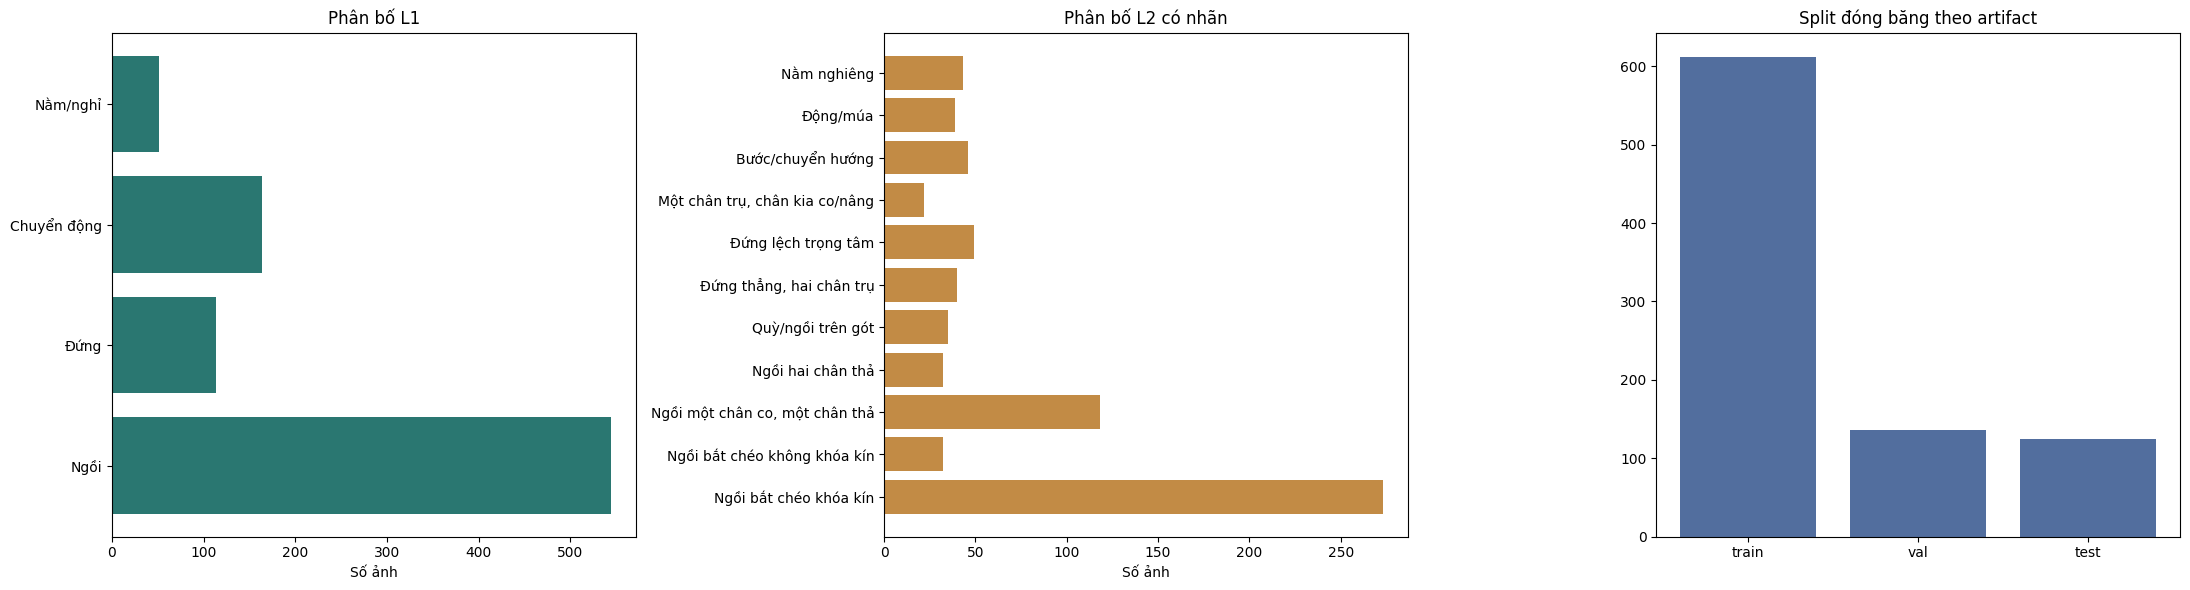

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
l1_counts = Counter(row["level_1_code"] for row in rows)
l2_counts = Counter(row["level_2_code"] for row in rows if row["level_2_code"])
axes[0].barh([l1_names_vi[c] for c in indices["l1_codes"]], [l1_counts[c] for c in indices["l1_codes"]], color="#2a7771")
axes[0].set_title("Phân bố L1")
axes[0].set_xlabel("Số ảnh")
axes[1].barh([l2_names_vi[c] for c in indices["l2_codes"]], [l2_counts[c] for c in indices["l2_codes"]], color="#c28b45")
axes[1].set_title("Phân bố L2 có nhãn")
axes[1].set_xlabel("Số ảnh")
split_order = ["train", "val", "test"]
axes[2].bar(split_order, [audit["split_counts"][s] for s in split_order], color="#526e9e")
axes[2].set_title("Split đóng băng theo artifact")
plt.tight_layout()
plt.show()


**Nhận xét.** Mức chênh lệch giữa các lớp khá lớn: C2.1 có 195 mẫu train, trong khi C2.8 có 16 mẫu; các lớp quỳ/ngồi trên gót, đứng lệch trọng tâm và động/múa lần lượt có 23, 35 và 29 mẫu train. Một số lớp chỉ có 3–6 mẫu validation, làm việc chọn ngưỡng theo lớp dễ biến động.

Tập test L1 có 79 mẫu ngồi, 13 mẫu đứng, 24 mẫu chuyển động và 9 mẫu nằm/nghỉ. Do đó, cần đọc thêm macro-F1, chỉ số tính trung bình ngang nhau giữa các lớp, và kết quả từng lớp. Tăng thời gian huấn luyện không tự bổ sung các biến thể tư thế còn thiếu trong dữ liệu.

## 6. Đánh giá mức đồng thuận gán nhãn

Cell ghép các bản gán nhãn theo cùng định danh mẫu, sau đó tính tỷ lệ trùng nhãn và hệ số kappa. Tỷ lệ trùng nhãn mô tả đồng thuận trực tiếp; kappa điều chỉnh phần đồng thuận có thể xảy ra ngẫu nhiên theo phân bố nhãn. Ma trận đối chiếu giúp xác định những cặp nhãn còn gây bất đồng.

{
  "annotators": [
    "Ngan",
    "My"
  ],
  "n_paired": 873,
  "hierarchical_exact_agreement": 0.9702176403207331,
  "hierarchical_cohen_kappa": 0.9652345724394614,
  "l1_agreement": 1.0,
  "l1_cohen_kappa": 1.0,
  "pairing_key": "image_id"
}


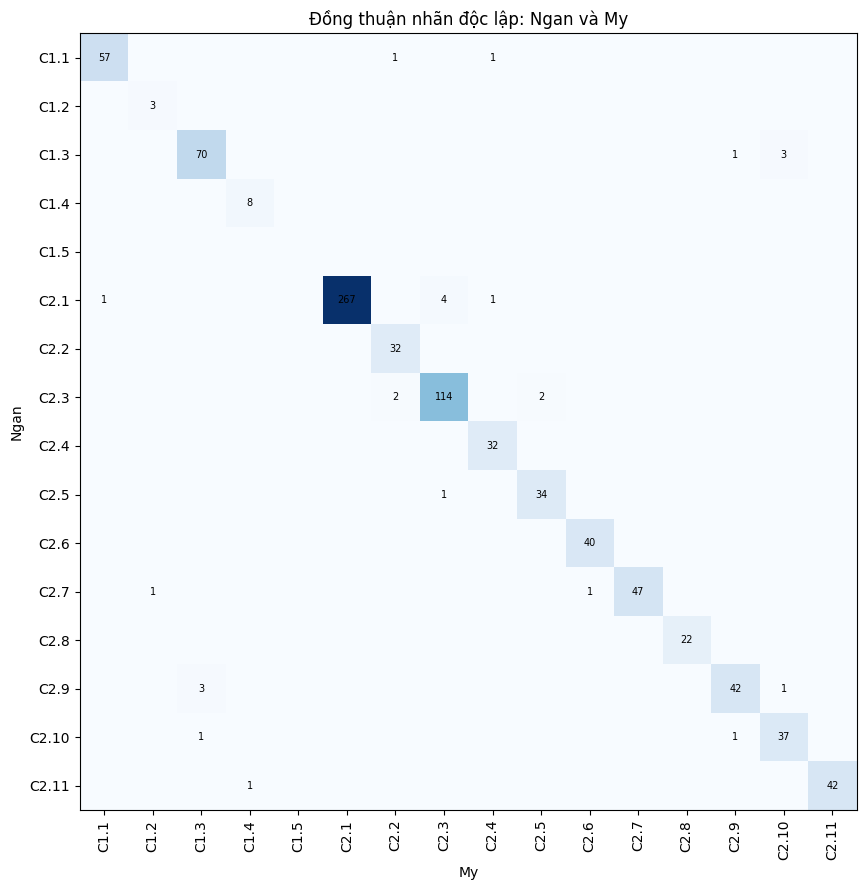

In [6]:
def read_rater_form(path):
    ws = load_workbook(path, data_only=True, read_only=False)["Form"]
    values = {}
    for row_number in range(5, ws.max_row + 1):
        image_id = ws.cell(row_number, 1).value
        label = ws.cell(row_number, 3).value
        if image_id is None and label is None:
            continue
        if image_id is None or label is None:
            raise ValueError(f"Dòng thiếu image_id hoặc label tại {path.name}:{row_number}")
        image_id, label = str(image_id).strip(), str(label).strip()
        if image_id in values:
            raise ValueError(f"Trùng image_id trong {path.name}: {image_id}")
        values[image_id] = label
    return values

ngan_path = RATINGS_DIR / "kappa_form_rater_ngan.xlsx"
my_path = RATINGS_DIR / "kappa_form_rater_my.xlsx"
if not ngan_path.is_file() or not my_path.is_file():
    raise FileNotFoundError(f"Thiếu phiếu gán nhãn: Ngan={ngan_path.is_file()}, My={my_path.is_file()}")
labels_ngan = read_rater_form(ngan_path)
labels_my = read_rater_form(my_path)
assert set(labels_ngan) == set(labels_my), "Phiếu của Ngan và My không có cùng tập image_id."
assert len(labels_ngan) == 873, len(labels_ngan)

valid_codes = set(indices["l1_codes"]) | {"C1.5"} | set(indices["l2_codes"])
invalid_ngan = sorted({v for v in labels_ngan.values() if v not in valid_codes})
invalid_my = sorted({v for v in labels_my.values() if v not in valid_codes})
assert not invalid_ngan and not invalid_my, {"Ngan": invalid_ngan, "My": invalid_my}

common_ids = sorted(labels_ngan)
y_ngan = [labels_ngan[i] for i in common_ids]
y_my = [labels_my[i] for i in common_ids]
to_l1 = lambda code: indices["l2_parent"].get(code, code)
y_ngan_l1 = [to_l1(code) for code in y_ngan]
y_my_l1 = [to_l1(code) for code in y_my]

kappa_summary = {
    "annotators": ["Ngan", "My"],
    "n_paired": len(common_ids),
    "hierarchical_exact_agreement": float(np.mean(np.array(y_ngan) == np.array(y_my))),
    "hierarchical_cohen_kappa": float(cohen_kappa_score(y_ngan, y_my)),
    "l1_agreement": float(np.mean(np.array(y_ngan_l1) == np.array(y_my_l1))),
    "l1_cohen_kappa": float(cohen_kappa_score(y_ngan_l1, y_my_l1)),
    "pairing_key": "image_id",
}
(RUN_ROOT / "inter_rater_agreement.json").write_text(json.dumps(kappa_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(kappa_summary, ensure_ascii=False, indent=2))

all_codes = indices["l1_codes"] + ["C1.5"] + indices["l2_codes"]
cm = confusion_matrix(y_ngan, y_my, labels=all_codes)
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(all_codes)), all_codes, rotation=90)
ax.set_yticks(range(len(all_codes)), all_codes)
ax.set_xlabel("My")
ax.set_ylabel("Ngan")
ax.set_title("Đồng thuận nhãn độc lập: Ngan và My")
for i in range(len(all_codes)):
    for j in range(len(all_codes)):
        if cm[i, j]: ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7)
plt.tight_layout()
plt.show()


**Nhận xét.** Trên 873 cặp, tỷ lệ đồng thuận nhãn phân cấp đạt khoảng 97,02% và kappa đạt 0,9652. Ở L1, cả tỷ lệ đồng thuận và kappa đều bằng 1. Các số liệu cho thấy người gán nhãn áp dụng khá nhất quán hệ thống nhãn trên tập được đối chiếu.

Đồng thuận cao không chứng minh mọi nhãn đều đúng: hai người vẫn có thể cùng áp dụng một cách hiểu chưa phù hợp. Các bất đồng còn lại cần được xem cùng ảnh và quy tắc phân biệt L2, đặc biệt ở tư thế có chân bị che hoặc điểm tựa khó xác định. Đây là hướng kiểm tra, chưa phải nguyên nhân đã được xác nhận cho từng lỗi dự đoán.

## 7. Huấn luyện và lựa chọn mô hình ảnh

Cell huấn luyện ResNet18 và MobileNetV2 với ba seed cho mỗi kiến trúc, sau đó so sánh các mô hình riêng lẻ và tổ hợp dự đoán trên validation. Cấu hình cho phép tối đa 100 epoch, tối thiểu 30 epoch, dừng sớm sau 20 epoch không cải thiện; 5 epoch đầu học phần đầu ra và từ epoch 16 tinh chỉnh toàn bộ mạng. Nhật ký cho biết diễn biến học và thời điểm lưu mô hình tốt nhất.

Hiệu chỉnh xác suất và lựa chọn ngưỡng đều dựa trên validation. Một lớp L2 chỉ được mở nếu đạt điều kiện đã đặt, gồm ít nhất 3 dự đoán được chấp nhận, precision tối thiểu 0,90 và không chấp nhận nhầm L2 trên mẫu để trống L2. Ngưỡng 1,0001 biểu thị lớp bị khóa vì không đạt điều kiện này. Sau khi lựa chọn xong, mô hình được đánh giá trên test.

In [7]:
seed_everything(SEED)
image_run_dir = RUN_ROOT / "image_classifier"
image_run_dir.mkdir(parents=True, exist_ok=True)
loaders, indices = make_loaders(snapshot, batch_size=IMAGE_BATCH_SIZE, seed=SEED)
image_trials, member_outputs, raw_member_outputs, all_members = {}, {}, {}, []
for architecture in IMAGE_ARCHITECTURES:
    for training_seed in IMAGE_SEEDS:
        name = f"{architecture}_seed{training_seed}"
        result = fit_model(snapshot, architecture, image_run_dir / name,
                           epochs=IMAGE_MAX_EPOCHS, patience=IMAGE_PATIENCE,
                           batch_size=IMAGE_BATCH_SIZE, seed=training_seed)
        raw = result["validation_outputs"]
        temperatures = fit_hierarchical_temperatures(raw, indices)
        member = {"architecture": architecture, "seed": training_seed, "checkpoint": result["checkpoint"],
                  "temperatures": temperatures, "best_epoch": result["best_epoch"]}
        all_members.append(member)
        raw_member_outputs[name] = raw
        member_outputs[name] = apply_temperatures(raw, temperatures)
        image_trials[name] = {k: v for k, v in result.items() if k not in ("validation_outputs", "history")}

# Fixed groups: no cherry-picking the best seed. Compare each architecture's three-seed
# ensemble and the equally weighted six-member ensemble, all on validation only.
image_groups = {architecture: [m for m in all_members if m["architecture"] == architecture] for architecture in IMAGE_ARCHITECTURES}
image_groups["all_architectures"] = all_members
image_group_trials = {}
for name, members in image_groups.items():
    member_names = [f"{m['architecture']}_seed{m['seed']}" for m in members]
    out = average_hierarchical_outputs([member_outputs[n] for n in member_names], indices)
    _, l1_choice = l1_rejection_curve(out, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
                                     target_accuracy=L1_TARGET_SELECTIVE_ACCURACY)
    t2, te, tc, choice = select_class_operating_points(out, indices, l1_choice["threshold"])
    quality = decision_quality(out, indices, l1_choice["threshold"], t2, te, tc)
    image_group_trials[name] = {"outputs": out, "quality": quality, "l1_choice": l1_choice,
                                "threshold": t2, "evidence_threshold": te, "class_thresholds": tc, "threshold_choice": choice}
image_architecture = max(image_group_trials, key=lambda name: image_group_trials[name]["quality"]["score"])
chosen = image_group_trials[image_architecture]
image_members = image_groups[image_architecture]
image_val_outputs = chosen["outputs"]
image_val_outputs_raw = average_hierarchical_outputs(
    [raw_member_outputs[f"{m['architecture']}_seed{m['seed']}"] for m in image_members], indices)
image_l1_curve_rows, image_l1_choice = l1_rejection_curve(
    image_val_outputs, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
    target_accuracy=L1_TARGET_SELECTIVE_ACCURACY)
image_l1_threshold = float(image_l1_choice["threshold"])
image_threshold, image_l2_evidence_threshold = chosen["threshold"], chosen["evidence_threshold"]
image_class_thresholds, threshold_choice = chosen["class_thresholds"], chosen["threshold_choice"]
image_c2_2_choice = threshold_choice["per_class"]["C2.2"]
image_temperatures = {"per_member": [m["temperatures"] for m in image_members]}
image_checkpoint = Path(image_members[0]["checkpoint"])
image_selection = {
    "source": "quality_multiseed_ensemble", "architecture": image_architecture, "model_schema": MODEL_SCHEMA,
    "image_size": IMAGE_SIZE, "members": image_members, "manifest_sha256": audit["manifest_sha256"],
    "validation_selection_score": chosen["quality"]["score"],
    "group_comparison": {k: v["quality"] for k, v in image_group_trials.items()},
    "l1_rejection_threshold": image_l1_threshold, "l1_threshold_choice": image_l1_choice,
    "threshold": image_threshold, "l2_fallback_threshold": image_threshold,
    "l2_evidence_threshold": image_l2_evidence_threshold,
    "class_specific_thresholds": image_class_thresholds, "c2_2_threshold_choice": image_c2_2_choice,
    "threshold_choice": threshold_choice, "temperature_scaling": image_temperatures,
}
(image_run_dir / "selection.json").write_text(json.dumps(image_selection, ensure_ascii=False, indent=2), encoding="utf-8")
image_test_outputs = collect_image_members(image_members, loaders["test"], indices)
image_test_metrics = save_test_predictions(image_run_dir / "test_predictions.csv", rows, image_test_outputs, indices,
                                          image_threshold, image_l1_threshold, None, image_l2_evidence_threshold, image_class_thresholds)
(image_run_dir / "test_metrics.json").write_text(json.dumps(image_test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({"ensemble": image_architecture, "validation_score": chosen["quality"]["score"], "test": image_test_metrics}, ensure_ascii=False, indent=2))


resnet18 seed=20261021 epoch=1 batch=40/153
resnet18 seed=20261021 epoch=1 batch=80/153
resnet18 seed=20261021 epoch=1 batch=120/153
resnet18 seed=20261021 epoch=1/100 loss=4.1809 val score=0.1805 best=0.1805
resnet18 seed=20261021 epoch=2 batch=40/153
resnet18 seed=20261021 epoch=2 batch=80/153
resnet18 seed=20261021 epoch=2 batch=120/153
resnet18 seed=20261021 epoch=2/100 loss=4.0384 val score=0.1848 best=0.1848
resnet18 seed=20261021 epoch=3 batch=40/153
resnet18 seed=20261021 epoch=3 batch=80/153
resnet18 seed=20261021 epoch=3 batch=120/153
resnet18 seed=20261021 epoch=3/100 loss=3.8920 val score=0.2549 best=0.2549
resnet18 seed=20261021 epoch=4 batch=40/153
resnet18 seed=20261021 epoch=4 batch=80/153
resnet18 seed=20261021 epoch=4 batch=120/153
resnet18 seed=20261021 epoch=4/100 loss=3.7821 val score=0.2799 best=0.2799
resnet18 seed=20261021 epoch=5 batch=40/153
resnet18 seed=20261021 epoch=5 batch=80/153
resnet18 seed=20261021 epoch=5 batch=120/153
resnet18 seed=20261021 epoch=5/

**Nhận xét.** Tổ hợp ba mô hình ResNet18 được chọn trong lần chạy đã lưu. Trên test, accuracy L1 đạt 90,40% (113/125), macro-F1 đạt 0,8546. Đây là chất lượng phân loại nhóm tư thế trước khi xét đầy đủ cơ chế từ chối và trả nhãn chi tiết.

Khi cung cấp sẵn L1 đúng, accuracy L2 đạt 77,67% (80/103 mẫu có nhãn L2). Đây là đánh giá có điều kiện, thường gọi là *oracle*, nên không thể coi là độ chính xác L2 của demo. Trong toàn bộ quy trình, chỉ 37/103 mẫu được trả L2, trong đó 33 mẫu đúng: độ chính xác trên phần được chấp nhận là 89,19%, còn tỷ lệ trả đúng L2 trên toàn bộ 103 mẫu là 32,04%.

Khoảng cách này cho thấy hạn chế nằm ở cả phân biệt tư thế và điều kiện trả nhãn. Các lớp ít mẫu validation khó đáp ứng tiêu chí mở lớp một cách ổn định. Dừng sớm nhằm hạn chế học quá khớp; chạy thêm epoch không bảo đảm giải quyết được thiếu dữ liệu hoặc nhầm lẫn hình thái.

## 8. Đọc ma trận nhầm lẫn của mô hình ảnh

Cell trực quan hóa kết quả dự đoán để xác định nhóm tư thế thường bị nhầm. Với ma trận L1, cần đọc số dự đoán đúng trên đường chéo và số nhầm sang từng nhóm ở ngoài đường chéo. Ma trận L2 có điều kiện sử dụng L1 chuẩn, vì vậy cần tách cách diễn giải của nó khỏi kết quả toàn bộ quy trình.

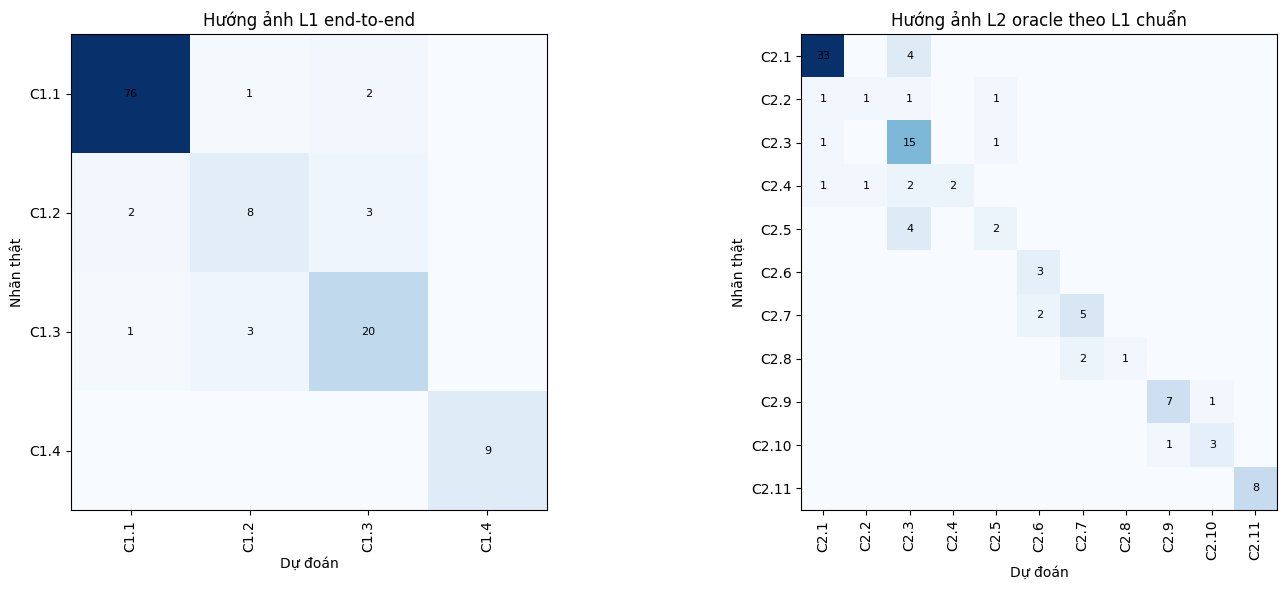

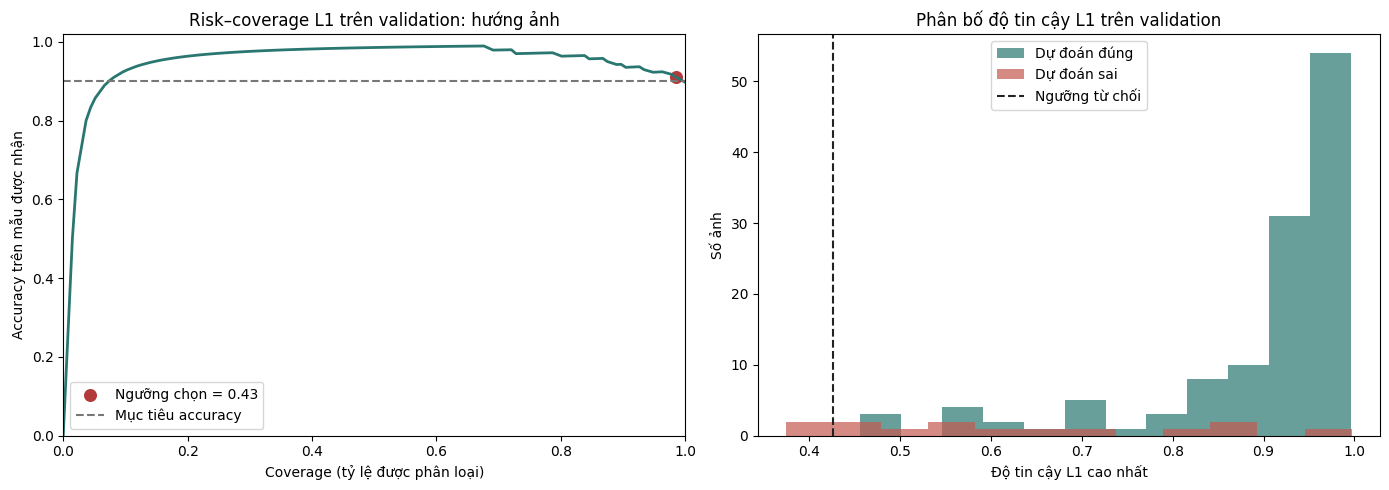

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
matrices = [image_test_metrics["l1_all_test"]["confusion_matrix"], image_test_metrics["l2_oracle_given_gold_l1"]["confusion_matrix"]]
labels = [indices["l1_codes"], indices["l2_codes"]]
titles = ["Hướng ảnh L1 end-to-end", "Hướng ảnh L2 oracle theo L1 chuẩn"]
for ax, matrix, codes, title in zip(axes, matrices, labels, titles):
    matrix = np.array(matrix)
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn thật")
    ax.set_xticks(range(len(codes)), codes, rotation=90); ax.set_yticks(range(len(codes)), codes)
    for i in range(len(codes)):
        for j in range(len(codes)):
            if matrix[i, j]: ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

image_l1_curve_df = pd.DataFrame(image_l1_curve_rows)
image_val_prob = torch.softmax(torch.tensor(image_val_outputs["l1_logits"]), dim=1).numpy()
image_val_conf = image_val_prob.max(axis=1)
image_val_correct = image_val_prob.argmax(axis=1) == image_val_outputs["y1"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(image_l1_curve_df["coverage"], image_l1_curve_df["selective_accuracy"], color="#2a7771", linewidth=2)
axes[0].scatter([image_l1_choice["coverage"]], [image_l1_choice["selective_accuracy"]], color="#b33a3a", s=70, label=f"Ngưỡng chọn = {image_l1_threshold:.2f}")
axes[0].axhline(L1_TARGET_SELECTIVE_ACCURACY, color="#777777", linestyle="--", label="Mục tiêu accuracy")
axes[0].set_xlabel("Coverage (tỷ lệ được phân loại)"); axes[0].set_ylabel("Accuracy trên mẫu được nhận")
axes[0].set_title("Risk–coverage L1 trên validation: hướng ảnh"); axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.02); axes[0].legend()
axes[1].hist(image_val_conf[image_val_correct], bins=12, alpha=0.7, label="Dự đoán đúng", color="#2a7771")
axes[1].hist(image_val_conf[~image_val_correct], bins=12, alpha=0.7, label="Dự đoán sai", color="#c45a4f")
axes[1].axvline(image_l1_threshold, color="#222222", linestyle="--", label="Ngưỡng từ chối")
axes[1].set_xlabel("Độ tin cậy L1 cao nhất"); axes[1].set_ylabel("Số ảnh")
axes[1].set_title("Phân bố độ tin cậy L1 trên validation"); axes[1].legend()
plt.tight_layout()
plt.show()


**Nhận xét.** Nhóm đứng chỉ nhận đúng 8/13 mẫu: 2 mẫu bị nhầm sang ngồi và 3 mẫu sang chuyển động. Đây là bằng chứng trực tiếp cho thấy ranh giới giữa các nhóm này còn yếu. Nhóm nằm/nghỉ nhận đúng 9/9 mẫu trong test, nhưng số mẫu nhỏ nên chưa đủ để khẳng định mọi ảnh nằm nghiêng ngoài tập đều được nhận đúng.

Ở L2 có điều kiện, quỳ/ngồi trên gót chỉ đúng 2/6 mẫu, còn ngồi một chân co, một chân thả đúng 15/17 mẫu. Nhánh nằm/nghỉ chỉ có một lớp con là nằm nghiêng; kết quả L2 hoàn hảo trong nhánh này không chứng minh mô hình phân biệt được nằm nghiêng với mọi tư thế khác. Muốn xác định nguyên nhân của một ảnh cụ thể bị nhận sai cần kiểm tra chính ảnh đó và đầu ra của từng bước.

Đồ thị tiếp theo sử dụng validation để biểu diễn sự đánh đổi giữa tỷ lệ mẫu được nhận và độ chính xác trên các mẫu đó. Histogram đặt độ tin cậy của dự đoán đúng và sai cạnh nhau để kiểm tra khả năng phân tách bằng ngưỡng. Một ngưỡng chọn trên validation không bảo đảm đạt cùng độ chính xác trên test hoặc ảnh mới.


## 9. Chuẩn bị dữ liệu ước lượng điểm khớp

Cell chuyển dữ liệu ảnh, hộp giới hạn và điểm khớp sang định dạng huấn luyện YOLO Pose, đồng thời giữ phép chia tập đã xác định. Điểm khớp được đánh dấu theo mức nhìn thấy hoặc khả năng định vị. Dữ liệu chuẩn bị ở bước này phục vụ học hình học cơ thể, chưa phải đầu ra phân loại tư thế L1/L2.

In [9]:
def safe_stem(text):
    return "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in text)

def build_pose_dataset(data_dir, manifest_rows, coco, output_dir):
    marker = output_dir / "dataset.yaml"
    if marker.is_file() and REUSE_EXISTING:
        return marker
    if output_dir.exists():
        shutil.rmtree(output_dir)
    row_by_image = {row["image_id"]: row for row in manifest_rows}
    image_by_id = {int(image["id"]): image for image in coco["images"]}
    anns_by_image = {int(ann["image_id"]): ann for ann in coco["annotations"]}
    records = []
    for image_id, image in image_by_id.items():
        ann = anns_by_image[image_id]
        original_id = image["original_image_id"]
        if original_id not in row_by_image:
            raise KeyError(f"Không ghép được COCO image với manifest: {original_id}")
        row = row_by_image[original_id]
        split = "val" if row["split"] == "val" else row["split"]
        image_dir = output_dir / "images" / split
        label_dir = output_dir / "labels" / split
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        source = data_dir / row["crop_path"]
        stem = safe_stem(row["instance_id"])
        destination = image_dir / (stem + source.suffix.lower())
        shutil.copy2(source, destination)
        crop_x, crop_y, crop_w, crop_h = json.loads(row["crop_extent_xywh"])
        bbox_x, bbox_y, bbox_w, bbox_h = [float(ann["bbox"][i]) for i in range(4)]
        xc = ((bbox_x - crop_x) + bbox_w / 2) / crop_w
        yc = ((bbox_y - crop_y) + bbox_h / 2) / crop_h
        bw, bh = bbox_w / crop_w, bbox_h / crop_h
        yolo_fields = [0, np.clip(xc, 0, 1), np.clip(yc, 0, 1), np.clip(bw, 1e-6, 1), np.clip(bh, 1e-6, 1)]
        adjusted_gt = []
        kp = ann["keypoints"]
        for index in range(0, len(kp), 3):
            x, y, visibility = float(kp[index]), float(kp[index + 1]), int(kp[index + 2])
            xn, yn = (x - crop_x) / crop_w, (y - crop_y) / crop_h
            if visibility > 0 and not (0 <= xn <= 1 and 0 <= yn <= 1):
                visibility = 0
            xn, yn = float(np.clip(xn, 0, 1)), float(np.clip(yn, 0, 1))
            yolo_fields.extend([xn, yn, visibility])
            adjusted_gt.append([xn, yn, visibility])
        (label_dir / (stem + ".txt")).write_text(" ".join(map(str, yolo_fields)) + "\n", encoding="utf-8")
        records.append({"image_id": original_id, "instance_id": row["instance_id"], "split": row["split"],
                        "file": str(destination), "bbox_norm": [xc, yc, bw, bh], "keypoints_norm": adjusted_gt})
    yaml_text = (
        f'path: "{output_dir.resolve().as_posix()}"\n'
        "train: images/train\nval: images/val\ntest: images/test\n"
        "kpt_shape: [17, 3]\n"
        "flip_idx: [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]\n"
        "names:\n  0: figure\n"
    )
    marker.write_text(yaml_text, encoding="utf-8")
    (output_dir / "records.json").write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
    return marker

pose_dataset_dir = CACHE_DIR / "formal_pose_yolo"
pose_yaml = build_pose_dataset(DATA_DIR, rows, full_coco, pose_dataset_dir)
pose_records = json.loads((pose_dataset_dir / "records.json").read_text(encoding="utf-8"))
print("Pose records:", len(pose_records), Counter(r["split"] for r in pose_records))


Pose records: 612 Counter({'train': 442, 'val': 88, 'test': 82})


**Giải thích đầu ra.** Các đường dẫn và thống kê cho biết dữ liệu đã được xuất sang cấu trúc mà bộ ước lượng tư thế sử dụng. Số mẫu đủ điểm khớp có thể nhỏ hơn số mẫu phân loại; vì vậy, không mặc nhiên so sánh các chỉ số của hai nhiệm vụ trên cùng một mẫu số.

Chuyển đổi định dạng đúng không bảo đảm vị trí khớp gán nhãn hoàn toàn chính xác. Những điểm bị che nhưng vẫn được định vị có thể chứa sai số gán nhãn; cần kiểm tra ảnh khi phát hiện sai lệch hình học lớn.

## 10. Nạp hoặc huấn luyện bộ ước lượng tư thế

Cell kiểm tra điều kiện tái sử dụng mô hình tư thế đã lưu. Nếu có mô hình phù hợp với dữ liệu và cấu hình kiểm tra, chương trình nạp lại để đánh giá; nếu cần huấn luyện mới, chương trình thực hiện nhánh huấn luyện tương ứng. Nguồn trọng số được ghi lại để tránh nhầm kết quả tái sử dụng với một thí nghiệm huấn luyện mới.

In [10]:
import gc
pose_inference_batch_size = globals().get("POSE_INFERENCE_BATCH_SIZE", 1)
pose_run_dir = RUN_ROOT / "pose_estimator"
pose_run_dir.mkdir(parents=True, exist_ok=True)
cached_pose_checkpoint = OUTPUTS_DIR / "pose_baseline" / "best.pt"
cached_pose_config = OUTPUTS_DIR / "pose_baseline" / "config.json"
pretrained_pose = PRETRAINED_DIR / "yolo11n-pose.pt"
if not pretrained_pose.is_file():
    raise FileNotFoundError("Thiếu pretrained/yolo11n-pose.pt. Không tự tải để giữ khả năng tái lập offline.")

can_reuse_pose = False
if REUSE_EXISTING and not FORCE_RETRAIN_POSE and cached_pose_checkpoint.is_file() and cached_pose_config.is_file():
    pose_cache_config = json.loads(cached_pose_config.read_text(encoding="utf-8"))
    can_reuse_pose = pose_cache_config.get("manifest_sha256") == audit["manifest_sha256"]
if can_reuse_pose:
    pose_checkpoint = cached_pose_checkpoint
    pose_training_source = "cached_formal_pose_baseline"
else:
    base_pose_model = YOLO(str(pretrained_pose))
    pose_result = base_pose_model.train(
        data=str(pose_yaml), epochs=POSE_EPOCHS, patience=POSE_PATIENCE,
        imgsz=POSE_IMAGE_SIZE, batch=POSE_BATCH_SIZE, seed=SEED,
        project=str(pose_run_dir.resolve()), name="yolo11n_pose_formal",
        device=0 if DEVICE == "cuda" else "cpu", workers=0,
        pretrained=True, deterministic=True, exist_ok=False, verbose=True,
    )
    pose_save_dir = Path(pose_result.save_dir)
    pose_checkpoint = pose_save_dir / "weights" / "best.pt"
    if not pose_checkpoint.is_file():
        pose_checkpoint = pose_save_dir / "weights" / "last.pt"
    cached_pose_checkpoint.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(pose_checkpoint, cached_pose_checkpoint)
    cached_pose_config.write_text(json.dumps({
        "dataset_version": audit["dataset_version"],
        "manifest_sha256": audit["manifest_sha256"],
        "seed": SEED, "epochs": POSE_EPOCHS, "imgsz": POSE_IMAGE_SIZE,
        "batch": POSE_BATCH_SIZE, "base_weights": pretrained_pose.name,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    pose_checkpoint = cached_pose_checkpoint
    pose_training_source = "trained_in_notebook"

# The 4 GB GPU cannot hold the image classifier and YOLO-Pose validation
# buffers at the same time. Keep the already-evaluated image model on CPU;
# it is only used once more by the final demo.
if DEVICE == "cuda":
    gc.collect()
    torch.cuda.empty_cache()

pose_model = YOLO(str(pose_checkpoint))
pose_val_result = pose_model.val(
    project=str(pose_run_dir.resolve()), name="geometry_test", exist_ok=True,
    data=str(pose_yaml), split="test", imgsz=POSE_IMAGE_SIZE,
    batch=pose_inference_batch_size, device=0 if DEVICE == "cuda" else "cpu",
    half=DEVICE == "cuda",
    workers=0, verbose=False,
)
pose_ultralytics_metrics = {
    "training_source": pose_training_source,
    "checkpoint": str(pose_checkpoint),
    "pose_map50_95": float(getattr(pose_val_result.pose, "map", float("nan"))),
    "pose_map50": float(getattr(pose_val_result.pose, "map50", float("nan"))),
    "pose_map75": float(getattr(pose_val_result.pose, "map75", float("nan"))),
    "box_map50_95": float(getattr(pose_val_result.box, "map", float("nan"))),
}
del pose_val_result
# Validation builds an inference backend. Reload a clean checkpoint for
# feature extraction instead of moving that backend between devices.
del pose_model
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
pose_model = YOLO(str(pose_checkpoint))
print(json.dumps(pose_ultralytics_metrics, ensure_ascii=False, indent=2))


Ultralytics 8.3.215  Python-3.10.11 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLO11n-pose summary (fused): 109 layers, 2,866,468 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 470.8273.7 MB/s, size: 318.3 KB)
val: Scanning I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\cache\formal_pose_yolo\labels\test.cache... 82 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 82/82  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 82/82 1.0it/s 1:250.8sss
                   all         82         82      0.997          1      0.995      0.958      0.973      0.976      0.984       0.79
Speed: 1.6ms preprocess, 997.6ms inference, 0.0ms loss, 4.1ms postprocess per image
Results saved to I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\outputs\notebook_runs\20261031_174817_seed20261021\pose_estim

**Nhận xét.** Lần chạy hiện tại tái sử dụng mô hình qua nhánh `cached_formal_pose_baseline`. Vì vậy, các số liệu ở đây không phải bằng chứng rằng bộ ước lượng điểm khớp đã được huấn luyện lại trong lần nâng cấp này. Pose mAP50–95 đạt khoảng 0,7898; mAP50 đạt 0,9842 và mAP75 đạt 0,8567.

Điểm số giảm khi tiêu chuẩn khớp nghiêm ngặt hơn cho thấy việc xác định gần đúng vị trí cơ thể dễ hơn xác định chính xác các khớp. mAP của bộ ước lượng tư thế không trực tiếp đo khả năng phân biệt quỳ, đứng lệch trọng tâm hay động/múa; nhiệm vụ đó được đánh giá ở bộ phân loại phía sau.

## 11. Trích xuất điểm khớp dự đoán

Mô hình tư thế được áp dụng để tạo dữ liệu điểm khớp dự đoán cho các tập. Kết quả được lưu vào bộ nhớ đệm nhằm tái sử dụng khi thử các bộ phân loại khác nhau. Cách làm này giúp đánh giá phân loại trên hình học mà mô hình thực sự suy ra từ ảnh.

In [11]:
import gc
pose_inference_batch_size = globals().get("POSE_INFERENCE_BATCH_SIZE", 1)
pose_feature_device = "cuda" if DEVICE == "cuda" else "cpu"

def _extract_pose_features_once(model, manifest_rows, batch_size, inference_device):
    # A list of paths makes this Ultralytics version decode every image up
    # front with LoadPilAndNumpy. Some source images are very large, so that
    # exhausts system RAM. Passing one path string at a time streams from disk.
    use_cuda = inference_device != "cpu"
    features, metadata = [], []
    total = len(manifest_rows)
    for index, row in enumerate(manifest_rows):
        path = str(DATA_DIR / row["crop_path"])
        results = model.predict(
            source=path, imgsz=POSE_IMAGE_SIZE, batch=1,
            device=inference_device, workers=0, half=use_cuda, max_det=1,
            verbose=False, stream=False,
        )
        if len(results) != 1:
            raise RuntimeError(f"Expected one pose result for {path}, got {len(results)}")
        result = results[0]
        feature = np.zeros(17 * 3 + 2, dtype=np.float32)
        detected = False
        if result.boxes is not None and len(result.boxes) and result.keypoints is not None:
            confs = result.boxes.conf.detach().cpu().numpy()
            best = int(np.argmax(confs))
            xy = result.keypoints.xyn[best].detach().cpu().numpy()
            if result.keypoints.conf is not None:
                kp_conf = result.keypoints.conf[best].detach().cpu().numpy()
            else:
                kp_conf = np.ones(17, dtype=np.float32)
            feature[:51] = np.column_stack([xy, kp_conf]).reshape(-1)
            feature[51] = float(confs[best])
            feature[52] = 1.0
            detected = True
            bbox_xywhn = result.boxes.xywhn[best].detach().cpu().numpy().astype(float).tolist()
        else:
            bbox_xywhn = None
        features.append(feature)
        metadata.append({"image_id": row["image_id"], "instance_id": row["instance_id"],
                         "split": row["split"], "detected": detected,
                         "bbox_xywhn": bbox_xywhn})
        del result, results
        if (index + 1) % 50 == 0 or index + 1 == total:
            print(f"Pose inference: {index + 1}/{total}")
    return np.stack(features), metadata

def extract_pose_features(model, manifest_rows, batch_size=1):
    global pose_model, pose_feature_device
    inference_device = 0 if DEVICE == "cuda" else "cpu"
    if DEVICE == "cuda":
        gc.collect()
        torch.cuda.empty_cache()
    try:
        return _extract_pose_features_once(model, manifest_rows, batch_size, inference_device)
    except RuntimeError as exc:
        if DEVICE != "cuda" or "out of memory" not in str(exc).lower():
            raise
        warnings.warn("GPU thiếu bộ nhớ khi trích keypoint; nạp lại checkpoint sạch và tiếp tục trên CPU.")
        model.predictor = None
        del model
        gc.collect()
        torch.cuda.empty_cache()
        pose_model = YOLO(str(pose_checkpoint))
        pose_feature_device = "cpu"
        return _extract_pose_features_once(pose_model, manifest_rows, 1, "cpu")

pose_feature_cache = CACHE_DIR / "predicted_pose_features.npz"
pose_metadata_cache = CACHE_DIR / "predicted_pose_metadata.json"
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

pose_checkpoint_sha256 = file_sha256(pose_checkpoint)
pose_cache_metadata = (json.loads(pose_metadata_cache.read_text(encoding="utf-8"))
                       if pose_metadata_cache.is_file() else {})
can_reuse_features = (
    REUSE_EXISTING and not FORCE_RETRAIN_POSE and pose_feature_cache.is_file()
    and pose_cache_metadata.get("checkpoint_sha256") == pose_checkpoint_sha256
    and pose_cache_metadata.get("manifest_sha256") == audit["manifest_sha256"]
    and pose_cache_metadata.get("record_count") == len(rows)
    and pose_cache_metadata.get("cache_schema") == 2
)
if can_reuse_features:
    pose_features = np.load(pose_feature_cache)["features"]
    pose_feature_metadata = pose_cache_metadata["records"]
else:
    # Release allocations and traceback frames left by earlier failed runs.
    for attr in ("last_traceback", "last_value", "last_type"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    if DEVICE == "cuda":
        pose_model.predictor = None
        gc.collect()
        torch.cuda.empty_cache()
    # Running this cell again must not reuse the backend left by val() or a failed inference.
    del pose_model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    pose_model = YOLO(str(pose_checkpoint))
    pose_features, pose_feature_metadata = extract_pose_features(
        pose_model, rows, pose_inference_batch_size
    )
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(pose_feature_cache, features=pose_features)
    pose_metadata_cache.write_text(json.dumps({
        "checkpoint_sha256": pose_checkpoint_sha256,
        "manifest_sha256": audit["manifest_sha256"],
        "record_count": len(rows),
        "cache_schema": 2,
        "records": pose_feature_metadata,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
assert len(pose_features) == len(rows)
print("Tỷ lệ phát hiện nhân vật:", np.mean([m["detected"] for m in pose_feature_metadata]))


Tỷ lệ phát hiện nhân vật: 1.0


**Nhận xét.** Tỷ lệ phát hiện được ghi nhận là 100% trong đầu ra đã lưu. Điều này cho biết mô hình tìm được đối tượng theo tiêu chí phát hiện đang dùng; không có nghĩa toàn bộ vai, hông, gối và cổ chân đều nằm đúng vị trí.

Sai số ở gối và cổ chân có thể làm thay đổi góc chân hoặc quan hệ giữa hai chân, vốn là thông tin quan trọng để phân biệt các tư thế gần nhau. Mức sai số thực tế cần được đọc từ phép đánh giá hình học tiếp theo, thay vì suy ra từ tỷ lệ phát hiện.

## 12. Đánh giá độ chính xác hình học

Cell so sánh điểm khớp dự đoán với nhãn chuẩn bằng PCK và OKS. PCK đo tỷ lệ điểm nằm trong khoảng sai số cho phép; OKS tổng hợp mức tương đồng vị trí có xét quy mô đối tượng và độ nhạy theo loại khớp. Phiên bản chỉ số hiện tại tính trong tọa độ pixel, sử dụng diện tích hộp giới hạn làm đại diện quy mô và hệ số COCO `(2σ)²` cho OKS.

Phép tính dùng các khớp có cờ nhãn lớn hơn 0, bao gồm cả khớp bị che nhưng vẫn định vị được. Bảng theo lớp và vùng thân dưới giúp kiểm tra liệu chỉ số trung bình có che khuất sai số ở những tư thế khó hay không.

{
  "training_source": "cached_formal_pose_baseline",
  "checkpoint": "I:\\nam4\\phan tich anh phat giao\\training\\Thangka_Pose_Training\\outputs\\pose_baseline\\best.pt",
  "pose_map50_95": 0.7897520854580917,
  "pose_map50": 0.9841986531986531,
  "pose_map75": 0.8566573065759272,
  "box_map50_95": 0.9578562282250932,
  "test_full_keypoint_images": 82,
  "test_detection_rate": 1.0,
  "mean_bbox_iou": 0.8538573000002392,
  "pck_at_0_05_bbox_diagonal": 0.7862266857962698,
  "pck_visible_keypoints": 1394,
  "mean_oks": 0.8852506298351936,
  "oks_definition": "COCO (2*sigma)^2; pixel coordinates; bbox-area proxy; annotated ground-truth keypoints (v>0); metric schema 2, not comparable directly with old normalized-space scores"
}


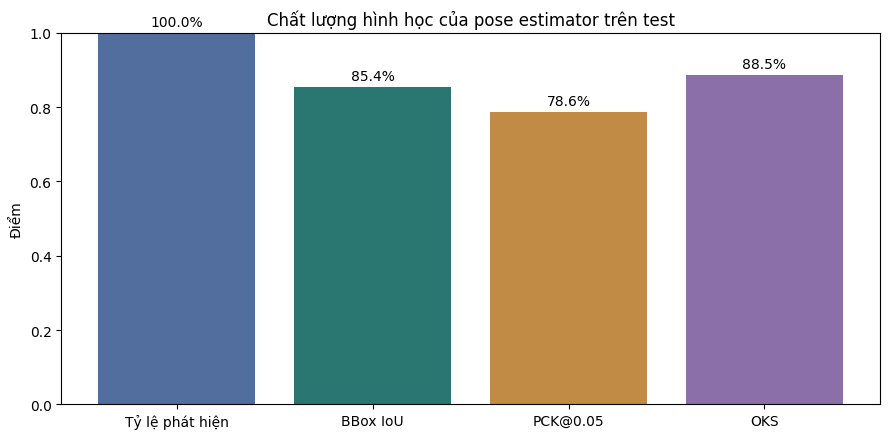

In [12]:
COCO_SIGMAS = np.array([.26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89]) / 10.0
def bbox_iou_xywhn(a, b):
    ax, ay, aw, ah = map(float, a); bx, by, bw, bh = map(float, b)
    a_box = [ax - aw / 2, ay - ah / 2, ax + aw / 2, ay + ah / 2]
    b_box = [bx - bw / 2, by - bh / 2, bx + bw / 2, by + bh / 2]
    inter_w = max(0.0, min(a_box[2], b_box[2]) - max(a_box[0], b_box[0]))
    inter_h = max(0.0, min(a_box[3], b_box[3]) - max(a_box[1], b_box[1]))
    intersection = inter_w * inter_h
    union = aw * ah + bw * bh - intersection
    return intersection / union if union > 0 else 0.0

gt_pose_by_image = {record["image_id"]: record for record in pose_records if record["split"] == "test"}
feature_by_image = {row["image_id"]: pose_features[i] for i, row in enumerate(rows)}
metadata_by_image = {record["image_id"]: record for record in pose_feature_metadata}
pck_hits, pck_total, oks_values, bbox_ious, detected_pose_test = 0, 0, [], [], 0
for image_id, gt in gt_pose_by_image.items():
    feature = feature_by_image[image_id]
    if feature[52] > 0:
        detected_pose_test += 1
        predicted_bbox = metadata_by_image[image_id].get("bbox_xywhn")
        if predicted_bbox is not None:
            bbox_ious.append(bbox_iou_xywhn(gt["bbox_norm"], predicted_bbox))
    pred = feature[:51].reshape(17, 3)
    gt_kp = np.array(gt["keypoints_norm"], dtype=float)
    visible = gt_kp[:, 2] > 0
    if not visible.any():
        continue
    row = next(r for r in rows if r["image_id"] == image_id)
    crop_size = (float(row["crop_width"]), float(row["crop_height"]))
    hits, visible, oks = pose_geometry_scores(pred, gt_kp, gt["bbox_norm"], crop_size)
    pck_hits += int(hits.sum())
    pck_total += int(visible.sum())
    if oks is not None:
        oks_values.append(oks)

pose_geometry_metrics = {
    **pose_ultralytics_metrics,
    "test_full_keypoint_images": len(gt_pose_by_image),
    "test_detection_rate": detected_pose_test / max(len(gt_pose_by_image), 1),
    "mean_bbox_iou": float(np.mean(bbox_ious)) if bbox_ious else None,
    "pck_at_0_05_bbox_diagonal": pck_hits / max(pck_total, 1),
    "pck_visible_keypoints": pck_total,
    "mean_oks": float(np.mean(oks_values)) if oks_values else None,
    "oks_definition": "COCO (2*sigma)^2; pixel coordinates; bbox-area proxy; annotated ground-truth keypoints (v>0); metric schema 2, not comparable directly with old normalized-space scores",
}
(pose_run_dir / "test_pose_metrics.json").write_text(json.dumps(pose_geometry_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(pose_geometry_metrics, ensure_ascii=False, indent=2))
pose_plot_values = {
    "Tỷ lệ phát hiện": pose_geometry_metrics["test_detection_rate"],
    "BBox IoU": pose_geometry_metrics["mean_bbox_iou"] or 0.0,
    "PCK@0.05": pose_geometry_metrics["pck_at_0_05_bbox_diagonal"],
    "OKS": pose_geometry_metrics["mean_oks"] or 0.0,
}
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(pose_plot_values.keys(), pose_plot_values.values(), color=["#526e9e", "#2a7771", "#c28b45", "#8b6fa8"])
ax.set_ylim(0, 1); ax.set_ylabel("Điểm"); ax.set_title("Chất lượng hình học của pose estimator trên test")
ax.bar_label(bars, labels=[f"{value:.1%}" for value in pose_plot_values.values()], padding=3)
plt.tight_layout()
plt.show()

# Per-class validation diagnostics reveal whether hip/knee/ankle geometry is the bottleneck.
pose_diagnostics = []
row_by_image = {r["image_id"]: r for r in rows}
for gt in pose_records:
    if gt["split"] not in ("val", "test"):
        continue
    row = row_by_image[gt["image_id"]]
    pred = feature_by_image[gt["image_id"]][:51].reshape(17, 3)
    hits, visible, oks = pose_geometry_scores(pred, gt["keypoints_norm"], gt["bbox_norm"],
                                             (row["crop_width"], row["crop_height"]))
    pose_diagnostics.append({"image_id": gt["image_id"], "split": gt["split"], "l2_code": row["level_2_code"],
                             "lower_body_hits": int(hits[11:17].sum()), "lower_body_support": int(visible[11:17].sum()),
                             "pck_hits": int(hits.sum()), "pck_support": int(visible.sum()), "oks_bbox_area": oks})
pd.DataFrame(pose_diagnostics).to_csv(pose_run_dir / "geometry_by_image.csv", index=False)
pose_class_rows = []
for (split, code), group in pd.DataFrame(pose_diagnostics).groupby(["split", "l2_code"]):
    pose_class_rows.append({"split": split, "l2_code": code, "images": len(group),
                           "lower_body_pck": group.lower_body_hits.sum() / max(group.lower_body_support.sum(), 1),
                           "pck": group.pck_hits.sum() / max(group.pck_support.sum(), 1)})
pd.DataFrame(pose_class_rows).to_csv(pose_run_dir / "geometry_by_class.csv", index=False)


**Nhận xét.** Trên 82 ảnh test đủ 17 điểm khớp, PCK đạt 0,7862 trên 1.394 điểm và OKS trung bình đạt 0,8853; IoU hộp giới hạn trung bình đạt 0,8539. Các số này chỉ phản ánh tập con được đánh giá hình học, không phải toàn bộ 125 mẫu test phân loại.

PCK thân dưới thấp ở một số lớp cần cải thiện: quỳ/ngồi trên gót đạt 0,3750 trên 4 ảnh, đứng lệch trọng tâm đạt 0,4524 trên 7 ảnh, động/múa đạt 0,4583 trên 4 ảnh và nằm nghiêng đạt 0,2500 trên 2 ảnh. Đây là bằng chứng về hạn chế định vị chân, nhưng số ảnh nhỏ và chưa có thí nghiệm thay thế điểm khớp dự đoán bằng điểm chuẩn để định lượng riêng tác động lên phân loại.

Do công thức hình học đã được sửa sang phiên bản hiện tại, không diễn giải chênh lệch với số liệu tính theo công thức chuẩn hóa cũ như một mức cải thiện do huấn luyện.

## 13. Phân loại từ điểm khớp và lựa chọn phương án sử dụng

Cell tạo 100 đặc trưng từ điểm khớp, trong đó sử dụng tỷ lệ khung ảnh để tránh làm sai hình học khi chuẩn hóa hai trục. Các đặc trưng mô tả vị trí, góc và quan hệ giữa các bộ phận. Ba cấu hình Logistic Regression, Random Forest và Extra Trees được so sánh trên validation; nhãn L2 để trống được xử lý riêng theo cơ chế bằng chứng và từ chối.

Sau đó, chương trình so sánh các trọng số kết hợp dự đoán ảnh với dự đoán từ điểm khớp. Phương án sử dụng và các ngưỡng đều được chốt bằng validation trước khi báo cáo test. Bảng theo lớp tập trung vào những tư thế đang gặp lỗi; phần đối chiếu lịch sử chỉ mô tả thay đổi giữa các lần chạy.

In [13]:
def _joint_angle_cos(xy, confidence, first, middle, last):
    if min(confidence[first], confidence[middle], confidence[last]) < 0.05:
        return 0.0
    left = xy[first] - xy[middle]
    right = xy[last] - xy[middle]
    denominator = np.linalg.norm(left) * np.linalg.norm(right)
    return float(np.dot(left, right) / denominator) if denominator > 1e-8 else 0.0


def engineer_pose_features(raw_features):
    """Add translation/scale-invariant geometry while retaining original pose evidence."""
    raw_features = np.asarray(raw_features, dtype=np.float32)
    engineered = []
    for raw in raw_features:
        joints = raw[:51].reshape(17, 3)
        xy, confidence = joints[:, :2].copy(), joints[:, 2].copy()
        if len(raw) != 54 or not np.isfinite(raw[53]) or raw[53] <= 0:
            raise ValueError("Pose geometry requires 53 pose fields plus positive crop width/height ratio.")
        # x and y were normalized by DIFFERENT lengths. Restore isotropic geometry
        # before measuring angles; keep original normalized coordinates as separate features.
        xy[:, 0] *= raw[53]
        valid = confidence >= 0.05
        if valid[11] and valid[12]:
            center = (xy[11] + xy[12]) / 2.0
        elif valid.any():
            center = xy[valid].mean(axis=0)
        else:
            center = np.zeros(2, dtype=np.float32)
        if valid.any():
            span = xy[valid].max(axis=0) - xy[valid].min(axis=0)
            scale = max(float(np.linalg.norm(span)), 1e-3)
        else:
            scale = 1.0
        relative_xy = (xy - center) / scale
        relative_xy[~valid] = 0.0
        shoulder_mid = (xy[5] + xy[6]) / 2.0 if valid[5] and valid[6] else center
        hip_mid = (xy[11] + xy[12]) / 2.0 if valid[11] and valid[12] else center
        geometry = np.asarray([
            _joint_angle_cos(xy, confidence, 5, 11, 13),
            _joint_angle_cos(xy, confidence, 6, 12, 14),
            _joint_angle_cos(xy, confidence, 11, 13, 15),
            _joint_angle_cos(xy, confidence, 12, 14, 16),
            (shoulder_mid[0] - hip_mid[0]) / scale,
            (shoulder_mid[1] - hip_mid[1]) / scale,
            np.linalg.norm(xy[5] - xy[6]) / scale if valid[5] and valid[6] else 0.0,
            np.linalg.norm(xy[11] - xy[12]) / scale if valid[11] and valid[12] else 0.0,
            np.linalg.norm(xy[13] - xy[14]) / scale if valid[13] and valid[14] else 0.0,
            np.linalg.norm(xy[15] - xy[16]) / scale if valid[15] and valid[16] else 0.0,
            float(valid.mean()), float(confidence[valid].mean()) if valid.any() else 0.0,
        ], dtype=np.float32)
        engineered.append(np.concatenate([raw, relative_xy.reshape(-1), geometry]))
    return np.asarray(engineered, dtype=np.float32)


def augment_pose_training_data(raw_features, labels, seed, copies=1, include_original=True):
    rng = np.random.default_rng(seed)
    raw_features = np.asarray(raw_features, dtype=np.float32)
    labels = np.asarray(labels)
    feature_sets = [engineer_pose_features(raw_features)] if include_original else []
    label_sets = [labels] if include_original else []
    for _ in range(copies):
        noisy = raw_features.copy()
        joints = noisy[:, :51].reshape(-1, 17, 3)
        valid = joints[:, :, 2] >= 0.05
        jitter = rng.normal(0.0, 0.008, size=joints[:, :, :2].shape).astype(np.float32)
        joints[:, :, :2] += jitter * valid[:, :, None]
        joints[:, :, :2] = np.clip(joints[:, :, :2], 0.0, 1.0)
        # Mirror anatomy and image coordinates together; these labels are side-invariant.
        mirror = rng.random(len(joints)) < 0.5
        permutation = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
        reflected = joints[mirror][:, permutation, :].copy()
        reflected[:, :, 0] = np.where(reflected[:, :, 2] >= 0.05, 1.0 - reflected[:, :, 0], 0.0)
        joints[mirror] = reflected
        valid = joints[:, :, 2] >= 0.05
        drop = (rng.random(valid.shape) < 0.04) & valid
        joints[drop] = 0.0
        feature_sets.append(engineer_pose_features(noisy))
        label_sets.append(labels.copy())
    if not feature_sets:
        raise ValueError("At least one original or augmented copy is required.")
    return np.concatenate(feature_sets), np.concatenate(label_sets)


pose_classifier_features = np.column_stack([
    pose_features,
    np.asarray([float(row["crop_width"]) / float(row["crop_height"]) for row in rows], dtype=np.float32),
])
pose_geometry_features = engineer_pose_features(pose_classifier_features)
print("Số chiều đặc trưng keypoint sau chuẩn hóa hình học:", pose_geometry_features.shape[1])


def probability_matrix(model, X, codes):
    raw = model.predict_proba(X)
    if isinstance(raw, list):
        raise TypeError("Classifier phải trả một ma trận probability.")
    matrix = np.full((len(X), len(codes)), 1e-9, dtype=np.float64)
    class_to_index = {str(code): i for i, code in enumerate(model.classes_)}
    for j, code in enumerate(codes):
        key = str(code)
        if key in class_to_index:
            matrix[:, j] = raw[:, class_to_index[key]]
    matrix /= matrix.sum(axis=1, keepdims=True)
    return matrix

def outputs_from_classifiers(l1_model, l2_models, evidence_model, X, y1_codes=None, y2_codes=None):
    p1 = probability_matrix(l1_model, X, indices["l1_codes"])
    p2 = np.full((len(X), len(indices["l2_codes"])), 1e-9, dtype=np.float64)
    for parent_code in indices["l1_codes"]:
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        child_indices = [indices["l2_to_idx"][code] for code in child_codes]
        if len(child_codes) == 1:
            p2[:, child_indices[0]] = 1.0
        else:
            local = probability_matrix(l2_models[parent_code], X, child_codes)
            p2[:, child_indices] = local
    p_evidence = probability_matrix(evidence_model, X, [0, 1])
    outputs = {"l1_logits": np.log(np.clip(p1, 1e-9, 1)),
               "l2_logits": np.log(np.clip(p2, 1e-9, 1)),
               "l2_evidence_logits": np.log(np.clip(p_evidence, 1e-9, 1))}
    if y1_codes is not None:
        outputs["y1"] = np.asarray([indices["l1_to_idx"][code] for code in y1_codes], dtype=np.int64)
    if y2_codes is not None:
        outputs["y2"] = np.asarray([indices["l2_to_idx"].get(code, IGNORE_L2) for code in y2_codes], dtype=np.int64)
    return outputs

split_indices = {split: np.array([i for i, row in enumerate(rows) if row["split"] == split]) for split in ["train", "val", "test"]}
y_l1 = np.array([row["level_1_code"] for row in rows])
y_l2 = np.array([row["level_2_code"] for row in rows])
train_idx, val_idx, test_idx = split_indices["train"], split_indices["val"], split_indices["test"]
l2_train_idx = np.array([i for i in train_idx if y_l2[i]])

from sklearn.ensemble import ExtraTreesClassifier

candidates = {
    "logistic_regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=SEED)),
    ]),
    "random_forest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1,
    ),
}
candidates["extra_trees"] = ExtraTreesClassifier(n_estimators=1000, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
for regularization in [0.1, 10.0]:
    candidates[f"logistic_C{regularization}"] = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=regularization, max_iter=5000, random_state=SEED)),
    ])

def inverse_sqrt_class_weights(y, boosts=None):
    labels, counts = np.unique(np.asarray(y), return_counts=True)
    if len(labels) == 0 or np.any(counts == 0):
        raise ValueError("Cannot compute class weights from an empty training split.")
    weights = 1.0 / np.power(counts.astype(np.float64), CLASS_WEIGHT_POWER)
    for i, label in enumerate(labels.tolist()):
        weights[i] *= float((boosts or {}).get(label, 1.0))
    weights /= weights.mean()
    return {label: float(weight) for label, weight in zip(labels.tolist(), weights)}

def fit_with_train_class_weights(estimator, X, y, boosts=None):
    model = clone(estimator)
    class_weights = inverse_sqrt_class_weights(y, boosts=boosts)
    if isinstance(model, Pipeline):
        model.set_params(model__class_weight=class_weights)
    else:
        model.set_params(class_weight=class_weights)
    model.fit(X, y)
    return model, class_weights

def fit_l2_branch_models(estimator, seed):
    branch_models, branch_weights = {}, {}
    for parent_offset, parent_code in enumerate(indices["l1_codes"]):
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        if len(child_codes) == 1:
            branch_models[parent_code] = None
            branch_weights[parent_code] = {child_codes[0]: 1.0}
            continue
        branch_indices = np.asarray([
            i for i in train_idx if y_l1[i] == parent_code and y_l2[i] in child_codes
        ], dtype=np.int64)
        branch_X, branch_y = augment_pose_training_data(
            pose_classifier_features[branch_indices], y_l2[branch_indices], seed + parent_offset + 1, copies=1,
        )
        if C2_2_EXTRA_KEYPOINT_COPIES > 0 and parent_code == "C1.1" and "C2.2" in child_codes:
            rare_indices = branch_indices[y_l2[branch_indices] == "C2.2"]
            rare_X, rare_y = augment_pose_training_data(
                pose_classifier_features[rare_indices], y_l2[rare_indices], seed + 101,
                copies=C2_2_EXTRA_KEYPOINT_COPIES, include_original=False,
            )
            branch_X = np.concatenate([branch_X, rare_X])
            branch_y = np.concatenate([branch_y, rare_y])
        branch_models[parent_code], branch_weights[parent_code] = fit_with_train_class_weights(
            estimator, branch_X, branch_y, boosts=RARE_L2_WEIGHT_BOOSTS,
        )
    return branch_models, branch_weights


l1_train_X, l1_train_y = augment_pose_training_data(
    pose_classifier_features[train_idx], y_l1[train_idx], SEED, copies=1,
)
evidence_train_X, evidence_train_y = augment_pose_training_data(
    pose_classifier_features[train_idx], (y_l2[train_idx] != "").astype(np.int64), SEED + 77, copies=1,
)
keypoint_trials = {}
for name, estimator in candidates.items():
    l1_model, l1_class_weights = fit_with_train_class_weights(estimator, l1_train_X, l1_train_y)
    l2_models, l2_class_weights = fit_l2_branch_models(estimator, SEED)
    evidence_model, evidence_class_weights = fit_with_train_class_weights(
        estimator, evidence_train_X, evidence_train_y,
    )
    val_outputs = outputs_from_classifiers(
        l1_model, l2_models, evidence_model, pose_geometry_features[val_idx], y_l1[val_idx], y_l2[val_idx]
    )
    val_metrics = metrics_from_outputs(val_outputs, indices)
    evidence_gold = (val_outputs["y2"] != IGNORE_L2).astype(np.int64)
    evidence_pred = val_outputs["l2_evidence_logits"].argmax(axis=1)
    evidence_metrics = classification_metrics(evidence_gold, evidence_pred, [0, 1])
    score = quality_selection_score(val_outputs, indices)
    keypoint_trials[name] = {"l1_model": l1_model, "l2_models": l2_models, "evidence_model": evidence_model,
                             "val_outputs": val_outputs, "val_metrics": val_metrics,
                             "evidence_metrics": evidence_metrics, "selection_score": score,
                             "class_weights": {"l1": l1_class_weights, "l2_by_parent": l2_class_weights,
                                               "l2_evidence": evidence_class_weights}}
    print(name, "validation selection score", round(score, 4))

keypoint_model_name = max(keypoint_trials, key=lambda name: keypoint_trials[name]["selection_score"])
keypoint_best = keypoint_trials[keypoint_model_name]
keypoint_temperatures = fit_hierarchical_temperatures(keypoint_best["val_outputs"], indices)
keypoint_val_outputs = apply_temperatures(keypoint_best["val_outputs"], keypoint_temperatures)
keypoint_val_pose_ok = np.asarray([m["detected"] for m in pose_feature_metadata], dtype=bool)[val_idx]
keypoint_l1_curve_rows, keypoint_l1_choice = l1_rejection_curve(
    keypoint_val_outputs, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
    target_accuracy=L1_TARGET_SELECTIVE_ACCURACY, evidence_ok=keypoint_val_pose_ok,
)
keypoint_l1_threshold = float(keypoint_l1_choice["threshold"])
kp_threshold_rows, kp_threshold_choice = threshold_curve(
    keypoint_val_outputs, indices, min_coverage=L2_MIN_COVERAGE, min_support=15,
    target_precision=L2_TARGET_PRECISION, max_blank_acceptance=L2_MAX_BLANK_ACCEPTANCE,
    evidence_ok=keypoint_val_pose_ok, l1_threshold=keypoint_l1_threshold,
)
keypoint_threshold = float(kp_threshold_choice["l2_confidence_threshold"])
keypoint_l2_evidence_threshold = float(kp_threshold_choice["l2_evidence_threshold"])
keypoint_threshold, keypoint_l2_evidence_threshold, keypoint_class_thresholds, kp_class_choice = select_class_operating_points(
    keypoint_val_outputs, indices, keypoint_l1_threshold, keypoint_val_pose_ok,
)
keypoint_c2_2_choice = kp_class_choice["per_class"]["C2.2"]
kp_threshold_choice = kp_class_choice
keypoint_test_outputs = apply_temperatures(outputs_from_classifiers(
    keypoint_best["l1_model"], keypoint_best["l2_models"], keypoint_best["evidence_model"], pose_geometry_features[test_idx],
    y_l1[test_idx], y_l2[test_idx],
), keypoint_temperatures)
keypoint_run_dir = RUN_ROOT / "keypoint_classifier"
keypoint_run_dir.mkdir(parents=True, exist_ok=True)
keypoint_test_pose_ok = np.asarray([m["detected"] for m in pose_feature_metadata], dtype=bool)[test_idx]
keypoint_test_metrics = save_test_predictions(
    keypoint_run_dir / "test_predictions.csv", rows, keypoint_test_outputs, indices,
    keypoint_threshold, keypoint_l1_threshold, keypoint_test_pose_ok,
    keypoint_l2_evidence_threshold, keypoint_class_thresholds,
)
keypoint_selection = {
    "model": keypoint_model_name,
    "class_weight_rule": f"normalized inverse-frequency power {CLASS_WEIGHT_POWER:g}, computed from train only",
    "l2_training": "separate classifier within each L1 branch",
    "feature_schema": "raw COCO-17 + crop aspect ratio + isotropic body-centered geometry + joint angles; uniform train-only jitter and anatomical reflection",
    "l2_evidence_model": "binary classifier trained from labeled-versus-blank L2 records",
    "training_class_weights": keypoint_best["class_weights"],
    "validation_selection_score": keypoint_best["selection_score"],
    "l1_rejection_threshold": keypoint_l1_threshold,
    "l1_threshold_choice": keypoint_l1_choice,
    "l2_fallback_threshold": keypoint_threshold,
    "l2_evidence_threshold": keypoint_l2_evidence_threshold,
    "class_specific_thresholds": keypoint_class_thresholds,
    "c2_2_threshold_choice": keypoint_c2_2_choice,
    "threshold_choice": kp_threshold_choice,
    "temperature_scaling": keypoint_temperatures,
}
joblib.dump({
    "model_schema": MODEL_SCHEMA, "model_name": keypoint_model_name,
    "l1_model": keypoint_best["l1_model"], "l2_models": keypoint_best["l2_models"],
    "evidence_model": keypoint_best["evidence_model"],
    "indices": indices, "temperatures": keypoint_temperatures,
    "l1_threshold": keypoint_l1_threshold, "l2_threshold": keypoint_threshold,
    "l2_evidence_threshold": keypoint_l2_evidence_threshold,
    "class_thresholds": keypoint_class_thresholds,
    "feature_dimension": int(pose_geometry_features.shape[1]),
}, keypoint_run_dir / "final_keypoint_classifier.joblib")
(keypoint_run_dir / "selection.json").write_text(json.dumps(keypoint_selection, ensure_ascii=False, indent=2), encoding="utf-8")
(keypoint_run_dir / "test_metrics.json").write_text(json.dumps(keypoint_test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({"selection": keypoint_selection, "test": keypoint_test_metrics}, ensure_ascii=False, indent=2))

# The two required research baselines stay separately reported. Deployment is a third
# validation-selected comparison and must use exactly the same inference path as demo.
deployment_trials = []
for image_weight in [0.0, 0.25, 0.5, 0.75, 1.0]:
    mixed = fuse_outputs(image_val_outputs, keypoint_val_outputs, indices, image_weight, keypoint_val_pose_ok)
    _, l1_choice = l1_rejection_curve(mixed, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
                                     target_accuracy=L1_TARGET_SELECTIVE_ACCURACY)
    t2, te, tc, choice = select_class_operating_points(mixed, indices, l1_choice["threshold"])
    quality = decision_quality(mixed, indices, l1_choice["threshold"], t2, te, tc)
    deployment_trials.append({"image_weight": image_weight, "l1_threshold": l1_choice["threshold"],
                              "l2_threshold": t2, "evidence_threshold": te, "class_thresholds": tc,
                              "l1_choice": l1_choice, "threshold_choice": choice, "quality": quality})
deployment_selection = max(deployment_trials, key=lambda r: r["quality"]["score"])
deployment_l1_threshold = deployment_selection["l1_threshold"]
deployment_threshold = deployment_selection["l2_threshold"]
deployment_evidence_threshold = deployment_selection["evidence_threshold"]
deployment_class_thresholds = deployment_selection["class_thresholds"]
deployment_dir = RUN_ROOT / "deployment"
deployment_dir.mkdir(parents=True, exist_ok=True)
# Write the complete locked selection before evaluating its test predictions.
(deployment_dir / "selection.json").write_text(json.dumps({"selected": deployment_selection, "trials": deployment_trials,
    "image_members": image_members, "keypoint_classifier": str(keypoint_run_dir / "final_keypoint_classifier.joblib"),
    "manifest_sha256": audit["manifest_sha256"], "model_schema": MODEL_SCHEMA}, ensure_ascii=False, indent=2), encoding="utf-8")
deployment_test_outputs = fuse_outputs(image_test_outputs, keypoint_test_outputs, indices,
                                       deployment_selection["image_weight"], keypoint_test_pose_ok)
deployment_test_metrics = save_test_predictions(deployment_dir / "test_predictions.csv", rows, deployment_test_outputs,
    indices, deployment_threshold, deployment_l1_threshold, None, deployment_evidence_threshold, deployment_class_thresholds)
(deployment_dir / "test_metrics.json").write_text(json.dumps(deployment_test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
deployment_test_diagnostics = decision_quality(deployment_test_outputs, indices, deployment_l1_threshold,
    deployment_threshold, deployment_evidence_threshold, deployment_class_thresholds)
pd.DataFrame(deployment_test_diagnostics["per_class"]).to_csv(deployment_dir / "per_class_end_to_end.csv", index=False)
target_diagnostics = [r for r in deployment_test_diagnostics["per_class"] if r["code"] in TARGET_L2_CODES]
display(pd.DataFrame(target_diagnostics))
print("Trọng số nhánh ảnh được chọn trên validation:", deployment_selection["image_weight"])

# Historical comparison is descriptive only; it must never drive the selection above.
historical_path = OUTPUTS_DIR / "notebook_runs" / "20261031_153809_seed20261021" / "keypoint_classifier" / "test_predictions.csv"
if historical_path.is_file():
    old = pd.read_csv(historical_path, keep_default_na=False)
    current = pd.read_csv(deployment_dir / "test_predictions.csv", keep_default_na=False)
    paired = old.merge(current, on="instance_id", suffixes=("_old", "_new"), validate="one_to_one")
    if len(paired) != len(current) or not (paired.gold_l2_old == paired.gold_l2_new).all():
        raise RuntimeError("Historical comparison requires identical test instances and labels.")
    changes = []
    for code in TARGET_L2_CODES:
        group = paired[paired.gold_l2_new == code]
        changes.append({"code": code, "label": l2_names_vi[code], "support": len(group),
                        "old_l2_exact_recall": float((group.final_code_old == code).mean()),
                        "new_l2_exact_recall": float((group.final_code_new == code).mean()),
                        "old_wrong_or_rejected_l1": int((group.pred_l1_old != group.gold_l1_old).sum()),
                        "new_wrong_or_rejected_l1": int((group.pred_l1_new != group.gold_l1_new).sum())})
    pd.DataFrame(changes).to_csv(deployment_dir / "target_labels_vs_previous.csv", index=False, encoding="utf-8-sig")
    paired[paired.gold_l2_new.isin(TARGET_L2_CODES)].to_csv(deployment_dir / "target_cases_vs_previous.csv", index=False, encoding="utf-8-sig")

validation_decisions = hierarchical_predictions(
    fuse_outputs(image_val_outputs, keypoint_val_outputs, indices, deployment_selection["image_weight"], keypoint_val_pose_ok),
    indices, deployment_threshold, deployment_l1_threshold, None, deployment_evidence_threshold, deployment_class_thresholds)
validation_case_rows = []
for row, decision in zip([r for r in rows if r["split"] == "val"], validation_decisions):
    if row["level_2_code"] in TARGET_L2_CODES:
        validation_case_rows.append({"image_id": row["image_id"], "gold_l1": row["level_1_code"],
                                     "gold_l2": row["level_2_code"], **decision})
pd.DataFrame(validation_case_rows).to_csv(deployment_dir / "target_validation_cases.csv", index=False, encoding="utf-8-sig")


Số chiều đặc trưng keypoint sau chuẩn hóa hình học: 100
logistic_regression validation selection score 0.6481
random_forest validation selection score 0.6227
extra_trees validation selection score 0.6222
logistic_C0.1 validation selection score 0.6528
logistic_C10.0 validation selection score 0.6325
{
  "selection": {
    "model": "logistic_C0.1",
    "class_weight_rule": "normalized inverse-frequency power 0.5, computed from train only",
    "l2_training": "separate classifier within each L1 branch",
    "feature_schema": "raw COCO-17 + crop aspect ratio + isotropic body-centered geometry + joint angles; uniform train-only jitter and anatomical reflection",
    "l2_evidence_model": "binary classifier trained from labeled-versus-blank L2 records",
    "training_class_weights": {
      "l1": {
        "C1.1": 0.48788840890225915,
        "C1.2": 1.0274997210649348,
        "C1.3": 0.8833692050376815,
        "C1.4": 1.6012426649951248
      },
      "l2_by_parent": {
        "C1.1": {
 

,code,support,predicted,correct,precision,recall,f1
0,C2.3,17,10,7,0.7,0.411765,0.518519
1,C2.5,6,0,0,0.0,0.000000,0.000000
2,C2.7,7,0,0,0.0,0.000000,0.000000
3,C2.10,4,0,0,0.0,0.000000,0.000000
4,C2.11,8,7,7,1.0,0.875000,0.933333


Trọng số nhánh ảnh được chọn trên validation: 1.0


**Nhận xét.** Logistic Regression với `C=0.1` được chọn cho nhánh điểm khớp. Accuracy L1 đạt 85,60% và macro-F1 đạt 0,8091. Nhánh này chỉ trả L2 cho 10/103 mẫu có nhãn L2 và cả 10 đều đúng: độ chính xác 100% trên phần được chấp nhận đi kèm độ bao phủ chỉ 9,71%, nên chưa thể xem là giải pháp nhận dạng chi tiết tốt trên toàn tập.

Bộ nhận biết bằng chứng L2 đạt accuracy 79,20%, nhưng chỉ nhận đúng 8/22 mẫu thực sự để trống L2. Kết quả tổng hợp bị ảnh hưởng bởi số mẫu có L2 lớn hơn nhiều. Ngoài ra, sai số điểm khớp ở thân dưới và số mẫu ít của một số lớp là những hạn chế có dữ liệu hỗ trợ; chưa thể quy toàn bộ lỗi phân loại cho một nguyên nhân duy nhất.

Phương án được chọn có trọng số ảnh bằng 1,0, tức dự đoán phân loại dựa hoàn toàn vào nhánh ảnh. Điểm khớp vẫn có thể phục vụ hiển thị và phân tích, nhưng kết quả này không chứng minh kết hợp hai nhánh đã cải thiện độ chính xác.

| Nhãn cần theo dõi | Trả đúng L2 / số mẫu có nhãn | Diễn giải kết quả đã lưu |
|---|---:|---|
| Ngồi một chân co, một chân thả | 7/17 | Có 10 dự đoán mang nhãn này, 7 đúng; khả năng trả nhãn chi tiết còn hạn chế. |
| Quỳ/ngồi trên gót | 0/6 | Ngưỡng lớp là 1,0001 nên không được trả L2. |
| Đứng lệch trọng tâm | 0/7 | Ngưỡng lớp là 1,0001 nên không được trả L2. |
| Động/múa | 0/4 | Ngưỡng lớp là 1,0001 nên không được trả L2. |
| Nằm nghiêng | 7/8 | Kết quả tốt trên tập nhỏ; chưa bảo đảm đúng với ảnh mới. |

**Nguyên nhân và hướng xử lý.** Ba lớp bị khóa chưa đáp ứng tiêu chí chấp nhận trên validation; đây là nguyên nhân trực tiếp khiến demo không trả các nhãn L2 đó. Hạ ngưỡng có thể làm tăng số nhãn được trả nhưng chưa chứng minh mô hình học tốt hơn. Cần bổ sung các mẫu đã kiểm tra nhãn, nhất là biến thể dễ nhầm, và đánh giá lại cả precision lẫn độ bao phủ trên dữ liệu độc lập. Các lỗi L1 vẫn phải được xử lý riêng vì chọn sai nhóm cha cũng ngăn trả đúng L2.

## 14. So sánh hai hướng tiếp cận trên tập test

Cell tổng hợp kết quả ảnh và điểm khớp trên cùng phép chia test. Accuracy cho biết tỷ lệ đúng chung; macro-F1 nhấn mạnh chất lượng giữa các lớp; ECE và Brier đánh giá sự phù hợp giữa độ tin cậy và kết quả thực tế. Với cơ chế từ chối, cần đọc cả độ bao phủ và độ chính xác trên phần được chấp nhận.

Các bảng L2 có điều kiện giả sử biết L1 đúng. Các bảng quyết định cuối cùng tính cả việc trả L1 và từ chối, nên sát hành vi demo hơn. Hai loại kết quả trả lời những câu hỏi khác nhau và không được dùng thay thế nhau.

,l1_accuracy,l1_macro_f1,l1_ece,l1_brier,l1_selective_coverage,l1_selective_accuracy,unknown_rate,l2_oracle_accuracy,l2_oracle_macro_f1,l2_coverage,l2_selective_accuracy,l2_exact_over_all,l2_blank_abstention,l2_evidence_accuracy
direct_image,0.904,0.855,0.035,0.155,0.984,0.911,0.016,0.777,0.675,0.359,0.892,0.320,0.909,0.880
predicted_keypoints,0.856,0.809,0.050,0.223,0.864,0.907,0.136,0.757,0.669,0.097,1.000,0.097,0.955,0.792


,phương_pháp,ngưỡng_L2,ngưỡng_bằng_chứng,ngưỡng_C2.2,fallback_L2_trống_test
0,Ảnh trực tiếp,0.000,0.500,1.000,90.9%
1,Keypoint dự đoán,0.000,0.500,1.000,95.5%


,phương_pháp,ECE_trước,ECE_sau,Brier_trước,Brier_sau
0,Ảnh trực tiếp,0.053,0.034,0.156,0.155
1,Keypoint dự đoán,0.052,0.040,0.217,0.217


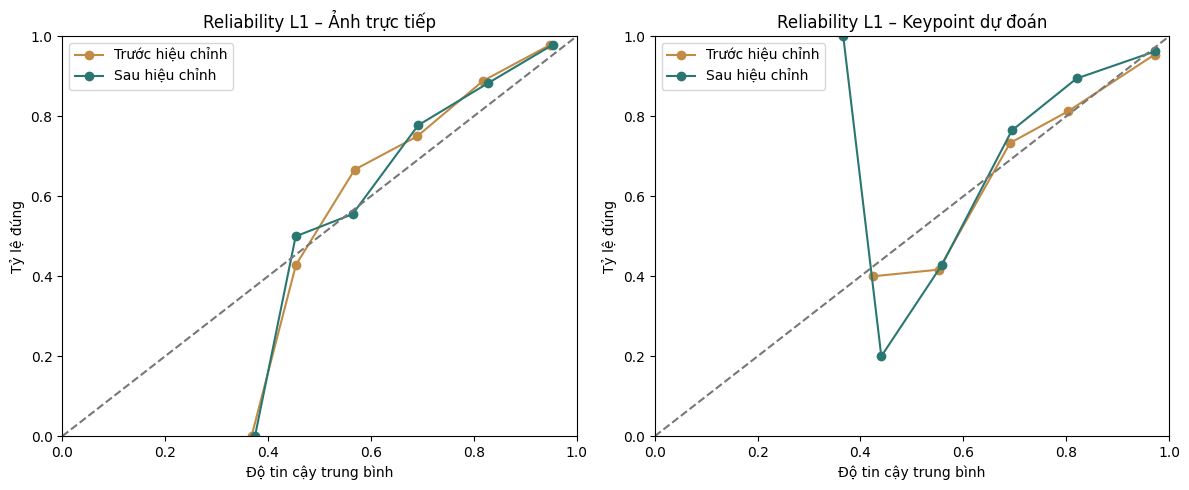

,code,nhan,train_support,val_support,test_support,anh_recall_test,anh_f1_test,keypoint_recall_test,keypoint_f1_test
0,C2.1,Ngồi bắt chéo khóa kín,195,41,37,89.2%,90.4%,94.6%,94.6%
1,C2.2,Ngồi bắt chéo không khóa kín,24,4,4,25.0%,33.3%,50.0%,44.4%
2,C2.3,"Ngồi một chân co, một chân thả",82,19,17,88.2%,69.8%,58.8%,60.6%
3,C2.4,Ngồi hai chân thả,22,4,6,33.3%,50.0%,66.7%,61.5%
4,C2.5,Quỳ/ngồi trên gót,23,6,6,33.3%,40.0%,33.3%,36.4%
5,C2.6,"Đứng thẳng, hai chân trụ",32,5,3,100.0%,75.0%,100.0%,66.7%
6,C2.7,Đứng lệch trọng tâm,35,7,7,71.4%,71.4%,57.1%,66.7%
7,C2.8,"Một chân trụ, chân kia co/nâng",16,3,3,33.3%,50.0%,66.7%,80.0%
8,C2.9,Bước/chuyển hướng,33,5,8,87.5%,87.5%,75.0%,75.0%
9,C2.10,Động/múa,29,6,4,75.0%,75.0%,50.0%,50.0%


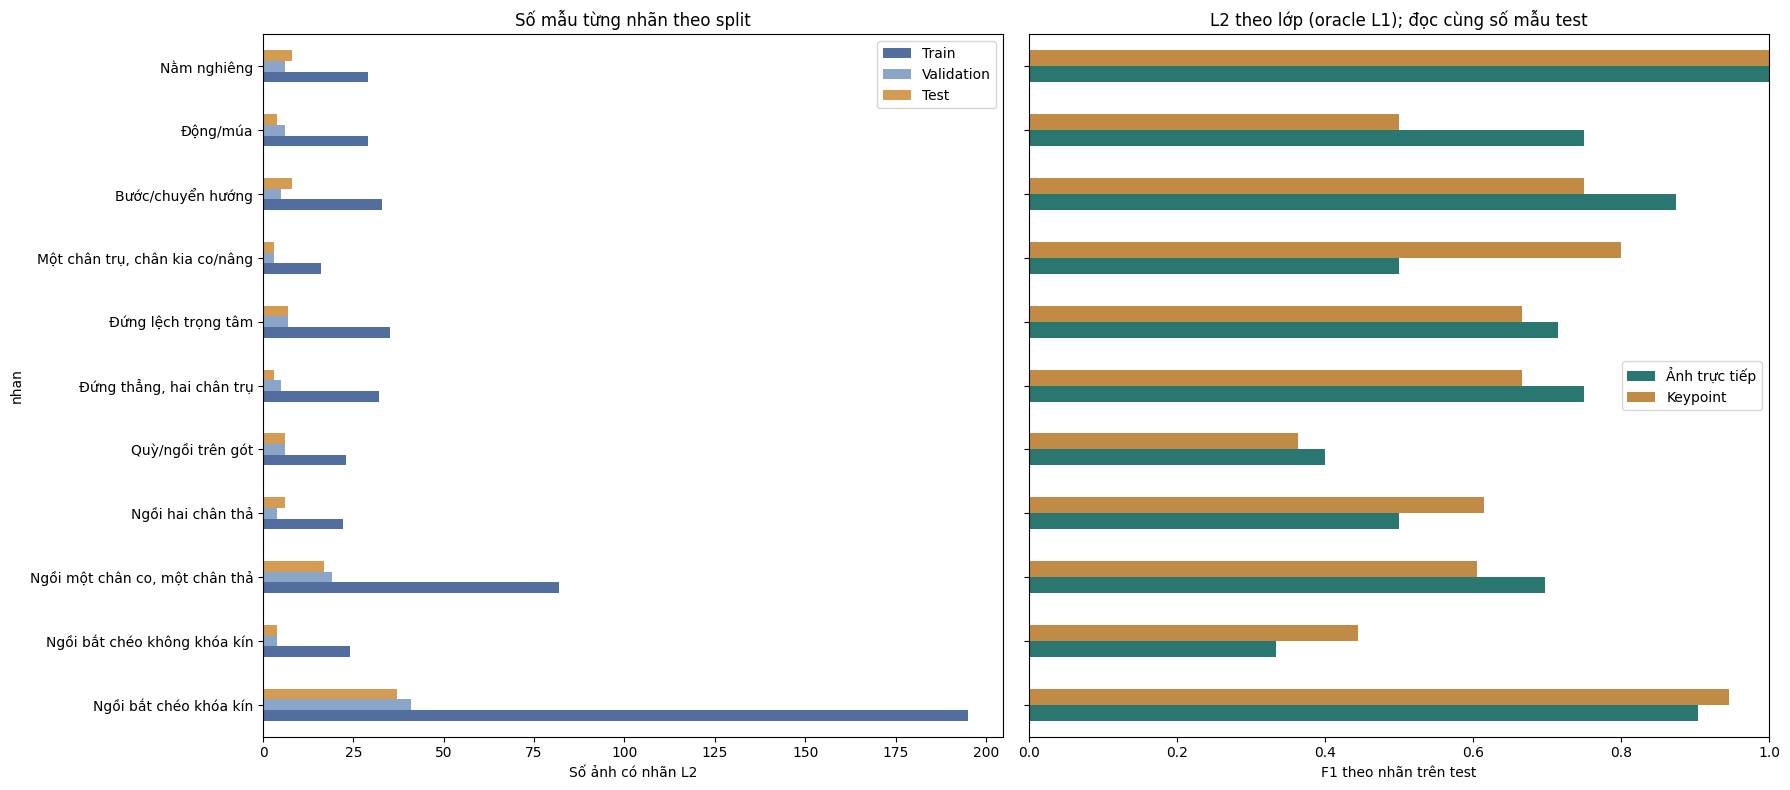

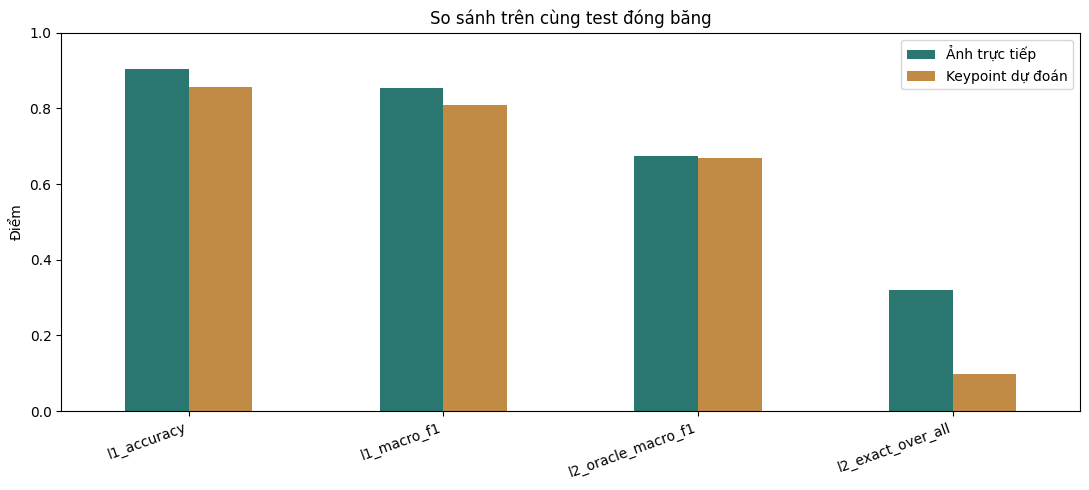

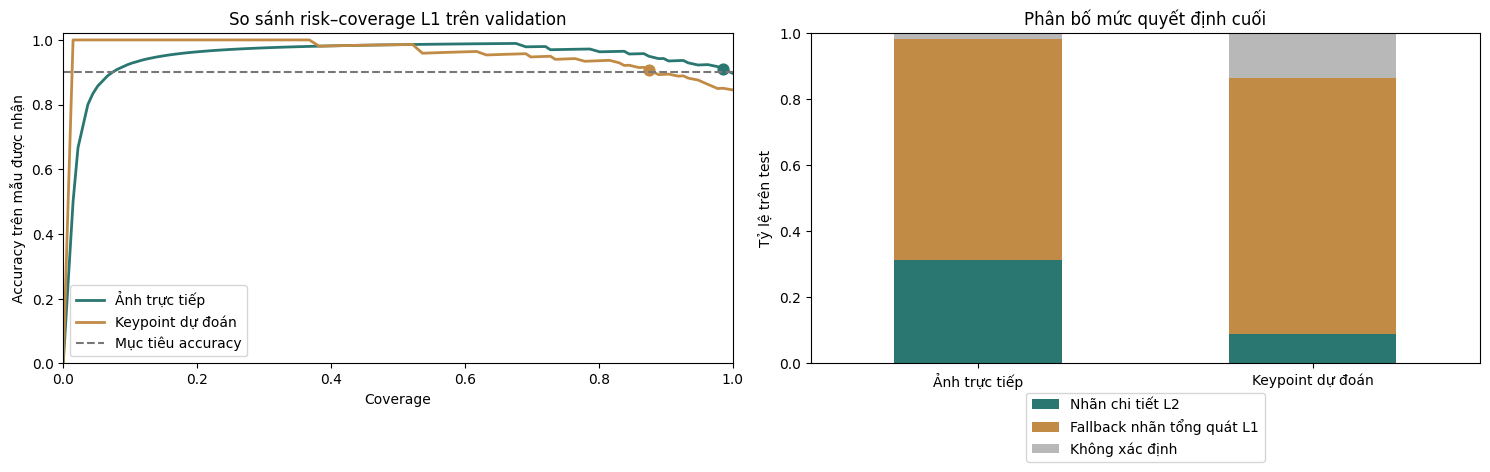

In [14]:
def compact_metrics(metrics):
    return {
        "l1_accuracy": metrics["l1_all_test"]["accuracy"],
        "l1_macro_f1": metrics["l1_all_test"]["macro_f1"],
        "l1_ece": metrics["l1_calibration"]["ece_10_bins"],
        "l1_brier": metrics["l1_calibration"]["multiclass_brier"],
        "l1_selective_coverage": metrics["l1_selective_with_unknown"]["coverage"],
        "l1_selective_accuracy": metrics["l1_selective_with_unknown"]["selective_accuracy"],
        "unknown_rate": 1.0 - metrics["l1_selective_with_unknown"]["coverage"],
        "l2_oracle_accuracy": metrics["l2_oracle_given_gold_l1"]["accuracy"],
        "l2_oracle_macro_f1": metrics["l2_oracle_given_gold_l1"]["macro_f1"],
        "l2_coverage": metrics["l2_end_to_end_with_l1_fallback"]["coverage"],
        "l2_selective_accuracy": metrics["l2_end_to_end_with_l1_fallback"]["selective_accuracy"],
        "l2_exact_over_all": metrics["l2_end_to_end_with_l1_fallback"]["exact_leaf_correct_over_all_gold_l2"],
        "l2_blank_abstention": metrics["l2_end_to_end_with_l1_fallback"]["abstention_rate_on_blank_l2"],
        "l2_evidence_accuracy": (metrics["l2_evidence_classifier"]["accuracy"]
                                 if metrics.get("l2_evidence_classifier") else np.nan),
    }

comparison = {
    "direct_image": compact_metrics(image_test_metrics),
    "predicted_keypoints": compact_metrics(keypoint_test_metrics),
}
comparison_df = pd.DataFrame(comparison).T
display(comparison_df.style.format("{:.3f}"))

guardrail_df = pd.DataFrame([
    {"phương_pháp": "Ảnh trực tiếp", "ngưỡng_L2": image_threshold,
     "ngưỡng_bằng_chứng": image_l2_evidence_threshold, "ngưỡng_C2.2": image_class_thresholds["C2.2"],
     "fallback_L2_trống_test": comparison["direct_image"]["l2_blank_abstention"]},
    {"phương_pháp": "Keypoint dự đoán", "ngưỡng_L2": keypoint_threshold,
     "ngưỡng_bằng_chứng": keypoint_l2_evidence_threshold, "ngưỡng_C2.2": keypoint_class_thresholds["C2.2"],
     "fallback_L2_trống_test": comparison["predicted_keypoints"]["l2_blank_abstention"]},
])
display(guardrail_df.style.format({"ngưỡng_L2": "{:.3f}", "ngưỡng_bằng_chứng": "{:.3f}",
                                  "ngưỡng_C2.2": "{:.3f}", "fallback_L2_trống_test": "{:.1%}"}))

calibration_rows = []
for method, raw_outputs, calibrated_outputs in [
    ("Ảnh trực tiếp", image_val_outputs_raw, image_val_outputs),
    ("Keypoint dự đoán", keypoint_best["val_outputs"], keypoint_val_outputs),
]:
    before = multiclass_calibration_metrics(raw_outputs["l1_logits"], raw_outputs["y1"])
    after = multiclass_calibration_metrics(calibrated_outputs["l1_logits"], calibrated_outputs["y1"])
    calibration_rows.append({"phương_pháp": method, "ECE_trước": before["ece_10_bins"],
                             "ECE_sau": after["ece_10_bins"], "Brier_trước": before["multiclass_brier"],
                             "Brier_sau": after["multiclass_brier"]})
display(pd.DataFrame(calibration_rows).style.format({"ECE_trước": "{:.3f}", "ECE_sau": "{:.3f}", "Brier_trước": "{:.3f}", "Brier_sau": "{:.3f}"}))

def reliability_points(outputs, bins=8):
    probabilities = torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()
    confidence = probabilities.max(axis=1); prediction = probabilities.argmax(axis=1)
    correct = prediction == outputs["y1"]
    xs, ys = [], []
    for lower, upper in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.any(): xs.append(float(confidence[mask].mean())); ys.append(float(correct[mask].mean()))
    return xs, ys
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, method, raw_outputs, calibrated_outputs in [
    (axes[0], "Ảnh trực tiếp", image_val_outputs_raw, image_val_outputs),
    (axes[1], "Keypoint dự đoán", keypoint_best["val_outputs"], keypoint_val_outputs),
]:
    for outputs, label, color in [(raw_outputs, "Trước hiệu chỉnh", "#c28b45"), (calibrated_outputs, "Sau hiệu chỉnh", "#2a7771")]:
        x, y = reliability_points(outputs); ax.plot(x, y, marker="o", label=label, color=color)
    ax.plot([0, 1], [0, 1], linestyle="--", color="#777777"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Độ tin cậy trung bình"); ax.set_ylabel("Tỷ lệ đúng"); ax.set_title(f"Reliability L1 – {method}"); ax.legend()
plt.tight_layout(); plt.show()

# Per-class L2 support and test metrics: small support makes a class score highly uncertain.
l2_split_support = {
    split: Counter(row["level_2_code"] for row in rows if row["split"] == split and row["level_2_code"])
    for split in ("train", "val", "test")
}
image_l2_per_class = image_test_metrics["l2_oracle_given_gold_l1"]["per_class"]
keypoint_l2_per_class = keypoint_test_metrics["l2_oracle_given_gold_l1"]["per_class"]
l2_diagnostic_rows = []
for class_idx, code in enumerate(indices["l2_codes"]):
    image_item = image_l2_per_class[class_idx]
    keypoint_item = keypoint_l2_per_class[class_idx]
    l2_diagnostic_rows.append({
        "code": code, "nhan": l2_names_vi.get(code, code),
        "train_support": l2_split_support["train"][code],
        "val_support": l2_split_support["val"][code],
        "test_support": image_item["support"],
        "anh_recall_test": image_item["recall"], "anh_f1_test": image_item["f1"],
        "keypoint_recall_test": keypoint_item["recall"], "keypoint_f1_test": keypoint_item["f1"],
    })
l2_diagnostic_df = pd.DataFrame(l2_diagnostic_rows)
display(l2_diagnostic_df.style.format({"anh_recall_test": "{:.1%}", "anh_f1_test": "{:.1%}", "keypoint_recall_test": "{:.1%}", "keypoint_f1_test": "{:.1%}"}))
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)
support_plot = l2_diagnostic_df.set_index("nhan")[["train_support", "val_support", "test_support"]]
support_plot.plot(kind="barh", ax=axes[0], color=["#526e9e", "#8aa5c8", "#d49b52"])
axes[0].set_xlabel("Số ảnh có nhãn L2"); axes[0].set_title("Số mẫu từng nhãn theo split")
axes[0].legend(["Train", "Validation", "Test"])
l2_f1_plot = l2_diagnostic_df.set_index("nhan")[["anh_f1_test", "keypoint_f1_test"]]
l2_f1_plot.plot(kind="barh", ax=axes[1], color=["#2a7771", "#c28b45"])
axes[1].set_xlim(0, 1); axes[1].set_xlabel("F1 theo nhãn trên test")
axes[1].set_title("L2 theo lớp (oracle L1); đọc cùng số mẫu test"); axes[1].tick_params(axis="y", labelleft=False)
axes[1].legend(["Ảnh trực tiếp", "Keypoint"])
plt.tight_layout(); plt.show()

plot_metrics = ["l1_accuracy", "l1_macro_f1", "l2_oracle_macro_f1", "l2_exact_over_all"]
ax = comparison_df[plot_metrics].T.plot(kind="bar", figsize=(11, 5), color=["#2a7771", "#c28b45"])
ax.set_ylim(0, 1)
ax.set_ylabel("Điểm")
ax.set_title("So sánh trên cùng test đóng băng")
ax.legend(["Ảnh trực tiếp", "Keypoint dự đoán"])
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for curve_rows, choice, label, color in [
    (image_l1_curve_rows, image_l1_choice, "Ảnh trực tiếp", "#2a7771"),
    (keypoint_l1_curve_rows, keypoint_l1_choice, "Keypoint dự đoán", "#c28b45"),
]:
    curve = pd.DataFrame(curve_rows)
    axes[0].plot(curve["coverage"], curve["selective_accuracy"], label=label, color=color, linewidth=2)
    axes[0].scatter([choice["coverage"]], [choice["selective_accuracy"]], color=color, s=60)
axes[0].axhline(L1_TARGET_SELECTIVE_ACCURACY, color="#777777", linestyle="--", label="Mục tiêu accuracy")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.02)
axes[0].set_xlabel("Coverage"); axes[0].set_ylabel("Accuracy trên mẫu được nhận")
axes[0].set_title("So sánh risk–coverage L1 trên validation"); axes[0].legend()
def decision_proportions(outputs, l2_threshold, l1_threshold, evidence_ok=None, l2_evidence_threshold=0.0, class_thresholds=None):
    decisions = hierarchical_predictions(
        outputs, indices, l2_threshold, l1_threshold, evidence_ok, l2_evidence_threshold, class_thresholds
    )
    counts = Counter(row["decision_level"] for row in decisions)
    total = max(len(decisions), 1)
    return [counts["l2"] / total, counts["l1"] / total, counts["unknown"] / total]
decision_df = pd.DataFrame({
    "Ảnh trực tiếp": decision_proportions(image_test_outputs, image_threshold, image_l1_threshold, None, image_l2_evidence_threshold, image_class_thresholds),
    "Keypoint dự đoán": decision_proportions(keypoint_test_outputs, keypoint_threshold, keypoint_l1_threshold, keypoint_test_pose_ok, keypoint_l2_evidence_threshold, keypoint_class_thresholds),
}, index=["Nhãn chi tiết L2", "Fallback nhãn tổng quát L1", "Không xác định"]).T
decision_df.plot(kind="bar", stacked=True, ax=axes[1], color=["#2a7771", "#c28b45", "#b8b8b8"])
axes[1].set_ylim(0, 1); axes[1].set_ylabel("Tỷ lệ trên test"); axes[1].set_title("Phân bố mức quyết định cuối")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=1)
plt.tight_layout()
plt.show()


**Nhận xét.** Nhánh ảnh đạt accuracy L1 90,40%, cao hơn mức 85,60% của nhánh điểm khớp trong lần chạy này; macro-F1 tương ứng là 0,8546 và 0,8091. ECE của nhánh ảnh khoảng 0,0350, thấp hơn 0,0502 của nhánh điểm khớp. Đây là kết quả trên test hiện có, chưa đủ để kết luận ưu thế ổn định trên mọi tập dữ liệu.

Sau cổng L1, nhánh ảnh chấp nhận 123/125 mẫu và nhánh điểm khớp chấp nhận 108/125 mẫu. Với 103 mẫu có L2 chuẩn, nhánh ảnh trả đúng L2 cho 33 mẫu; 65 mẫu chỉ được trả L1 và 1 mẫu bị từ chối hoàn toàn. Trên 22 mẫu để trống L2, nhánh ảnh vẫn trả nhầm nhãn chi tiết cho 2 mẫu, còn nhánh điểm khớp cho 1 mẫu.

Như vậy, cơ chế từ chối đã giảm việc gán nhãn thiếu căn cứ nhưng chưa loại bỏ hoàn toàn, đồng thời làm giảm độ bao phủ L2. Cần đọc đường cong rủi ro–độ bao phủ và số mẫu từng lớp trước khi lựa chọn điểm vận hành phù hợp.

Bảng trước–sau hiệu chỉnh và đồ thị độ tin cậy sử dụng validation; đường gần đường chéo hơn biểu thị độ tin cậy phù hợp hơn với tỷ lệ đúng quan sát được. ECE và Brier thấp hơn thường tốt hơn, nhưng ECE còn phụ thuộc cách chia khoảng và số mẫu. Hiệu chỉnh xác suất không tự sửa mọi nhãn dự đoán sai. Biểu đồ quyết định cuối dùng toàn bộ 125 mẫu test, khác với các tỷ lệ L2 chỉ tính trên 103 mẫu có nhãn chi tiết.


## 15. Ước lượng độ bất định của chênh lệch kết quả

Cell lấy mẫu lại có hoàn lại 2.000 lần từ các dòng test, giữ cặp dự đoán của hai phương pháp trên cùng mẫu. Phép bootstrap theo cặp ước lượng khoảng biến động của chênh lệch accuracy L1 do thành phần tập test. Nó không huấn luyện lại mô hình và không đo đầy đủ biến động giữa các seed.

In [15]:
def bootstrap_accuracy_difference(outputs_a, outputs_b, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    gold = np.array([indices["l1_to_idx"][row["level_1_code"]] for row in rows if row["split"] == "test"])
    pred_a = outputs_a["l1_logits"].argmax(axis=1)
    pred_b = outputs_b["l1_logits"].argmax(axis=1)
    differences = []
    for _ in range(n_boot):
        sample = rng.integers(0, len(gold), len(gold))
        differences.append(np.mean(pred_a[sample] == gold[sample]) - np.mean(pred_b[sample] == gold[sample]))
    return {"image_minus_keypoint_accuracy_difference": float(np.mean(differences)),
            "bootstrap_95ci": [float(x) for x in np.quantile(differences, [0.025, 0.975])],
            "bootstrap_resamples": n_boot}

paired_uncertainty = bootstrap_accuracy_difference(image_test_outputs, keypoint_test_outputs)
(RUN_ROOT / "paired_bootstrap.json").write_text(json.dumps(paired_uncertainty, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(paired_uncertainty, ensure_ascii=False, indent=2))


{
  "image_minus_keypoint_accuracy_difference": 0.048184000000000025,
  "bootstrap_95ci": [
    -0.008000000000000007,
    0.11199999999999999
  ],
  "bootstrap_resamples": 2000
}


**Nhận xét.** Chênh lệch accuracy L1 quan sát được là 4,8 điểm phần trăm theo hướng có lợi cho mô hình ảnh. Trung bình bootstrap khoảng 4,82 điểm phần trăm, với khoảng 95% từ −0,8 đến 11,2 điểm phần trăm. Khoảng này chứa 0, nên chưa đủ căn cứ kết luận mô hình ảnh vượt trội một cách chắc chắn theo phép ước lượng này.

Việc lấy mẫu lại hiện thực hiện theo từng dòng, chưa theo nhóm tác phẩm hoặc ảnh gốc. Nếu nhiều mẫu cùng nhóm có tương quan, khoảng ước lượng có thể chưa phản ánh hết độ bất định. Cần cân nhắc bootstrap theo nhóm và kiểm chứng trên tập mới khi đưa ra kết luận khái quát hơn.

## 16. Phân tích các trường hợp còn sai

Cell lập danh sách những mẫu mà ít nhất một trong hai phương pháp dự đoán sai L1 hoặc từ chối trả L1, đồng thời khảo sát kết quả theo mức đầy đủ của điểm khớp. Danh sách này giúp chọn ảnh để kiểm tra trực quan và đối chiếu lại quy tắc gán nhãn. Các lỗi chỉ xảy ra ở L2 cần được xem thêm trong bảng theo lớp ở mục 13.

In [16]:
image_predictions = hierarchical_predictions(
    image_test_outputs, indices, image_threshold, image_l1_threshold, None,
    image_l2_evidence_threshold, image_class_thresholds
)
keypoint_predictions = hierarchical_predictions(
    keypoint_test_outputs, indices, keypoint_threshold, keypoint_l1_threshold, keypoint_test_pose_ok,
    keypoint_l2_evidence_threshold, keypoint_class_thresholds
)
test_rows = [row for row in rows if row["split"] == "test"]
error_rows = []
for row, image_pred, kp_pred in zip(test_rows, image_predictions, keypoint_predictions):
    if image_pred["l1_code"] != row["level_1_code"] or kp_pred["l1_code"] != row["level_1_code"]:
        error_rows.append({
            "image_id": row["image_id"], "gold_l1": row["level_1_code"],
            "image_pred_l1": image_pred["l1_code"], "keypoint_pred_l1": kp_pred["l1_code"],
            "gold_l2": row["level_2_code"], "image_pred_l2": image_pred["l2_code"],
            "keypoint_pred_l2": kp_pred["l2_code"],
            "image_unknown": image_pred["is_unknown"], "keypoint_unknown": kp_pred["is_unknown"],
            "visibility": row["visibility"],
            "annotation_confidence": row["annotation_confidence"],
        })
print("Số mẫu có ít nhất một hướng sai L1:", len(error_rows))
error_df = pd.DataFrame(error_rows)
display(error_df)


Số mẫu có ít nhất một hướng sai L1: 28


,image_id,gold_l1,image_pred_l1,keypoint_pred_l1,gold_l2,image_pred_l2,keypoint_pred_l2,image_unknown,keypoint_unknown,visibility,annotation_confidence
0,1068,C1.3,C1.3,,C2.9,,,False,True,partial,high
1,THK000098,C1.3,C1.3,C1.4,C2.9,,,False,False,partial,high
2,THK000279,C1.3,C1.2,,C2.9,,,False,True,full,high
3,THK000061,C1.3,C1.3,C1.2,C2.10,,,False,False,full,high
4,THK000472,C1.1,C1.1,C1.3,C2.3,,,False,False,full,high
5,THK000285,C1.3,C1.2,,C2.10,,,False,True,full,high
6,2201,C1.2,C1.3,C1.3,C2.7,,,False,False,partial,high
7,THK000068,C1.3,C1.1,,,,,False,True,partial,medium
8,THK000991_26d94e3c4c_2,C1.1,C1.3,,C2.5,,,False,True,full,high
9,THK000255,C1.3,C1.3,,C2.9,,,False,True,full,high


**Nhận xét.** Danh sách gồm 28 mẫu thuộc hợp các trường hợp sai hoặc bị từ chối của hai phương pháp. Con số này không có nghĩa mô hình đang dùng trong demo sai 28 mẫu, và cũng không bao gồm toàn bộ lỗi L2 khi L1 đã đúng.

Những lỗi được người dùng phản ánh cần được tách thành hai nhóm: nhận sai nhóm cha, chẳng hạn quỳ bị nhận thành đứng hoặc chuyển động; và nhận đúng nhóm cha nhưng không trả được nhãn con, chẳng hạn chỉ trả ngồi cho tư thế một chân co, một chân thả. Nhóm thứ nhất liên quan đến phân biệt L1; nhóm thứ hai còn phụ thuộc chất lượng L2, bằng chứng và ngưỡng chấp nhận.

Các nguyên nhân đã có bằng chứng gồm mất cân bằng số mẫu, sai số định vị chân ở một số lớp và việc khóa lớp không đạt yêu cầu validation. Trang phục che chân, góc nhìn hoặc hình thức tạo tác khác nhau là những khả năng cần kiểm tra trực tiếp trên ảnh; chưa có cơ sở để gán chúng làm nguyên nhân cho từng trường hợp. So sánh mẫu đủ và thiếu điểm khớp chỉ cho thấy mối liên hệ, chưa chứng minh quan hệ nhân quả.

## 17. Demo bằng mô hình đã lưu

Sau khi mở lại notebook hoặc khởi động lại kernel, chạy riêng cell dưới để thử ảnh; không cần huấn luyện lại. Nếu có bản cải tiến đã vượt kiểm định và được kích hoạt, phần nạp model tích hợp trong notebook nạp đúng bản đó cùng trọng số nền tương ứng. Nếu chưa có, chương trình dùng lần chạy baseline đầy đủ đã hoàn thành gần nhất. Đường dẫn in ra cho biết mô hình thực sự được dùng.

Cần giữ thư mục `outputs`, dữ liệu và notebook trong cấu trúc dự án. Khi vừa thay phiên bản mô hình, khởi động lại kernel rồi chạy lại cell demo để tránh dùng mô hình cũ còn nằm trong bộ nhớ.

Chọn ảnh trong giao diện và đọc nhãn cùng mức quyết định. L1 nghĩa là hệ thống chỉ chấp nhận nhóm tư thế; L2 là kết luận chi tiết; từ chối nghĩa là chưa đạt điều kiện. Điểm tin cậy là đầu ra mô hình, không phải bảo đảm đúng cho từng ảnh. Kết quả cải thiện và các giới hạn được trình bày tại mục 19.


In [1]:
# Nạp phần hỗ trợ nhúng trong chính notebook, kể cả khi chạy riêng cell này.
from pathlib import Path
import json
_notebook_root = next(candidate.resolve()
    for base in [Path.cwd(), *Path.cwd().parents]
    for candidate in [base, base / "Thangka_Pose_Training"]
    if (candidate / "Thangka_Pose_Training.ipynb").is_file() and (candidate / "data").is_dir())
_notebook_document = json.loads((_notebook_root / "Thangka_Pose_Training.ipynb").read_text(encoding="utf-8"))
_support_cell = next(c for c in _notebook_document["cells"] if c.get("id") == "embedded-notebook-support")
exec(compile("".join(_support_cell["source"]), "<notebook support>", "exec"), globals())
_load_notebook_support(_notebook_root)

if "deployment_selection" not in globals() or "pose_model" not in globals():
    from saved_demo import load_saved_demo_globals
    globals().update(load_saved_demo_globals(_notebook_root))

def format_prediction_vi(prediction):
    percent = 100.0 * prediction["final_confidence"]
    if prediction["is_unknown"]:
        return f"Không xác định – độ tin cậy L1 cao nhất {percent:.0f}%"
    code = prediction["final_code"]
    name = l2_names_vi[code] if prediction["decision_level"] == "l2" else l1_names_vi[code]
    return f"{name} – {percent:.0f}%"

def prediction_reason_vi(prediction):
    if prediction["is_unknown"]:
        return "Độ tin cậy tư thế tổng quát chưa đạt ngưỡng được chọn trên validation."
    if prediction["decision_level"] == "l2":
        return "Đủ bằng chứng thị giác và độ tin cậy để trả nhãn chi tiết L2."
    if not prediction["l2_evidence_ok"]:
        return "Chưa đủ bằng chứng thị giác cho L2; hệ thống giữ nhãn tổng quát L1."
    return "Độ tin cậy L2 chưa đạt ngưỡng; hệ thống giữ nhãn tổng quát L1."

def predict_posture(image_path):
    image_path = Path(image_path).expanduser().resolve()
    if not image_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh demo: {image_path}")
    pose_result = pose_model.predict(
        source=str(image_path), imgsz=POSE_IMAGE_SIZE,
        device=pose_feature_device, half=pose_feature_device != "cpu", max_det=1, verbose=False,
    )[0]
    feature = np.zeros((1, 54), dtype=np.float32)
    with Image.open(image_path) as source_image:
        feature[0, 53] = source_image.width / source_image.height
    detected = False
    if pose_result.boxes is not None and len(pose_result.boxes) and pose_result.keypoints is not None:
        best = int(np.argmax(pose_result.boxes.conf.detach().cpu().numpy()))
        xy = pose_result.keypoints.xyn[best].detach().cpu().numpy()
        kp_conf = (pose_result.keypoints.conf[best].detach().cpu().numpy()
                   if pose_result.keypoints.conf is not None else np.ones(17))
        feature[0, :51] = np.column_stack([xy, kp_conf]).reshape(-1)
        feature[0, 51] = float(pose_result.boxes.conf[best])
        feature[0, 52] = 1.0
        detected = True
    geometry_feature = engineer_pose_features(feature)
    outputs = apply_temperatures(outputs_from_classifiers(
        keypoint_best["l1_model"], keypoint_best["l2_models"], keypoint_best["evidence_model"],
        geometry_feature,
    ), keypoint_temperatures)
    image_outputs = collect_image_path(image_path, image_members, indices)
    outputs = fuse_outputs(image_outputs, outputs, indices, deployment_selection["image_weight"], [detected])
    prediction = hierarchical_predictions(
        outputs, indices, deployment_threshold, deployment_l1_threshold, None,
        deployment_evidence_threshold, deployment_class_thresholds,
    )[0]
    return {
        "image_path": str(image_path), "pose_detected": detected,
        "prediction": prediction, "display_text": format_prediction_vi(prediction),
        "reason_text": prediction_reason_vi(prediction),
        "l1_probabilities": torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()[0],
        "l2_logits": outputs["l2_logits"][0], "pose_result": pose_result,
    }

# COCO-17 không có keypoint cổ. Hai cạnh tai-vai mặc định dễ gây hiểu nhầm trên tranh Thangka,
# nên phần minh họa tách khung mặt khỏi khung thân; dữ liệu keypoint dùng cho phân loại không đổi.
DEMO_SKELETON_EDGES = [
    (0, 1), (0, 2), (1, 2), (1, 3), (2, 4),  # mặt
    (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16),
]

def draw_demo_pose(ax, pose_result, min_keypoint_confidence=0.25):
    from matplotlib.patches import Rectangle
    image_rgb = pose_result.orig_img[..., ::-1]
    ax.imshow(image_rgb)
    if pose_result.boxes is None or len(pose_result.boxes) == 0 or pose_result.keypoints is None:
        return
    box_confidences = pose_result.boxes.conf.detach().cpu().numpy()
    best = int(np.argmax(box_confidences))
    x1, y1, x2, y2 = pose_result.boxes.xyxy[best].detach().cpu().numpy()
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="#ffd23f", linewidth=2.5))
    xy = pose_result.keypoints.xy[best].detach().cpu().numpy()
    confidence = (pose_result.keypoints.conf[best].detach().cpu().numpy()
                  if pose_result.keypoints.conf is not None else np.ones(len(xy), dtype=np.float32))
    visible = confidence >= float(min_keypoint_confidence)
    for start, end in DEMO_SKELETON_EDGES:
        if visible[start] and visible[end]:
            is_face = start <= 4 and end <= 4
            ax.plot([xy[start, 0], xy[end, 0]], [xy[start, 1], xy[end, 1]],
                    color="#23e05f" if is_face else "#20a4f3", linewidth=2.5, alpha=0.9)
    face_points = np.arange(0, 5)
    body_points = np.arange(5, 17)
    face_visible = face_points[visible[face_points]]
    body_visible = body_points[visible[body_points]]
    if len(face_visible):
        ax.scatter(xy[face_visible, 0], xy[face_visible, 1], s=55, c="#23e05f", edgecolors="white", linewidths=0.8, zorder=3)
    if len(body_visible):
        ax.scatter(xy[body_visible, 0], xy[body_visible, 1], s=55, c="#20a4f3", edgecolors="white", linewidths=0.8, zorder=3)
    ax.text(x1, max(0, y1 - 8), f"Pose {100 * box_confidences[best]:.0f}%", color="#ffe066",
            fontsize=11, fontweight="bold", bbox={"facecolor": "black", "alpha": 0.55, "pad": 3})

def show_prediction(result):
    pred = result["prediction"]
    # Tách ảnh khỏi biểu đồ để ảnh Thangka không bị co nhỏ khi trình chiếu.
    image_fig, image_ax = plt.subplots(figsize=(15, 9), dpi=120)
    draw_demo_pose(image_ax, result["pose_result"])
    image_ax.set_title(result["display_text"] + "\nKhung mặt và khung thân được tách rời; bbox/keypoint chỉ dùng để hỗ trợ", fontsize=16, fontweight="bold")
    image_ax.axis("off")
    image_fig.tight_layout()
    plt.show()
    plt.close(image_fig)
    fig, axes = plt.subplots(1, 3, figsize=(20, 6), dpi=120)
    l1_prob = result["l1_probabilities"]
    l1_labels = [l1_names_vi[code] for code in indices["l1_codes"]]
    colors = ["#2a7771" if code == pred["l1_candidate"] else "#9fbfbc" for code in indices["l1_codes"]]
    axes[0].barh(l1_labels, l1_prob, color=colors)
    axes[0].axvline(deployment_l1_threshold, color="#b33a3a", linestyle="--", label=f"Ngưỡng L1 = {deployment_l1_threshold:.2f}")
    axes[0].set_xlim(0, 1); axes[0].set_title("Độ tin cậy nhãn tổng quát L1"); axes[0].legend()
    evidence_value = pred["l2_evidence_confidence"]
    axes[1].barh(["Đủ bằng chứng L2"], [evidence_value], color="#526e9e")
    axes[1].axvline(deployment_evidence_threshold, color="#b33a3a", linestyle="--",
                    label=f"Ngưỡng bằng chứng = {deployment_evidence_threshold:.2f}")
    axes[1].set_xlim(0, 1); axes[1].set_title("Bằng chứng cho nhãn chi tiết"); axes[1].legend()
    parent = pred["l1_candidate"]
    child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent]
    child_idx = [indices["l2_to_idx"][code] for code in child_codes]
    conditional = torch.softmax(torch.tensor(result["l2_logits"][child_idx]), dim=0).numpy()
    joint = pred["l1_confidence"] * conditional
    axes[2].barh([l2_names_vi[code] for code in child_codes], joint, color="#c28b45")
    axes[2].axvline(deployment_threshold, color="#b33a3a", linestyle="--", label=f"Ngưỡng L2 = {deployment_threshold:.2f}")
    selected_cutoff = deployment_class_thresholds[pred["l2_candidate"]]
    if selected_cutoff <= 1.0:
        axes[2].axvline(selected_cutoff, color="#7b3294", linestyle=":", label="Ngưỡng riêng nhãn ứng viên")
    else:
        axes[2].text(0.02, 0.95, "Nhãn ứng viên chưa đủ bằng chứng validation để trả L2", transform=axes[2].transAxes, va="top", fontsize=9)
    axes[2].set_xlim(0, 1); axes[2].set_title("Độ tin cậy nhãn chi tiết trong nhánh L1"); axes[2].legend()
    fig.suptitle("Căn cứ cho quyết định phân loại", fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def run_demo(image_path="", split="val", index=0):
    selected_row = None
    if str(image_path).strip():
        demo_path = Path(str(image_path).strip())
        source_text = f"Ảnh ngoài: {demo_path.name}"
    else:
        split_rows = [row for row in rows if row["split"] == split]
        if not split_rows:
            raise ValueError(f"Split không hợp lệ hoặc không có ảnh: {split}")
        selected_row = split_rows[int(index) % len(split_rows)]
        demo_path = DATA_DIR / selected_row["crop_path"]
        source_text = (f"Dataset {split}, ảnh gốc {Path(selected_row['image_path']).name} "
                       f"→ crop mục tiêu {Path(selected_row['crop_path']).name}")
    result = predict_posture(demo_path)
    pred = result["prediction"]
    gold_text = "Không có nhãn tham chiếu"
    if selected_row is not None:
        gold_text = l2_names_vi.get(selected_row["level_2_code"], l1_names_vi[selected_row["level_1_code"]])
    display(pd.DataFrame([{
        "Nguồn ảnh": source_text, "Nhãn tham chiếu": gold_text,
        "Kết quả hệ thống": result["display_text"],
        "Mức quyết định": pred["decision_level"].upper(),
        "Bằng chứng L2": f"{100 * pred['l2_evidence_confidence']:.0f}%",
        "Giải thích fallback": result["reason_text"],
    }]))
    show_prediction(result)
    return result

# Demo mặc định. Có thể đổi split/index hoặc truyền đường dẫn ảnh ngoài dataset.
SUPPORTED_DEMO_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

def run_demo_batch(image_paths, max_images=None):
    from IPython.display import Markdown
    paths = [Path(path).expanduser().resolve() for path in image_paths]
    if max_images is not None:
        paths = paths[:max(1, int(max_images))]
    if not paths:
        raise ValueError("Chưa chọn ảnh hợp lệ để demo.")
    import gc
    summary_rows = []
    for number, image_path in enumerate(paths, start=1):
        display(Markdown(f"## Ảnh {number}/{len(paths)} — `{image_path.name}`"))
        try:
            result = run_demo(image_path=image_path)
            summary_rows.append({"Ảnh": image_path.name, "Kết quả": result["display_text"],
                                 "Mức quyết định": result["prediction"]["decision_level"].upper(), "Trạng thái": "Thành công"})
            del result
        except Exception as exc:
            print(type(exc).__name__ + ":", exc)
            summary_rows.append({"Ảnh": image_path.name, "Kết quả": "—", "Mức quyết định": "—", "Trạng thái": str(exc)})
        finally:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    display(Markdown("## Tổng hợp lô ảnh"))
    summary = pd.DataFrame(summary_rows)
    display(summary)
    return summary

def run_demo_folder(folder_path, recursive=False, max_images=20):
    folder = Path(str(folder_path).strip()).expanduser().resolve()
    if not folder.is_dir():
        raise NotADirectoryError(f"Không tìm thấy thư mục: {folder}")
    candidates = folder.rglob("*") if recursive else folder.iterdir()
    image_paths = sorted(
        (path for path in candidates if path.is_file() and path.suffix.lower() in SUPPORTED_DEMO_EXTENSIONS),
        key=lambda path: str(path).lower(),
    )
    if not image_paths:
        raise FileNotFoundError(f"Thư mục không có ảnh định dạng được hỗ trợ: {folder}")
    if len(image_paths) > int(max_images):
        print(f"Tìm thấy {len(image_paths)} ảnh; demo {int(max_images)} ảnh đầu để kiểm soát thời gian và bộ nhớ.")
    return run_demo_batch(image_paths, max_images=max_images)

def run_demo_dataset_batch(split, selected_indices, max_images=20):
    from IPython.display import Markdown
    import gc
    split_rows = [row for row in rows if row["split"] == split]
    if not split_rows:
        raise ValueError(f"Split không hợp lệ hoặc không có ảnh: {split}")
    chosen = list(selected_indices)[:max(1, int(max_images))]
    if not chosen:
        raise ValueError("Hãy chọn ít nhất một ảnh trong danh sách dataset.")
    summary_rows = []
    for number, index in enumerate(chosen, start=1):
        index = int(index) % len(split_rows)
        row = split_rows[index]
        image_name = Path(row["crop_path"]).name
        display(Markdown(f"## Ảnh dataset {number}/{len(chosen)} — `{image_name}`"))
        try:
            result = run_demo(split=split, index=index)
            gold = l2_names_vi.get(row["level_2_code"], l1_names_vi[row["level_1_code"]])
            summary_rows.append({"Ảnh": image_name, "Nhãn tham chiếu": gold,
                                 "Kết quả": result["display_text"],
                                 "Mức quyết định": result["prediction"]["decision_level"].upper(),
                                 "Trạng thái": "Thành công"})
            del result
        except Exception as exc:
            print(type(exc).__name__ + ":", exc)
            summary_rows.append({"Ảnh": image_name, "Nhãn tham chiếu": "—", "Kết quả": "—",
                                 "Mức quyết định": "—", "Trạng thái": str(exc)})
        finally:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    display(Markdown("## Tổng hợp các ảnh dataset đã chọn"))
    summary = pd.DataFrame(summary_rows)
    display(summary)
    return summary

def run_demo_dataset_files(selected_paths, required_split=None):
    from IPython.display import Markdown
    import gc
    lookup = {}
    for split_name in sorted({row["split"] for row in rows}):
        split_rows = [row for row in rows if row["split"] == split_name]
        for index, row in enumerate(split_rows):
            image_name = Path(row["image_path"]).name.casefold()
            lookup[(split_name, image_name)] = (split_name, index, row)
    chosen_paths = [Path(path).expanduser().resolve() for path in selected_paths]
    if not chosen_paths:
        raise ValueError("Hãy bấm 'Chọn ảnh dataset' và chọn ít nhất một ảnh.")
    summary_rows = []
    for number, image_path in enumerate(chosen_paths, start=1):
        display(Markdown(f"## Ảnh dataset {number}/{len(chosen_paths)} — `{image_path.name}`"))
        split_candidates = [required_split] if required_split else sorted({key[0] for key in lookup})
        matches = [lookup[(split_name, image_path.name.casefold())] for split_name in split_candidates
                   if (split_name, image_path.name.casefold()) in lookup]
        match = matches[0] if matches else None
        if match is None:
            message = f"Ảnh không thuộc split {required_split!r} trong DATA_DIR/images hoặc không có trong manifest."
            print("ValueError:", message)
            summary_rows.append({"Ảnh": image_path.name, "Split": "—", "Nhãn tham chiếu": "—",
                                 "Kết quả": "—", "Mức quyết định": "—", "Trạng thái": message})
            continue
        split_name, index, row = match
        try:
            result = run_demo(split=split_name, index=index)
            gold = l2_names_vi.get(row["level_2_code"], l1_names_vi[row["level_1_code"]])
            summary_rows.append({"Ảnh": image_path.name, "Split": split_name, "Nhãn tham chiếu": gold,
                                 "Kết quả": result["display_text"],
                                 "Mức quyết định": result["prediction"]["decision_level"].upper(),
                                 "Trạng thái": "Thành công"})
            del result
        except Exception as exc:
            print(type(exc).__name__ + ":", exc)
            summary_rows.append({"Ảnh": image_path.name, "Split": split_name, "Nhãn tham chiếu": "—",
                                 "Kết quả": "—", "Mức quyết định": "—", "Trạng thái": str(exc)})
        finally:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    display(Markdown("## Tổng hợp các ảnh dataset đã chọn"))
    summary = pd.DataFrame(summary_rows)
    display(summary)
    return summary

demo_result = None  # Chọn nguồn ảnh trong giao diện bên dưới; không tự chạy ảnh validation.
print("Dùng ảnh ngoài dataset: run_demo(r'C:\\duong_dan\\anh.jpg')")
print("Dùng mẫu khác: run_demo(split='val', index=5) hoặc run_demo(split='test', index=5)")

# Giao diện nút bấm đơn giản trong Jupyter/VS Code; vẫn dùng được run_demo nếu ipywidgets chưa cài.
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    demo_source = widgets.Dropdown(options=[("Validation", "val"), ("Test đã khóa", "test")], description="Nguồn:")
    dataset_selected_paths = []
    dataset_picker_button = widgets.Button(
        description="Chọn ảnh dataset (0)", icon="folder-open",
        layout=widgets.Layout(width="240px"),
    )
    dataset_selection_status = widgets.HTML("<i>Chưa chọn ảnh gốc thuộc split Validation.</i>")
    demo_button = widgets.Button(description="Chạy ảnh đã chọn", button_style="primary")
    demo_output = widgets.Output()

    def _prepare_split_picker_directory(split_name):
        import os
        import shutil
        picker_dir = CACHE_DIR / "dataset_file_picker" / split_name
        picker_dir.mkdir(parents=True, exist_ok=True)
        split_rows = [row for row in rows if row["split"] == split_name]
        for row in split_rows:
            source = (DATA_DIR / row["image_path"]).resolve()
            target = picker_dir / source.name
            if target.exists():
                continue
            try:
                os.link(source, target)  # hard link: không nhân đôi dung lượng ảnh
            except OSError:
                shutil.copy2(source, target)
        return picker_dir

    def _reset_dataset_selection(change):
        dataset_selected_paths.clear()
        dataset_picker_button.description = "Chọn ảnh dataset (0)"
        split_label = "Validation" if change["new"] == "val" else "Test đã khóa"
        dataset_selection_status.value = f"<i>Chưa chọn ảnh gốc thuộc split {split_label}.</i>"

    def _choose_dataset_files(_):
        root = None
        try:
            import tkinter as tk
            from tkinter import filedialog
            initial_dir = _prepare_split_picker_directory(demo_source.value)
            split_label = "Validation" if demo_source.value == "val" else "Test đã khóa"
            root = tk.Tk()
            root.withdraw()
            root.attributes("-topmost", True)
            root.update()
            chosen = filedialog.askopenfilenames(
                parent=root, title=f"Chọn ảnh gốc thuộc split {split_label}",
                initialdir=str(initial_dir),
                filetypes=[("Tệp ảnh", "*.jpg *.jpeg *.png *.webp *.bmp *.tif *.tiff"), ("Tất cả tệp", "*.*")],
            )
            if chosen:
                dataset_selected_paths[:] = list(chosen)
                dataset_picker_button.description = f"Chọn ảnh dataset ({len(chosen)})"
                preview = ", ".join(Path(path).name for path in chosen[:4])
                if len(chosen) > 4:
                    preview += f" và {len(chosen) - 4} ảnh khác"
                dataset_selection_status.value = f"<small><b>Đã chọn {split_label}:</b> {preview}</small>"
        except Exception as exc:
            with demo_output:
                print("Không mở được hộp thoại dataset:", type(exc).__name__ + ":", exc)
        finally:
            if root is not None:
                root.destroy()

    def _run_demo_button(_):
        with demo_output:
            clear_output(wait=True)
            try:
                run_demo_dataset_files(dataset_selected_paths, required_split=demo_source.value)
            except Exception as exc:
                print(type(exc).__name__ + ":", exc)
    demo_source.observe(_reset_dataset_selection, names="value")
    dataset_picker_button.on_click(_choose_dataset_files)
    demo_button.on_click(_run_demo_button)
    import uuid
    upload_picker = widgets.FileUpload(
        accept=".jpg,.jpeg,.png,.webp,.bmp,.tif,.tiff", multiple=True,
        description="Chọn nhiều ảnh", layout=widgets.Layout(width="220px"),
    )
    upload_button = widgets.Button(description="Dự đoán ảnh đã chọn", button_style="success")
    folder_box = widgets.Text(value="", placeholder=r"C:\thu_muc_anh", description="Thư mục:", layout=widgets.Layout(width="700px"))
    recursive_box = widgets.Checkbox(value=False, description="Gồm thư mục con")
    batch_limit = widgets.BoundedIntText(value=20, min=1, max=200, description="Tối đa:")
    folder_button = widgets.Button(description="Chạy cả thư mục", button_style="info")

    def _uploaded_items(value):
        if isinstance(value, dict):  # ipywidgets 7
            items = []
            for name, metadata in value.items():
                item = dict(metadata); item.setdefault("name", name); items.append(item)
            return items
        return [dict(item) for item in value]  # ipywidgets 8

    def _run_upload_button(_):
        with demo_output:
            clear_output(wait=True)
            try:
                items = _uploaded_items(upload_picker.value)
                if not items:
                    raise ValueError("Hãy bấm 'Chọn nhiều ảnh' và chọn ít nhất một tệp.")
                upload_dir = CACHE_DIR / "demo_uploads"
                upload_dir.mkdir(parents=True, exist_ok=True)
                saved_paths = []
                for item in items[:batch_limit.value]:
                    safe_name = Path(item.get("name", "image.jpg")).name
                    target = upload_dir / f"{uuid.uuid4().hex[:8]}_{safe_name}"
                    target.write_bytes(bytes(item["content"]))
                    saved_paths.append(target)
                if len(items) > batch_limit.value:
                    print(f"Đã chọn {len(items)} ảnh; demo {batch_limit.value} ảnh đầu.")
                run_demo_batch(saved_paths)
            except Exception as exc:
                print(type(exc).__name__ + ":", exc)

    def _run_folder_button(_):
        with demo_output:
            clear_output(wait=True)
            try:
                run_demo_folder(folder_box.value, recursive=recursive_box.value, max_images=batch_limit.value)
            except Exception as exc:
                print(type(exc).__name__ + ":", exc)

    upload_button.on_click(_run_upload_button)
    folder_button.on_click(_run_folder_button)
    display(widgets.VBox([
        widgets.HTML("<h3>Demo phân tích tư thế nhân vật Phật giáo</h3><p>Mỗi ảnh trả đúng một quyết định phân cấp L2 → L1 → Không xác định.</p>"),
        widgets.HTML("<b>1. Chọn một hoặc nhiều ảnh gốc có sẵn trong dataset</b> — chọn Validation/Test trước, rồi giữ Ctrl/Shift để chọn nhiều tệp. Notebook tự ánh xạ ảnh gốc sang crop nhân vật mục tiêu đúng như lúc huấn luyện."),
        demo_source, widgets.HBox([dataset_picker_button, demo_button]), dataset_selection_status,
        widgets.HTML("<b>2. Chọn một hoặc nhiều ảnh từ máy</b> — giữ Ctrl/Shift trong hộp thoại để chọn nhiều tệp."),
        widgets.HBox([upload_picker, upload_button]),
        widgets.HTML("<b>3. Chạy toàn bộ ảnh trong một thư mục</b>"),
        folder_box, widgets.HBox([recursive_box, batch_limit, folder_button]),
        demo_output,
    ]))
except ImportError:
    print("Không có ipywidgets; hãy gọi trực tiếp hàm run_demo như hướng dẫn ở trên.")


Đã nạp mô hình và ngưỡng từ run 20261031_174634_seed20261021; có thể chạy demo ngay.
Dùng ảnh ngoài dataset: run_demo(r'C:\duong_dan\anh.jpg')
Dùng mẫu khác: run_demo(split='val', index=5) hoặc run_demo(split='test', index=5)


**Cách đọc kết quả demo.** Đường dẫn được in ra xác định phiên bản trọng số và ngưỡng đang sử dụng. Khung xương là ước lượng của bộ pose, không phải nhãn chuẩn. Cần phân biệt nhãn cha được trả do chưa đủ độ tin cậy L2 với trường hợp mô hình nhận sai cả nhóm L1.

Các lớp bị khóa và chỉ số được phân tích ở những mục trước thuộc run lịch sử. Với bản cải tiến, xem bảng tại mục 19 để biết lớp nào còn yếu; không suy diễn rằng mọi trường hợp đã được khắc phục chỉ vì điểm trung bình tăng. Khi gặp ảnh mới bị sai, lưu lại ảnh, nhãn tham chiếu và đầu ra để phân tích riêng.


## 18. Lưu kết quả và lập báo cáo thí nghiệm

Cell cuối tổng hợp cấu hình, nguồn mô hình, kết quả đánh giá và phương án sử dụng vào các tệp báo cáo của lần chạy. Các tệp này liên kết số liệu với trọng số, dữ liệu và mã nguồn tương ứng, giúp đối chiếu kết quả hoặc nạp lại mô hình mà không cần huấn luyện lại.

In [18]:
summary = {
    "run_id": RUN_ID,
    "created_at": datetime.now(timezone.utc).isoformat(),
    "dataset_audit": audit_summary,
    "inter_rater_agreement": kappa_summary,
    "image_selection": image_selection,
    "image_test": compact_metrics(image_test_metrics),
    "pose_geometry_test": pose_geometry_metrics,
    "keypoint_selection": keypoint_selection,
    "keypoint_test": compact_metrics(keypoint_test_metrics),
    "paired_uncertainty": paired_uncertainty,
    "run_mode": RUN_MODE,
    "image_seeds": IMAGE_SEEDS,
    "deployment_selection": deployment_selection,
    "deployment_test": compact_metrics(deployment_test_metrics),
    "limitations": [
        "Ensemble nhiều seed ảnh; chưa phải nested cross-validation toàn pipeline.",
        "Test lịch sử đã được xem ở các vòng phát triển trước; cần tập độc lập mới để kết luận tổng quát hóa.",
        "Một số lớp L2 chỉ có 3-4 mẫu test.",
        "Không xác định hiện là cơ chế từ chối theo validation trong phân phối; chưa có tập âm/OOD để đánh giá phát hiện ngoài phân phối.",
        "Phạm vi sử dụng nội bộ, không phát hành dữ liệu hoặc trọng số.",
    ],
}
(RUN_ROOT / "SUMMARY.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

report = f"""# Kết quả thực nghiệm phân tích tư thế Thangka

Run: {RUN_ID}  \nChế độ: {RUN_MODE} (smoke chỉ kiểm tra thực thi, không phải kết quả mô hình cuối)  \nSeeds ảnh thực tế: {IMAGE_SEEDS}  
Dataset: {audit_summary['dataset_version']}  
Seed: {SEED}

## Kiểm tra dữ liệu

- Tổng số mẫu: {audit_summary['records']}.
- Split train/validation/test: {audit_summary['split_counts']}.
- Mẫu đủ 17 keypoint: {audit_summary['full_keypoint_records']}.
- Rò rỉ artifact giữa split: {audit_summary['artifact_leakage_groups']} nhóm.
- Rò rỉ ảnh trùng hash giữa split: {audit_summary['exact_hash_leakage_groups']} nhóm.

## Độ đồng thuận

- Cặp nhãn độc lập của Ngan và My: {kappa_summary['n_paired']}.
- Kappa nhãn phân cấp: {kappa_summary['hierarchical_cohen_kappa']:.4f}.
- Kappa L1: {kappa_summary['l1_cohen_kappa']:.4f}.

## Phân loại trực tiếp từ ảnh

- Kiến trúc: {image_architecture}.
- L1 accuracy: {comparison['direct_image']['l1_accuracy']:.4f}.
- L1 macro-F1: {comparison['direct_image']['l1_macro_f1']:.4f}.
- Hiệu chỉnh độ tin cậy L1 (ECE / Brier): {comparison['direct_image']['l1_ece']:.4f} / {comparison['direct_image']['l1_brier']:.4f}.
- Ngưỡng từ chối L1: {image_l1_threshold:.4f}.
- L1 selective coverage/accuracy: {comparison['direct_image']['l1_selective_coverage']:.4f} / {comparison['direct_image']['l1_selective_accuracy']:.4f}.
- Tỷ lệ Không xác định: {comparison['direct_image']['unknown_rate']:.4f}.
- L2 oracle macro-F1: {comparison['direct_image']['l2_oracle_macro_f1']:.4f}.
- L2 exact trên toàn bộ mẫu có gold L2: {comparison['direct_image']['l2_exact_over_all']:.4f}.
- Tỷ lệ fallback trên mẫu người gán nhãn để trống L2: {comparison['direct_image']['l2_blank_abstention']:.4f}.

## Pose và phân loại từ keypoint dự đoán

- Pose PCK@0.05 bbox diagonal: {pose_geometry_metrics['pck_at_0_05_bbox_diagonal']:.4f}.
- Mean bbox IoU: {pose_geometry_metrics['mean_bbox_iou'] if pose_geometry_metrics['mean_bbox_iou'] is not None else 'n.a.'}.
- Mean OKS: {pose_geometry_metrics['mean_oks'] if pose_geometry_metrics['mean_oks'] is not None else 'n.a.'}.
- Classifier keypoint: {keypoint_model_name}.
- L1 accuracy: {comparison['predicted_keypoints']['l1_accuracy']:.4f}.
- L1 macro-F1: {comparison['predicted_keypoints']['l1_macro_f1']:.4f}.
- Hiệu chỉnh độ tin cậy L1 (ECE / Brier): {comparison['predicted_keypoints']['l1_ece']:.4f} / {comparison['predicted_keypoints']['l1_brier']:.4f}.
- Ngưỡng từ chối L1: {keypoint_l1_threshold:.4f}.
- L1 selective coverage/accuracy: {comparison['predicted_keypoints']['l1_selective_coverage']:.4f} / {comparison['predicted_keypoints']['l1_selective_accuracy']:.4f}.
- Tỷ lệ Không xác định: {comparison['predicted_keypoints']['unknown_rate']:.4f}.
- L2 oracle macro-F1: {comparison['predicted_keypoints']['l2_oracle_macro_f1']:.4f}.
- L2 exact trên toàn bộ mẫu có gold L2: {comparison['predicted_keypoints']['l2_exact_over_all']:.4f}.
- Tỷ lệ fallback trên mẫu người gán nhãn để trống L2: {comparison['predicted_keypoints']['l2_blank_abstention']:.4f}.
- Accuracy bộ kiểm tra đủ bằng chứng L2: {comparison['predicted_keypoints']['l2_evidence_accuracy']:.4f}.

## So sánh và giới hạn

- Chênh lệch L1 accuracy hướng ảnh trừ hướng keypoint: {paired_uncertainty['image_minus_keypoint_accuracy_difference']:.4f}.
- Bootstrap 95% CI: {paired_uncertainty['bootstrap_95ci']}.
- Mô hình ảnh học head, mở các block trên rồi toàn backbone; cố định thống kê BatchNorm, dùng loss phân cấp joint và head bằng chứng L2.
- Mô hình keypoint dùng đặc trưng hình học chuẩn hóa, classifier L2 riêng theo nhánh và bộ kiểm tra đủ bằng chứng L2.
- Tất cả nhãn L2 có ngưỡng riêng được chọn trên validation; báo support và khoảng tin cậy, không ép nhãn hiếm.
- Xác suất được temperature scaling trên validation trước khi chọn ngưỡng từ chối.
- Ensemble nhiều seed; không suy rộng quá phạm vi snapshot hoặc coi test đã xem là đánh giá độc lập mới.
- Các lớp L2 support nhỏ phải được báo cùng support và confusion matrix.
- Không xác định là từ chối do bằng chứng yếu theo validation; chưa thể diễn giải như bộ phát hiện OOD vì chưa có tập âm/OOD.
- Dữ liệu và trọng số chỉ dùng nội bộ theo metadata quyền sử dụng.
"""
(RUN_ROOT / "REPORT.md").write_text(report, encoding="utf-8")
print(report)
print("\nHoàn tất. Tất cả kết quả của run ở:", RUN_ROOT)

with (RUN_ROOT / "REPORT.md").open("a", encoding="utf-8") as stream:
    stream.write("\n\n## Đầu ra triển khai\n\n" + json.dumps({"selection": deployment_selection, "test": compact_metrics(deployment_test_metrics)}, ensure_ascii=False, indent=2))


# Kết quả thực nghiệm phân tích tư thế Thangka

Run: 20261031_174817_seed20261021  
Chế độ: full (smoke chỉ kiểm tra thực thi, không phải kết quả mô hình cuối)  
Seeds ảnh thực tế: [20261021, 20261031, 20261107]  
Dataset: thangka_pose_v1.1.0_dacntt_2026-10-20  
Seed: 20261021

## Kiểm tra dữ liệu

- Tổng số mẫu: 873.
- Split train/validation/test: {'val': 136, 'train': 612, 'test': 125}.
- Mẫu đủ 17 keypoint: 612.
- Rò rỉ artifact giữa split: 0 nhóm.
- Rò rỉ ảnh trùng hash giữa split: 0 nhóm.

## Độ đồng thuận

- Cặp nhãn độc lập của Ngan và My: 873.
- Kappa nhãn phân cấp: 0.9652.
- Kappa L1: 1.0000.

## Phân loại trực tiếp từ ảnh

- Kiến trúc: resnet18.
- L1 accuracy: 0.9040.
- L1 macro-F1: 0.8546.
- Hiệu chỉnh độ tin cậy L1 (ECE / Brier): 0.0350 / 0.1548.
- Ngưỡng từ chối L1: 0.4267.
- L1 selective coverage/accuracy: 0.9840 / 0.9106.
- Tỷ lệ Không xác định: 0.0160.
- L2 oracle macro-F1: 0.6749.
- L2 exact trên toàn bộ mẫu có gold L2: 0.3204.
- Tỷ lệ fallback trên mẫu người gán nhãn 

**Nhận xét và phạm vi kết luận.** Đường dẫn được in ra xác nhận nơi ghi bản tổng hợp; cần giữ cùng các checkpoint và bản mã nguồn của lần chạy. Việc lưu thành công hỗ trợ tái lập và sử dụng lại, nhưng không khắc phục các hạn chế nhận dạng đã nêu.

Trong kết quả đang lưu, mô hình ảnh đạt chất lượng L1 cao hơn mô hình điểm khớp về giá trị quan sát, song độ bao phủ L2 còn thấp và ba nhãn cần cải thiện vẫn chưa được trả ra. Nhãn ngồi một chân co, một chân thả và nằm nghiêng có tiến bộ trong đối chiếu lịch sử, nhưng đây chưa phải kiểm chứng độc lập. Kết luận phù hợp là hệ thống đã có quy trình học, lưu và đánh giá rõ ràng; hiệu quả trên các tư thế hiếm vẫn cần được cải thiện bằng dữ liệu đã rà soát và kiểm chứng trên tập chưa sử dụng trong phát triển.

## 19. Thí nghiệm cải thiện các lớp còn yếu

Phần này bổ sung kết quả mới sau các bảng lịch sử phía trên. Quy trình thử học lại bộ phân loại cân bằng trên đặc trưng cũ, rồi tinh chỉnh ConvNeXt khi các ứng viên đầu chưa đạt điều kiện. Các phương án không đạt được giữ lại trong nhật ký, không thay bản demo. Việc lựa chọn dựa trên validation và kiểm định ngưỡng theo nhóm hiện vật; test được dùng để kiểm tra cuối sau khi khóa lựa chọn.

Cell dưới đọc kết quả đã lưu. Muốn chạy hoặc tiếp tục huấn luyện, gọi `train_quality_upgrade()` sau khi chạy cell; chỉ mở lại báo cáo hoặc chạy demo không cần huấn luyện lại. Các nhận xét định lượng ở mục 1–18 thuộc lần chạy lịch sử, còn bảng ở đây thuộc run cải tiến được ghi rõ.


Run cải thiện: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\outputs\quality_v2\20261103_convnext_branches
Trạng thái lựa chọn: selected
Demo vẫn dùng mô hình mốc đã hoàn thành.
Để huấn luyện hoặc tiếp tục: gọi train_quality_upgrade(). Chạy cell này chỉ đọc báo cáo.


,Mốc,Ứng viên
l1_accuracy,0.904000,0.888000
l1_macro_f1,0.854588,0.838597
macro_f1,0.226792,0.436898
exact_recall,0.320388,0.533981
precision,0.846154,0.833333
blank_acceptance,0.090909,0.000000
nonzero_classes,4.000000,9.000000


,code,support,predicted,correct,precision,recall,f1,correct_before
0,C2.1,37,32,31,0.968750,0.837838,0.898551,18
1,C2.2,4,0,0,0.000000,0.000000,0.000000,0
2,C2.3,17,9,7,0.777778,0.411765,0.538462,7
3,C2.4,6,1,1,1.000000,0.166667,0.285714,0
4,C2.5,6,1,1,1.000000,0.166667,0.285714,0
5,C2.6,3,6,3,0.500000,1.000000,0.666667,1
6,C2.7,7,6,3,0.500000,0.428571,0.461538,0
7,C2.8,3,2,1,0.500000,0.333333,0.400000,0
8,C2.9,8,4,3,0.750000,0.375000,0.500000,0
9,C2.10,4,0,0,0.000000,0.000000,0.000000,0


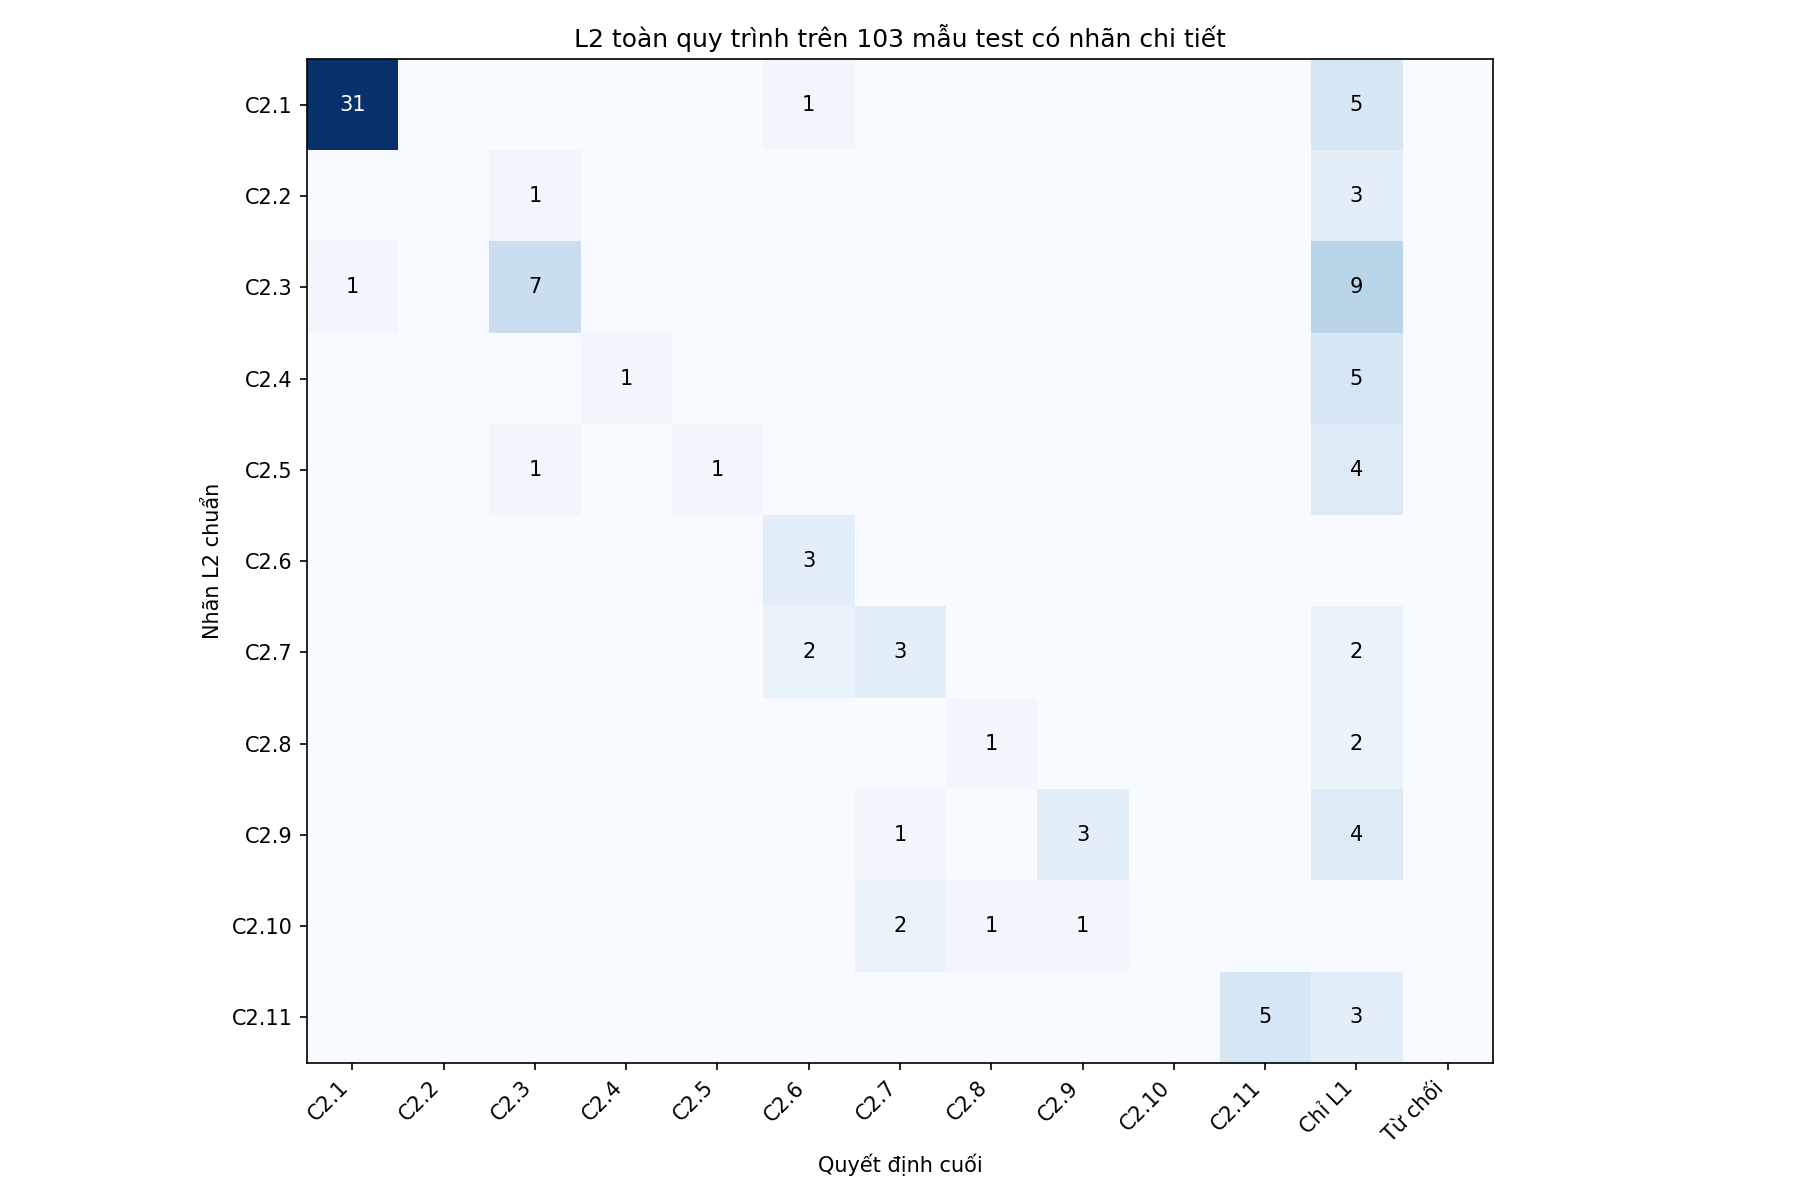

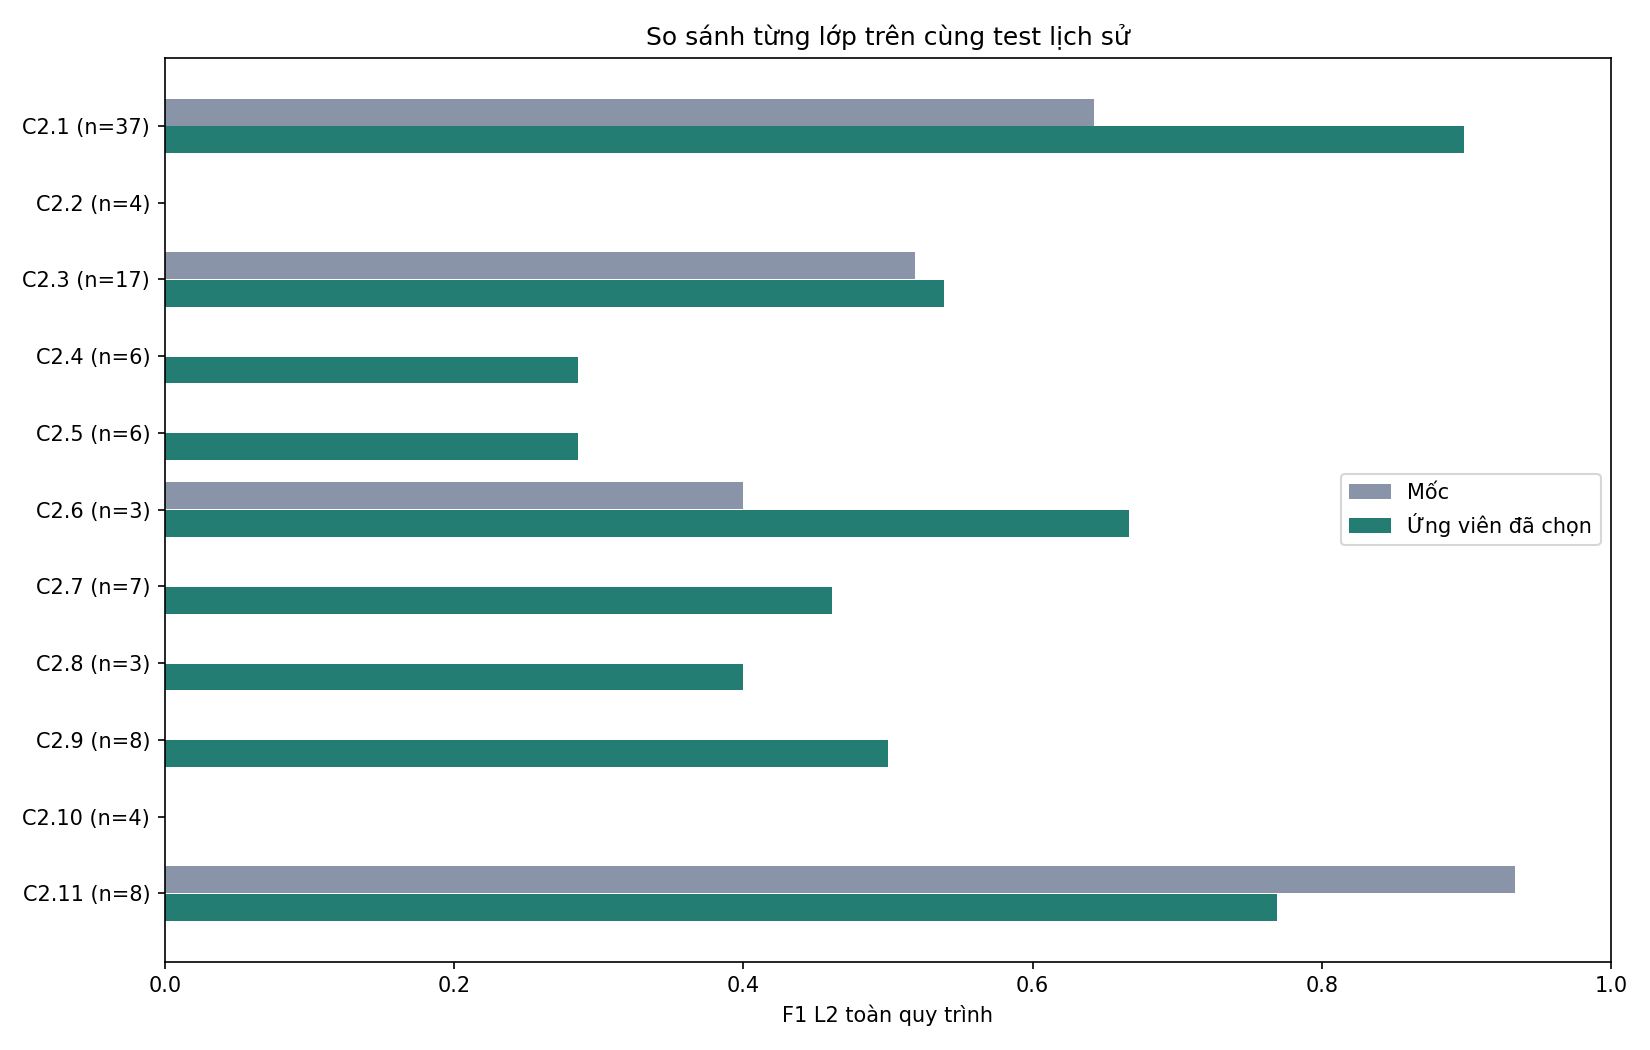

In [1]:
# Nạp phần hỗ trợ nhúng trong chính notebook, kể cả khi chạy riêng cell này.
from pathlib import Path
import json
_notebook_root = next(candidate.resolve()
    for base in [Path.cwd(), *Path.cwd().parents]
    for candidate in [base, base / "Thangka_Pose_Training"]
    if (candidate / "Thangka_Pose_Training.ipynb").is_file() and (candidate / "data").is_dir())
_notebook_document = json.loads((_notebook_root / "Thangka_Pose_Training.ipynb").read_text(encoding="utf-8"))
_support_cell = next(c for c in _notebook_document["cells"] if c.get("id") == "embedded-notebook-support")
exec(compile("".join(_support_cell["source"]), "<notebook support>", "exec"), globals())
_load_notebook_support(_notebook_root)

import pandas as pd
from IPython.display import display, Image as DisplayImage
_quality_root = _notebook_root
_quality_run = _quality_root / "outputs/quality_v2/20261103_convnext_branches"

def train_quality_upgrade():
    """Chạy/tiếp tục thí nghiệm ConvNeXt; chỉ gọi khi muốn huấn luyện."""
    from run_quality_upgrade import main
    main()

if (_quality_run / "selection.json").exists():
    _selection = json.loads((_quality_run / "selection.json").read_text(encoding="utf-8"))
    print("Run cải thiện:", _quality_run)
    print("Trạng thái lựa chọn:", _selection["status"])
    if (_quality_run / "test_metrics.json").exists():
        _old = json.loads((_quality_run / "baseline_test_metrics.json").read_text(encoding="utf-8"))
        _new = json.loads((_quality_run / "test_metrics.json").read_text(encoding="utf-8"))
        _keys = ["l1_accuracy", "l1_macro_f1", "macro_f1", "exact_recall", "precision", "blank_acceptance", "nonzero_classes"]
        display(pd.DataFrame({"Mốc": {k: _old[k] for k in _keys}, "Ứng viên": {k: _new[k] for k in _keys}}))
        _table = pd.DataFrame(_new["per_class"])
        _table["correct_before"] = [r["correct"] for r in _old["per_class"]]
        display(_table)
        for _figure in ["l2_confusion_final.png", "l2_f1_comparison.png"]:
            if (_quality_run / _figure).exists():
                display(DisplayImage(filename=str(_quality_run / _figure)))
    _active_path = _quality_root / "outputs/active_quality_v2.json"
    if _active_path.exists():
        print("Demo đang dùng:", json.loads(_active_path.read_text(encoding="utf-8"))["relative_run_dir"])
    else:
        print("Demo vẫn dùng mô hình mốc đã hoàn thành.")
else:
    print("Chưa có kết quả hoàn tất. Theo dõi outputs/quality_convnext_status.json.")
print("Để huấn luyện hoặc tiếp tục: gọi train_quality_upgrade(). Chạy cell này chỉ đọc báo cáo.")


**Nhận xét kết quả cải thiện**


Run: `20261103_convnext_branches`. Ngày lập: 03/11/2026.

Giữ nguyên 612 mẫu train, 136 validation, 125 test; giữ quan hệ L1–L2 và cơ chế từ chối theo đề tài.

Các vòng học lại phần phân loại trên đặc trưng cũ không đạt tất cả điều kiện nên không thay bản demo. Vòng ConvNeXt tinh chỉnh trực tiếp hai mạng từ trọng số ImageNet, lấy mẫu cân bằng hơn giữa các lớp trong train. Mẫu L2 trống chỉ học nhóm L1 và bằng chứng, không bị ép vào nhãn chi tiết.

Ứng viên chọn bằng validation: `convnext_branches_baseline0.5`.

**Trạng thái demo: chưa kích hoạt; giữ mô hình đang dùng.**

| Chỉ số validation | Mốc | Ứng viên |
|---|---:|---:|
| Accuracy L1 | 0.8971 | 0.9191 |
| Macro-F1 L1 | 0.8638 | 0.8971 |
| Macro-F1 L2 toàn quy trình | 0.3334 | 0.5600 |
| Macro-recall L2 | 0.2782 | 0.4876 |
| Precision L2 gộp | 0.9744 | 0.9538 |
| Tỷ lệ trả L2 trên mẫu trống | 0.0000 | 0.0333 |

Kiểm định ngưỡng qua ba fold theo hiện vật: macro-F1 0.5474, precision 0.9118, tỷ lệ trả L2 trên mẫu trống 0.0333.

### Kiểm tra trên test lịch sử

| Chỉ số | Mốc | Ứng viên |
|---|---:|---:|
| Accuracy L1 | 0.9040 | 0.8880 |
| Macro-F1 L1 | 0.8546 | 0.8386 |
| Macro-F1 L2 toàn quy trình | 0.2268 | 0.4369 |
| Tỷ lệ trả đúng L2 trên mẫu có L2 | 0.3204 | 0.5340 |
| Precision L2 gộp | 0.8462 | 0.8333 |
| Tỷ lệ trả L2 trên mẫu trống | 0.0909 | 0.0000 |
| Số lớp có ít nhất một mẫu L2 đúng | 4.0000 | 9.0000 |

| Lớp | Nhãn | Số mẫu | Đúng trước | Đúng sau | Precision sau | Recall sau | F1 sau |
|---|---|---:|---:|---:|---:|---:|---:|
| C2.1 | Ngồi bắt chéo khóa kín | 37 | 18 | 31 | 0.9688 | 0.8378 | 0.8986 |
| C2.2 | Ngồi bắt chéo không khóa kín | 4 | 0 | 0 | 0.0000 | 0.0000 | 0.0000 |
| C2.3 | Ngồi một chân co, một chân thả | 17 | 7 | 7 | 0.7778 | 0.4118 | 0.5385 |
| C2.4 | Ngồi hai chân thả | 6 | 0 | 1 | 1.0000 | 0.1667 | 0.2857 |
| C2.5 | Quỳ/ngồi trên gót | 6 | 0 | 1 | 1.0000 | 0.1667 | 0.2857 |
| C2.6 | Đứng thẳng, hai chân trụ | 3 | 1 | 3 | 0.5000 | 1.0000 | 0.6667 |
| C2.7 | Đứng lệch trọng tâm | 7 | 0 | 3 | 0.5000 | 0.4286 | 0.4615 |
| C2.8 | Một chân trụ, chân kia co/nâng | 3 | 0 | 1 | 0.5000 | 0.3333 | 0.4000 |
| C2.9 | Bước/chuyển hướng | 8 | 0 | 3 | 0.7500 | 0.3750 | 0.5000 |
| C2.10 | Động/múa | 4 | 0 | 0 | 0.0000 | 0.0000 | 0.0000 |
| C2.11 | Nằm nghiêng | 8 | 7 | 5 | 1.0000 | 0.6250 | 0.7692 |

Các lớp chưa trả đúng L2 trên test: C2.2 (Ngồi bắt chéo không khóa kín), C2.10 (Động/múa).

#### Phân tích vị trí phát sinh lỗi

Mỗi mẫu có L2 được xếp vào một trong bốn trường hợp theo thứ tự: sai nhóm L1; đúng L1 nhưng chọn sai ứng viên L2; chọn đúng ứng viên nhưng bị ngưỡng giữ lại; trả đúng L2. Các cột sau vì vậy không đếm trùng.

| Lớp | Train | Validation | Sai L1 | Sai ứng viên L2 | Đúng ứng viên nhưng bị giữ lại | Trả đúng L2 |
|---|---:|---:|---:|---:|---:|---:|
| C2.1 | 195 | 41 | 1 | 3 | 2 | 31 |
| C2.2 | 24 | 4 | 0 | 3 | 1 | 0 |
| C2.3 | 82 | 19 | 1 | 3 | 6 | 7 |
| C2.4 | 22 | 4 | 0 | 4 | 1 | 1 |
| C2.5 | 23 | 6 | 1 | 3 | 1 | 1 |
| C2.6 | 32 | 5 | 0 | 0 | 0 | 3 |
| C2.7 | 35 | 7 | 2 | 2 | 0 | 3 |
| C2.8 | 16 | 3 | 2 | 0 | 0 | 1 |
| C2.9 | 33 | 5 | 1 | 0 | 4 | 3 |
| C2.10 | 29 | 6 | 3 | 1 | 0 | 0 |
| C2.11 | 29 | 6 | 0 | 0 | 3 | 5 |

Sai L1 chặn đường tới nhãn con đúng; hạ ngưỡng L2 không sửa được lỗi này. Khi ứng viên L2 đã sai dù L1 đúng, mô hình chưa phân biệt tốt tư thế trong cùng nhóm. Khi ứng viên đúng nhưng bị giữ lại, hạn chế nằm ở độ tin cậy và cơ chế từ chối. Số liệu trên xác định vị trí lỗi trong quy trình, chưa chứng minh nguyên nhân thị giác như che khuất chân hay chất lượng ảnh; cần xem từng ảnh để kết luận những nguyên nhân đó.

Các lớp ít mẫu chỉ cung cấp ít trường hợp độc lập để học và kiểm tra. Lấy mẫu cân bằng giúp lớp hiếm xuất hiện thường xuyên hơn, nhưng không tạo thêm sự đa dạng của hiện vật. Hai mạng mới và ngưỡng theo nhánh đã tăng khả năng trả nhãn chi tiết, song chưa loại bỏ được nhầm lẫn giữa các nhóm tư thế.

Kiểm tra phát hành: không đạt. Số ảnh kiểm tra khớp suy luận từng ảnh: 0.

Ứng viên chưa được đưa vào demo: accuracy L1 giảm từ 0.9040 xuống 0.8880, precision L2 gộp thay đổi từ 0.8462 thành 0.8333. Mức tăng macro-F1 và số lớp nhận diện được chưa đủ để kết luận chất lượng tốt hơn trên mọi tiêu chí. Checkpoint mới vẫn được lưu để tái lập thí nghiệm. Không điều chỉnh lại ngưỡng theo lỗi test vừa quan sát.

### Cách diễn giải và giới hạn

Precision L2 gộp tính cả nhãn chi tiết trả sai trên mẫu L2 trống. Không so trực tiếp với selective accuracy chỉ tính trên mẫu có nhãn L2 của bảng cũ. Khi một lớp không có dự đoán, precision được quy ước là 0; điều đó khác với có dự đoán nhưng sai hết.

Ngưỡng mới kiểm soát precision gộp, không bảo đảm 90% cho từng lớp. Các lớp có ít mẫu vẫn có độ bất định lớn. Tập validation đã được dùng nhiều lần trong phát triển; cross-fitting ở đây chỉ kiểm tra ngưỡng, không phải nested cross-validation của cả quá trình học. Test cũng là benchmark lịch sử đã được xem trước; cần một tập độc lập mới để xác nhận khả năng khái quát hóa.

Bộ ước lượng keypoint và baseline keypoint được giữ để đối chiếu; lần thử này không chứng minh PCK/OKS tăng. Chỉ sử dụng các số liệu thực sự đo được để kết luận về bộ phân loại ảnh.

Xem `reports/development/QUALITY_V2_PROTOCOL.md`, `protocol.json`, `validation_trials.json`, `selection.json`, checkpoint và lịch sử để truy nguyên. Gọi `train_quality_upgrade()` tại mục 19 với nguyên cấu hình sẽ tiếp tục hoặc dùng lại checkpoint đã hoàn thành.


## Phụ lục. Mã hỗ trợ tích hợp

Cell dưới chứa mã nạp model, huấn luyện cải tiến và kiểm định. Mục 17 và 19 tự nạp phần này khi chạy riêng; không cần chạy file bên ngoài. Chạy cell này chỉ định nghĩa mã, không khởi động huấn luyện.


In [ ]:
# Mã hỗ trợ được lưu trực tiếp trong notebook để demo và huấn luyện không cần file .py bên ngoài.
_NOTEBOOK_SOURCES = {
'notebook_cells': '''"""Resolve executable notebook cells independently of explanatory markdown."""

CELL_KEY = "thangka_original_cell_index"


def get_code_cell(notebook, original_index):
    tagged = [cell for cell in notebook["cells"] if CELL_KEY in cell.get("metadata", {})]
    if tagged:
        matches = [cell for cell in tagged if cell["metadata"][CELL_KEY] == original_index]
        if len(matches) != 1 or matches[0]["cell_type"] != "code":
            raise ValueError(f"Missing or ambiguous code cell {original_index}")
        return matches[0]
    # Historical run snapshots predate stable cell metadata.
    cell = notebook["cells"][original_index]
    if cell["cell_type"] != "code":
        raise ValueError(f"Expected code at legacy cell {original_index}")
    return cell
''',
'quality_v2': '''"""Decoupled, class-balanced posture learning with validation-only selection.\r
\r
Backbones are frozen from the documented baseline (not an independent CV estimate\r
of the whole representation). Group cross-fitting assesses only the new gate.\r
No test examples are extracted until selection.json has been written.\r
"""\r
from __future__ import annotations\r
\r
import argparse\r
import copy\r
import csv\r
import hashlib\r
import json\r
import os\r
from pathlib import Path\r
from datetime import datetime\r
from zoneinfo import ZoneInfo\r
from concurrent.futures import ThreadPoolExecutor\r
\r
import joblib\r
import numpy as np\r
import torch\r
from PIL import Image, ImageOps, ImageEnhance\r
from sklearn.linear_model import LogisticRegression\r
from sklearn.svm import SVC\r
from sklearn.model_selection import StratifiedGroupKFold\r
from sklearn.preprocessing import normalize\r
from sklearn.calibration import CalibratedClassifierCV\r
from threadpoolctl import threadpool_limits\r
\r
from notebook_cells import get_code_cell\r
\r
CODE_DIR = Path(__file__).resolve().parent\r
ROOT = CODE_DIR.parent\r
BASE = ROOT / 'outputs/notebook_runs/20261031_174634_seed20261021'\r
VERSION = 1\r
\r
\r
def read_json(path):\r
    return json.loads(Path(path).read_text(encoding='utf-8'))\r
\r
\r
def write_json(path, value):\r
    path = Path(path)\r
    path.parent.mkdir(parents=True, exist_ok=True)\r
    temporary = path.with_suffix(path.suffix + '.tmp')\r
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')\r
    temporary.replace(path)\r
\r
\r
def utilities(root=ROOT, base=BASE):\r
    ns = dict(ROOT=root, DATA_DIR=root / 'data', IMAGE_SIZE=384, IMAGE_DROPOUT=.3,\r
              CLASS_WEIGHT_POWER=.5, MODEL_SCHEMA=4, L2_TARGET_PRECISION=.9,\r
              DEVICE='cuda' if torch.cuda.is_available() else 'cpu')\r
    notebook = read_json(base / 'source_notebook.ipynb')\r
    exec(compile(''.join(get_code_cell(notebook, 6)['source']), '<baseline utilities>', 'exec'), ns)\r
    ns['ontology'] = read_json(root / 'data/ontology.json')\r
    return ns\r
\r
\r
def softmax(x):\r
    x = np.asarray(x, dtype=np.float64)\r
    e = np.exp(x - x.max(axis=1, keepdims=True))\r
    return e / e.sum(axis=1, keepdims=True)\r
\r
\r
def subset(outputs, positions):\r
    return {k: v[positions] for k, v in outputs.items()}\r
\r
\r
def member_list(base=BASE):\r
    summary = read_json(base / 'SUMMARY.json')\r
    members = []\r
    for architecture in ('resnet18', 'mobilenet_v2'):\r
        for seed in (20261021, 20261031, 20261107):\r
            checkpoint = base / 'image_classifier' / f'{architecture}_seed{seed}' / 'best_model.pt'\r
            if not checkpoint.is_file():\r
                raise FileNotFoundError(checkpoint)\r
            members.append(dict(architecture=architecture, seed=seed, checkpoint=str(checkpoint),\r
                                sha256=hashlib.sha256(checkpoint.read_bytes()).hexdigest()))\r
    return members, summary\r
\r
\r
def image_pixels(image, view, ns):\r
    # Deterministic train-only augmentation; preserve the full body and support.\r
    if view == 1:\r
        image = ImageOps.mirror(image)\r
    elif view == 2:\r
        image = ImageEnhance.Color(image.rotate(5, expand=True, fillcolor='white')).enhance(.9)\r
    elif view == 3:\r
        image = ImageOps.mirror(image.rotate(-5, expand=True, fillcolor='white'))\r
        image = ImageEnhance.Contrast(image).enhance(1.08)\r
    return np.asarray(ns['ResizeWithPad'](384)(image), dtype=np.uint8)\r
\r
\r
def normalized_batch(pixels, device):\r
    tensor = torch.from_numpy(np.stack(pixels)).permute(0, 3, 1, 2).to(device).float().div_(255.)\r
    mean = tensor.new_tensor([.485, .456, .406])[None, :, None, None]\r
    std = tensor.new_tensor([.229, .224, .225])[None, :, None, None]\r
    return (tensor - mean) / std\r
\r
\r
def extract_features(rows, members, ns, cache_dir, split, views=1):\r
    """View-major order, exact instance IDs and checkpoint hashes in cache key."""\r
    cache_dir.mkdir(parents=True, exist_ok=True)\r
    provenance = dict(version=VERSION, split=split, views=views,\r
                      manifest=hashlib.sha256((ROOT / 'data/classification_manifest.csv').read_bytes()).hexdigest(),\r
                      ids=[r['instance_id'] for r in rows])\r
    pixel_signature = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()[:12]\r
    pixel_file = cache_dir / f'{split}_pixels_{pixel_signature}.npy'\r
    if not pixel_file.exists():\r
        partial = pixel_file.with_suffix('.partial.npy')\r
        pixels = np.lib.format.open_memmap(partial, mode='w+', dtype=np.uint8, shape=(views * len(rows), 384, 384, 3))\r
        def prepare(item):\r
            i, row = item\r
            with Image.open(ROOT / 'data' / row['crop_path']) as image:\r
                image = image.convert('RGB')\r
                return i, [image_pixels(image, view, ns) for view in range(views)]\r
        with ThreadPoolExecutor(max_workers=4) as pool:\r
            for start in range(0, len(rows), 16):\r
                for i, prepared in pool.map(prepare, list(enumerate(rows))[start:start+16]):\r
                    for view, pixels_view in enumerate(prepared):\r
                        pixels[view * len(rows) + i] = pixels_view\r
                if start % 64 == 0:\r
                    print(f'Prepare pixels {split}: {min(start+16, len(rows))}/{len(rows)}', flush=True)\r
        pixels.flush()\r
        del pixels\r
        partial.replace(pixel_file)\r
    pixels = np.load(pixel_file, mmap_mode='r')\r
    features, raw = [], []\r
    for member in members:\r
        signature = hashlib.sha256(json.dumps(dict(provenance, model=member['sha256']), sort_keys=True).encode()).hexdigest()\r
        file = cache_dir / f'{split}_{member["architecture"]}_{member["seed"]}_{signature[:12]}.npz'\r
        if file.exists():\r
            data = np.load(file)\r
            features.append(data['features'])\r
            raw.append({k: data[k] for k in ('l1_logits', 'l2_logits', 'l2_evidence_logits')})\r
            continue\r
        model, device, _ = ns['load_model'](member['architecture'], member['checkpoint'], ns['ontology'])\r
        arrays = {k: [] for k in ('features', 'l1_logits', 'l2_logits', 'l2_evidence_logits')}\r
        for start in range(0, len(pixels), 16):\r
            with torch.inference_mode():\r
                x = normalized_batch(pixels[start:start+16], device)\r
                f = model.backbone(x)\r
                for key, value in zip(arrays, (f, model.l1_head(f), model.l2_head(f), model.evidence_head(f))):\r
                    arrays[key].append(value.cpu().numpy())\r
            if start % 512 == 0:\r
                print(f'Extract {split} {member["architecture"]}/{member["seed"]}: {start}/{len(pixels)} on {device}', flush=True)\r
        data = {k: np.concatenate(v) for k, v in arrays.items()}\r
        np.savez_compressed(file, **data)\r
        features.append(data['features'])\r
        raw.append({k: data[k] for k in ('l1_logits', 'l2_logits', 'l2_evidence_logits')})\r
        del model\r
        if torch.cuda.is_available():\r
            torch.cuda.empty_cache()\r
        print(f'Features: {split}, {member["architecture"]}, seed {member["seed"]}, {len(data["features"])} views', flush=True)\r
    return features, raw\r
\r
\r
def feature_matrix(features, positions):\r
    # Normalize each representation separately so 1280 dimensions do not swamp 512.\r
    return np.concatenate([normalize(features[i]) for i in positions], axis=1) / np.sqrt(len(positions))\r
\r
\r
class BalancedHeads:\r
    """Learn new L1, global-leaf and evidence classifiers on frozen representations."""\r
    def __init__(self, kind, c, parent_indices):\r
        self.kind, self.c, self.parents = kind, c, np.asarray(parent_indices)\r
\r
    def fit(self, x, y1, y2, groups=None):\r
        known = y2 >= 0\r
        def model(target, target_groups):\r
            if self.kind == 'logistic':\r
                return LogisticRegression(C=self.c, class_weight='balanced', max_iter=2500, solver='lbfgs')\r
            estimator = SVC(C=self.c, kernel='rbf', gamma='scale', class_weight='balanced', probability=False)\r
            if self.kind == 'calibrated_svm':\r
                if target_groups is None:\r
                    raise ValueError('Calibration requires artifact groups including augmented copies.')\r
                folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=20261103).split(\r
                    np.zeros(len(target)), target, target_groups))\r
                for fit, held in folds:\r
                    assert not set(target_groups[fit]) & set(target_groups[held])\r
                return CalibratedClassifierCV(estimator, method='sigmoid', cv=folds, ensemble=False, n_jobs=1)\r
            return estimator\r
        groups = np.asarray(groups) if groups is not None else None\r
        self.l1 = model(y1, groups).fit(x, y1)\r
        self.leaf = model(y2[known], groups[known] if groups is not None else None).fit(x[known], y2[known])\r
        self.evidence = model(known.astype(int), groups).fit(x, known.astype(int))\r
        assert np.array_equal(self.l1.classes_, np.arange(4))\r
        assert np.array_equal(self.leaf.classes_, np.arange(11))\r
        return self\r
\r
    def probabilities(self, estimator, x):\r
        if hasattr(estimator, 'predict_proba'):\r
            return estimator.predict_proba(x)\r
        decision = estimator.decision_function(x)\r
        if decision.ndim == 1:\r
            decision = np.stack([-decision / 2, decision / 2], axis=1)\r
        # SVM scores are not calibrated probabilities; fitted gate must be assessed out of fold.\r
        return softmax(decision)\r
\r
    def outputs(self, x):\r
        leaf = self.probabilities(self.leaf, x)\r
        parent_from_leaf = np.column_stack([leaf[:, self.parents == i].sum(axis=1) for i in range(4)])\r
        p1 = .5 * self.probabilities(self.l1, x) + .5 * parent_from_leaf\r
        return dict(l1_logits=np.log(np.clip(p1, 1e-12, 1)),\r
                    l2_logits=np.log(np.clip(leaf, 1e-12, 1)),\r
                    l2_evidence_logits=np.log(np.clip(self.probabilities(self.evidence, x), 1e-12, 1)))\r
\r
\r
def add_labels(out, rows, indices, views=1):\r
    out = dict(out)\r
    out['y1'] = np.tile([indices['l1_to_idx'][r['level_1_code']] for r in rows], views)\r
    out['y2'] = np.tile([indices['l2_to_idx'].get(r['level_2_code'], -100) for r in rows], views)\r
    out['indices'] = np.arange(len(rows) * views)\r
    return out\r
\r
\r
def decision_arrays(outputs, indices):\r
    p1 = softmax(outputs['l1_logits'])\r
    l1 = p1.argmax(axis=1)\r
    candidate, confidence = np.zeros(len(l1), dtype=int), np.zeros(len(l1))\r
    for parent_idx, parent in enumerate(indices['l1_codes']):\r
        children = np.array([indices['l2_to_idx'][c] for c in indices['l2_codes'] if indices['l2_parent'][c] == parent])\r
        mask = l1 == parent_idx\r
        conditional = softmax(outputs['l2_logits'][mask][:, children])\r
        candidate[mask] = children[conditional.argmax(axis=1)]\r
        confidence[mask] = conditional.max(axis=1) * p1[mask, parent_idx]\r
    return l1, candidate, confidence, p1.max(axis=1), softmax(outputs['l2_evidence_logits'])[:, 1]\r
\r
\r
def score_decisions(outputs, candidate, accepted, l1, l1_accepted):\r
    gold = outputs['y2']\r
    known = gold >= 0\r
    correct = accepted & (candidate == gold)\r
    per_class = []\r
    for c in range(11):\r
        tp, pred, support = int((correct & (gold == c)).sum()), int((accepted & (candidate == c)).sum()), int((gold == c).sum())\r
        precision, recall = tp / max(pred, 1), tp / max(support, 1)\r
        per_class.append(dict(code=f'C2.{c+1}', support=support, predicted=pred, correct=tp,\r
                              precision=precision, recall=recall, f1=2*tp/max(pred+support, 1)))\r
    l1_confusion = np.zeros((4, 4), dtype=int)\r
    np.add.at(l1_confusion, (outputs['y1'], l1), 1)\r
    l1_f1 = [2*l1_confusion[c,c]/max(l1_confusion[c,:].sum()+l1_confusion[:,c].sum(),1) for c in range(4)]\r
    return dict(l1_accuracy=float((l1 == outputs['y1']).mean()), l1_macro_f1=float(np.mean(l1_f1)),\r
                l1_confusion_matrix=l1_confusion.tolist(),\r
                l1_selective_accuracy=float(((l1 == outputs['y1']) & l1_accepted).sum()/max(l1_accepted.sum(), 1)),\r
                l1_coverage=float(l1_accepted.mean()),\r
                macro_f1=float(np.mean([c['f1'] for c in per_class])),\r
                macro_recall=float(np.mean([c['recall'] for c in per_class])),\r
                precision=float(correct.sum()/max(accepted.sum(), 1)),\r
                blank_acceptance=float((accepted & ~known).sum()/max((~known).sum(), 1)),\r
                exact_recall=float(correct.sum()/max(known.sum(), 1)),\r
                accepted=int(accepted.sum()), correct=int(correct.sum()),\r
                nonzero_classes=sum(c['correct'] > 0 for c in per_class), per_class=per_class)\r
\r
\r
def apply_gate(outputs, indices, gate):\r
    l1, candidate, confidence, l1_conf, evidence = decision_arrays(outputs, indices)\r
    l1_ok = l1_conf >= gate['l1_threshold']\r
    cutoffs = np.array([gate['class_thresholds'].get(f'C2.{c+1}', gate['l2_threshold']) for c in candidate])\r
    accepted = l1_ok & (confidence >= cutoffs) & (evidence >= gate['evidence_threshold'])\r
    return score_decisions(outputs, candidate, accepted, l1, l1_ok), (candidate, accepted, l1, l1_ok)\r
\r
\r
def select_gate(outputs, indices, min_precision=.90):\r
    """Pooled gate: avoid declaring a rare class unusable from three examples.\r
\r
    Target remains >=90% pooled precision, <=10% blank acceptance. This does NOT\r
    promise 90% for every class. Candidate thresholds are fixed before test access.\r
    """\r
    l1, candidate, conf, l1_conf, evidence = decision_arrays(outputs, indices)\r
    l1_options = []\r
    for cutoff in (0., .4, .5, .6, .7):\r
        mask = l1_conf >= cutoff\r
        if mask.mean() >= .75 and ((l1 == outputs['y1']) & mask).sum()/max(mask.sum(), 1) >= .90:\r
            l1_options.append(cutoff)\r
    l1_cutoff = min(l1_options) if l1_options else 0.\r
    best = None\r
    for threshold in np.arange(.1, 1., .05):\r
        for evidence_cutoff in (0., .5, .7, .85, .95):\r
            accepted = (l1_conf >= l1_cutoff) & (conf >= threshold) & (evidence >= evidence_cutoff)\r
            metrics = score_decisions(outputs, candidate, accepted, l1, l1_conf >= l1_cutoff)\r
            if metrics['accepted'] >= 6 and metrics['precision'] >= min_precision and metrics['blank_acceptance'] <= .10:\r
                ranking = (metrics['macro_f1'], metrics['macro_recall'], metrics['precision'])\r
                if best is None or ranking > best[0]:\r
                    best = (ranking, dict(l1_threshold=l1_cutoff, l2_threshold=float(threshold), evidence_threshold=evidence_cutoff,\r
                                          class_thresholds={f'C2.{c+1}': float(threshold) for c in range(11)}), metrics)\r
    if best is None:\r
        gate = dict(l1_threshold=l1_cutoff, l2_threshold=1.0001, evidence_threshold=0., class_thresholds={})\r
        return gate, apply_gate(outputs, indices, gate)[0]\r
    return best[1], best[2]\r
\r
\r
def crossfit_gate(outputs, indices, folds, min_precision=.90):\r
    collected = [np.empty(len(outputs['y1']), dtype=dtype) for dtype in (int, bool, int, bool)]\r
    for fit, held in folds:\r
        gate, _ = select_gate(subset(outputs, fit), indices, min_precision)\r
        _, decisions = apply_gate(subset(outputs, held), indices, gate)\r
        for target, source in zip(collected, decisions):\r
            target[held] = source\r
    return score_decisions(outputs, *collected)\r
\r
\r
def promote_allowed(metrics, crossfit, baseline):\r
    """Predeclared constraints, never changed after reading test."""\r
    return (metrics['macro_f1'] >= baseline['macro_f1'] + .02\r
            and metrics['macro_recall'] > baseline['macro_recall']\r
            and metrics['l1_accuracy'] >= baseline['l1_accuracy'] - 1/136\r
            and metrics.get('l1_macro_f1',1.) >= baseline.get('l1_macro_f1',1.) - .02\r
            and metrics['precision'] >= max(.90, baseline['precision'] - .05)\r
            and metrics['blank_acceptance'] <= .10\r
            and crossfit['precision'] >= .85\r
            and crossfit['blank_acceptance'] <= .15\r
            and crossfit['macro_f1'] >= baseline['macro_f1']\r
            and metrics['nonzero_classes'] > baseline['nonzero_classes'])\r
\r
\r
def main(argv=None):\r
    parser = argparse.ArgumentParser()\r
    parser.add_argument('--run-dir', type=Path)\r
    parser.add_argument('--extended', action='store_true', help='Train group-calibrated heads and predeclared 50/50 baseline blends')\r
    args = parser.parse_args(argv)\r
    torch.set_num_threads(4)\r
    ns = utilities()\r
    snapshot = ns['load_snapshot']()\r
    audit = ns['audit_snapshot'](snapshot)\r
    indices = ns['class_index_maps'](snapshot['ontology'])\r
    members, summary = member_list()\r
    run = args.run_dir or ROOT / 'outputs/quality_v2' / datetime.now(ZoneInfo('Asia/Bangkok')).strftime('%Y%m%d_%H%M%S')\r
    run.mkdir(parents=True, exist_ok=True)\r
    print('RUN', run, flush=True)\r
    write_json(ROOT / 'outputs/quality_v2_status.json', dict(state='running', run=str(run), pid=os.getpid()))\r
    protocol = dict(version=VERSION, baseline=str(BASE), manifest_sha256=audit['manifest_sha256'],\r
                    train_views=4, groups=['resnet18', 'mobilenet_v2', 'all'],\r
                    classifiers={'logistic': [.1, 1., 10.], 'rbf_svm': [1., 10., 100.]},\r
                    selection='validation only; group-crossfit of gate; test after locked selection',\r
                    limitations='Frozen backbones were selected on historical validation. Gate crossfit is not nested CV of the full pipeline.',\r
                    promotion_rule='macro-F1 +.02; macro-recall increase; L1 accuracy lose <=1/136; pooled precision >=max(.90, baseline-.05); blank acceptance <=.10; crossfit precision >=.85, blank<=.15, F1>=baseline; more nonzero classes')\r
    if args.extended:\r
        protocol.update(groups=['resnet18', 'all'], classifiers={'logistic': [10., 100.], 'calibrated_svm': [1., 10.]},\r
                        baseline_blends=[0., .5], calibration='3 artifact-group folds within train; augmented views stay together')\r
    if (run / 'protocol.json').exists() and read_json(run / 'protocol.json') != protocol:\r
        raise RuntimeError('Cannot resume with a different protocol')\r
    write_json(run / 'protocol.json', protocol)\r
    (run / 'quality_v2_source.py').write_bytes(Path(__file__).read_bytes())\r
    rows = {split: [r for r in snapshot['rows'] if r['split'] == split] for split in ('train', 'val', 'test')}\r
    train_features, _ = extract_features(rows['train'], members, ns, ROOT / 'cache/quality_v2/features', 'train', 4)\r
    val_features, val_raw = extract_features(rows['val'], members, ns, ROOT / 'cache/quality_v2/features', 'val')\r
    baseline_members = summary['image_selection']['members']\r
    def baseline_outputs(raw, split):\r
        calibrated = []\r
        for m in baseline_members:\r
            pos = next(i for i, full in enumerate(members) if (m['architecture'], m['seed']) == (full['architecture'], full['seed']))\r
            calibrated.append(ns['apply_temperatures'](add_labels(raw[pos], rows[split], indices), m['temperatures']))\r
        return ns['average_hierarchical_outputs'](calibrated, indices)\r
    baseline_out = baseline_outputs(val_raw, 'val')\r
    baseline_gate = read_json(BASE / 'deployment/selection.json')['selected']\r
    assert baseline_gate['image_weight'] == 1., 'Baseline adapter requires image-only original deployment.'\r
    baseline_metrics = apply_gate(baseline_out, indices, baseline_gate)[0]\r
    write_json(run / 'baseline_validation.json', baseline_metrics)\r
    strata = [r['level_2_code'] or ('blank_' + r['level_1_code']) for r in rows['val']]\r
    groups = [r['artifact_id'] for r in rows['val']]\r
    folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=20261103).split(np.zeros(len(groups)), strata, groups))\r
    for fit, held in folds:\r
        assert not set(np.asarray(groups)[fit]) & set(np.asarray(groups)[held])\r
    write_json(run / 'gate_folds.json', [{k: [rows['val'][int(i)]['instance_id'] for i in v] for k, v in [('fit', fit), ('held', held)]} for fit, held in folds])\r
    parent_indices = [indices['l1_to_idx'][indices['l2_parent'][code]] for code in indices['l2_codes']]\r
    labels = add_labels({}, rows['train'], indices, 4)\r
    trials, candidates = [], {}\r
    def register(name, out, state):\r
        gate, metrics = select_gate(out, indices)\r
        crossfit = crossfit_gate(out, indices, folds)\r
        allowed = promote_allowed(metrics, crossfit, baseline_metrics)\r
        record = dict(name=name, gate=gate, validation=metrics, crossfit=crossfit, eligible=allowed)\r
        trials.append(record)\r
        candidates[name] = (out, state)\r
        write_json(run / 'validation_trials.json', trials)\r
        joblib.dump(state, run / (name + '.joblib'))\r
        print(f'{name}: F1={metrics["macro_f1"]:.3f}, precision={metrics["precision"]:.3f}, classes={metrics["nonzero_classes"]}, crossfit F1={crossfit["macro_f1"]:.3f}, eligible={allowed}', flush=True)\r
    register('baseline_rethreshold', baseline_out, dict(kind='baseline'))\r
    for group, positions in [('resnet18', [0, 1, 2]), ('mobilenet_v2', [3, 4, 5]), ('all', list(range(6)))]:\r
        if group not in protocol['groups']:\r
            continue\r
        x = feature_matrix(train_features, positions)\r
        xv = feature_matrix(val_features, positions)\r
        for kind, cs in protocol['classifiers'].items():\r
            for c in cs:\r
                name = f'{group}_{kind}_{c:g}'\r
                with threadpool_limits(limits=4):\r
                    heads = BalancedHeads(kind, c, parent_indices).fit(x, labels['y1'], labels['y2'],\r
                        np.tile([r['artifact_id'] for r in rows['train']], 4))\r
                    out = add_labels(heads.outputs(xv), rows['val'], indices)\r
                state = dict(kind='balanced_heads', heads=heads, positions=positions, members=members,\r
                             manifest_sha256=audit['manifest_sha256'], baseline=str(BASE), version=VERSION)\r
                register(name, out, state)\r
                if args.extended:\r
                    mixed = ns['average_hierarchical_outputs']([out, baseline_out], indices, [.5, .5])\r
                    register(name + '_blend', mixed, dict(state, blend_baseline=.5, baseline_members=baseline_members))\r
    eligible = [trial for trial in trials if trial['eligible'] and trial['name'] != 'baseline_rethreshold']\r
    chosen = max(eligible, key=lambda t: (t['crossfit']['macro_f1'], t['validation']['macro_f1'])) if eligible else None\r
    selection = dict(chosen=chosen, promoted=False, status='selected' if chosen else 'no_candidate_passed',\r
                     baseline_validation=baseline_metrics, test_used_for_selection=False)\r
    write_json(run / 'selection.json', selection)\r
    # Selection is now locked. Historical test is used only for a descriptive audit.\r
    if chosen:\r
        state = candidates[chosen['name']][1]\r
        joblib.dump(state, run / 'selected_model.joblib')\r
        test_features, test_raw = extract_features(rows['test'], members, ns, ROOT / 'cache/quality_v2/features', 'test')\r
        out = add_labels(state['heads'].outputs(feature_matrix(test_features, state['positions'])), rows['test'], indices)\r
        baseline_test = baseline_outputs(test_raw, 'test')\r
        if state.get('blend_baseline'):\r
            out = ns['average_hierarchical_outputs']([out, baseline_test], indices, [.5, .5])\r
        metrics, decisions = apply_gate(out, indices, chosen['gate'])\r
        write_json(run / 'test_metrics.json', metrics)\r
        write_json(run / 'baseline_test_metrics.json', apply_gate(baseline_test, indices, baseline_gate)[0])\r
        ns['save_test_predictions'](run / 'test_predictions.csv', snapshot['rows'], out, indices,\r
                                   chosen['gate']['l2_threshold'], chosen['gate']['l1_threshold'], None,\r
                                   chosen['gate']['evidence_threshold'], chosen['gate']['class_thresholds'])\r
        with (run / 'per_class_end_to_end.csv').open('w', encoding='utf-8-sig', newline='') as stream:\r
            writer = csv.DictWriter(stream, fieldnames=list(metrics['per_class'][0]))\r
            writer.writeheader(); writer.writerows(metrics['per_class'])\r
        # Activation is a separate, verified operation after checking inference parity.\r
        print('Selected candidate saved; awaiting inference-parity verification before activation.', flush=True)\r
    write_json(ROOT / 'outputs/quality_v2_status.json', dict(state='completed', run=str(run), selected=chosen['name'] if chosen else None))\r
    print('COMPLETED', json.dumps(selection, ensure_ascii=False), flush=True)\r
\r
\r
if __name__ == '__main__':\r
    # Avoid pickles referencing __main__ when the notebook loads trained heads later.\r
    from quality_v2 import main\r
    main()\r
''',
'quality_convnext': '''"""Fine-tune ConvNeXt for the existing two-level posture task.

Train-only balanced sampling, full-body input, blank-L2 masking, resumable AdamW.
Historical test is read only after a validation-selected candidate passes gates.
"""
from __future__ import annotations
import argparse
import csv
import hashlib
import json
import os
from pathlib import Path
import time

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import convnext_tiny
from sklearn.model_selection import StratifiedGroupKFold

from quality_v2 import (ROOT, BASE, read_json, write_json, utilities, normalized_batch,
                        extract_features, member_list, add_labels, select_gate,
                        crossfit_gate, apply_gate, promote_allowed)


class PostureConvNeXt(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()
        self.backbone = convnext_tiny(weights=None, stochastic_depth_prob=.1)
        if pretrained:
            path = ROOT / 'pretrained/convnext_tiny-983f1562.pth'
            if not hashlib.sha256(path.read_bytes()).hexdigest().startswith('983f1562'):
                raise ValueError('Invalid pretrained checkpoint hash')
            self.backbone.load_state_dict(torch.load(path, map_location='cpu', weights_only=True))
        self.backbone.classifier[2] = nn.Identity()
        self.dropout = nn.Dropout(.2)
        self.l1 = nn.Linear(768, 4)
        self.l2 = nn.Linear(768, 11)
        self.evidence = nn.Linear(768, 2)

    def forward(self, x):
        f = self.dropout(self.backbone(x))
        return self.l1(f), self.l2(f), self.evidence(f)


def outputs_from_model(model, pixels, rows, indices, device='cuda'):
    model.eval()
    values = [[], [], []]
    with torch.inference_mode():
        for start in range(0, len(pixels), 4):
            with torch.autocast(device_type=device, enabled=device == 'cuda'):
                out = model(normalized_batch(pixels[start:start+4], device))
            for destination, source in zip(values, out):
                destination.append(source.float().cpu().numpy())
    raw = dict(zip(('l1_logits', 'l2_logits', 'l2_evidence_logits'), [np.concatenate(v) for v in values]))
    # Parent mass from the globally trained leaves supplements the separate L1 head.
    p1 = torch.softmax(torch.tensor(raw['l1_logits']), 1).numpy()
    leaves = torch.softmax(torch.tensor(raw['l2_logits']), 1).numpy()
    parent = np.zeros_like(p1)
    for c, code in enumerate(indices['l2_codes']):
        parent[:, indices['l1_to_idx'][indices['l2_parent'][code]]] += leaves[:, c]
    raw['l1_logits'] = np.log(np.clip(.5*p1 + .5*parent, 1e-12, 1))
    return add_labels(raw, rows, indices) if rows is not None else raw


def cached_pixels(split):
    manifest = ROOT / 'data/classification_manifest.csv'
    with manifest.open(encoding='utf-8-sig', newline='') as stream:
        rows = [r for r in csv.DictReader(stream) if r['split'] == split]
    provenance = dict(version=1, split=split, views=4 if split=='train' else 1,
                      manifest=hashlib.sha256(manifest.read_bytes()).hexdigest(), ids=[r['instance_id'] for r in rows])
    signature = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()[:12]
    path = ROOT / 'cache/quality_v2/features' / f'{split}_pixels_{signature}.npy'
    return np.load(path, mmap_mode='r')


def train_one(run, seed, epochs, ns, snapshot, indices, smoke=False):
    target = run / f'convnext_tiny_seed{seed}'
    target.mkdir(parents=True, exist_ok=True)
    signature = dict(seed=seed, epochs=epochs, smoke=smoke, batch=2, accumulation=8,
                     manifest=hashlib.sha256((ROOT/'data/classification_manifest.csv').read_bytes()).hexdigest(),
                     source=hashlib.sha256(Path(__file__).read_bytes()).hexdigest())
    if (target/'complete.json').exists():
        if read_json(target/'complete.json')['signature'] != signature:
            raise RuntimeError('Training signature changed')
        return dict(np.load(target/'validation_outputs.npz'))
    torch.manual_seed(seed); np.random.seed(seed)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model = PostureConvNeXt(pretrained=True).to(device)
    optimizer = torch.optim.AdamW([
        dict(params=model.backbone.parameters(), lr=2e-5),
        dict(params=list(model.l1.parameters())+list(model.l2.parameters())+list(model.evidence.parameters()), lr=3e-4)
    ], weight_decay=.001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=device=='cuda')
    rows = [r for r in snapshot['rows'] if r['split']=='train']
    val_rows = [r for r in snapshot['rows'] if r['split']=='val']
    train_pixels, val_pixels = cached_pixels('train'), cached_pixels('val')
    labels = add_labels({}, rows, indices)
    y1 = torch.tensor(labels['y1'], dtype=torch.long, device=device)
    y2 = torch.tensor(labels['y2'], dtype=torch.long, device=device)
    known = labels['y2'] >= 0
    counts = np.bincount(labels['y2'][known], minlength=11)
    probabilities = np.zeros(len(rows))
    probabilities[known] = 1/np.sqrt(counts[labels['y2'][known]])
    probabilities[known] *= .8/probabilities[known].sum()
    probabilities[~known] = .2/(~known).sum()
    state_path = target/'last_training_state.pt'
    history, best, waits, start_epoch = [], -1., 0, 1
    if state_path.exists():
        state = torch.load(state_path, map_location=device, weights_only=False)
        if state['signature'] != signature:
            raise RuntimeError('Resume settings/source mismatch')
        model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler']); scaler.load_state_dict(state['scaler'])
        history, best, waits = state['history'], state['best'], state['waits']
        start_epoch = state['epoch']+1
        torch.set_rng_state(state['rng'].cpu())
        if device=='cuda': torch.cuda.set_rng_state_all([x.cpu() for x in state['cuda_rng']])
        del state
    for epoch in range(start_epoch, epochs+1):
        if epoch > 24 and waits >= 16:
            break
        begin = time.monotonic()
        model.train()
        for p in model.backbone.parameters(): p.requires_grad = smoke or epoch > 3
        if epoch <= 10 and not smoke:
            for p in model.backbone.features[:4].parameters(): p.requires_grad = False
        if epoch <= 3 and not smoke: model.backbone.eval()
        rng = np.random.default_rng(seed+epoch)
        sample = rng.choice(len(rows), size=32 if smoke else len(rows), replace=True, p=probabilities)
        views = rng.integers(0, 4, size=len(sample))
        total, batches = 0., int(np.ceil(len(sample)/2))
        optimizer.zero_grad(set_to_none=True)
        for step in range(batches):
            batch_indices = sample[step*2:step*2+2]
            pixel_indices = batch_indices + views[step*2:step*2+2]*len(rows)
            x = normalized_batch(train_pixels[pixel_indices], device)
            gold1, gold2 = y1[batch_indices], y2[batch_indices]
            mask = gold2 >= 0
            with torch.autocast(device_type=device, enabled=device=='cuda'):
                z1, z2, ze = model(x)
                parent_loss = F.cross_entropy(z1.float(), gold1, label_smoothing=.03)
                leaf_loss = F.cross_entropy(z2.float()[mask], gold2[mask], label_smoothing=.03) if mask.any() else z2.sum()*0
                branch_loss = ns['hierarchical_l2_loss'](z2.float(), gold1, gold2, indices, label_smoothing=.03)
                evidence_loss = F.cross_entropy(ze.float(), mask.long())
                loss = parent_loss + leaf_loss + .5*branch_loss + .5*evidence_loss
            group_size = min(8, batches-(step//8)*8)
            scaler.scale(loss/group_size).backward()
            if (step+1)%8 == 0 or step+1 == batches:
                scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 3.)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
            total += float(loss.detach())
            if (step+1)%100 == 0:
                print(f'ConvNeXt {seed} epoch {epoch}, batch {step+1}/{batches}', flush=True)
        out = outputs_from_model(model, val_pixels, val_rows, indices, device)
        score = ns['quality_selection_score'](out, indices)
        quality = ns['metrics_from_outputs'](out, indices)
        if score > best + 1e-6:
            best, waits = score, 0
            torch.save({k: v.detach().cpu() for k,v in model.state_dict().items()}, target/'best_model.pt')
            np.savez_compressed(target/'validation_outputs.npz', **out)
        else:
            waits += 1
        scheduler.step()
        record = dict(epoch=epoch, loss=total/batches, score=score, best=best,
                      l1_accuracy=quality['l1']['accuracy'], l1_macro_f1=quality['l1']['macro_f1'],
                      seconds=time.monotonic()-begin)
        history.append(record)
        write_json(target/'history.json', history)
        temporary = target/'last_training_state.tmp'
        torch.save(dict(signature=signature, model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                        best=best, waits=waits, history=history, rng=torch.get_rng_state(),
                        cuda_rng=torch.cuda.get_rng_state_all() if device=='cuda' else []), temporary)
        temporary.replace(state_path)
        write_json(ROOT/'outputs/quality_convnext_status.json', dict(state='training', run=str(run), seed=seed, **record))
        print(json.dumps(dict(seed=seed, **record)), flush=True)
    write_json(target/'complete.json', dict(signature=signature, epochs=len(history), best=best))
    del model, optimizer, scaler
    if device=='cuda': torch.cuda.empty_cache()
    return dict(np.load(target/'validation_outputs.npz'))


def main(argv=None):
    parser = argparse.ArgumentParser()
    parser.add_argument('--smoke', action='store_true')
    parser.add_argument('--epochs', type=int, default=60)
    parser.add_argument('--seeds', type=int, nargs='+', default=[20261103, 20261113])
    parser.add_argument('--run-dir', type=Path, default=ROOT/'outputs/quality_v2/20261103_convnext')
    args = parser.parse_args(argv)
    torch.set_num_threads(4)
    ns = utilities(); snapshot = ns['load_snapshot'](); ns['audit_snapshot'](snapshot)
    indices = ns['class_index_maps'](snapshot['ontology'])
    run = args.run_dir.resolve(); run.mkdir(parents=True, exist_ok=True)
    if args.smoke:
        train_one(run, args.seeds[0], 1, ns, snapshot, indices, smoke=True)
        write_json(ROOT/'outputs/quality_convnext_status.json',dict(state='smoke_completed',run=str(run)))
        print('Smoke complete; not a quality result.'); return
    protocol = dict(architecture='convnext_tiny', seeds=args.seeds, epochs=args.epochs,
                    loss='L1 + global L2 + .5 conditional L2 + .5 evidence; blank L2 masked',
                    data='same fixed train/val/test; train-only sqrt inverse-frequency sampler; 384 full body',
                    gate_min_precision=.925, promotion='same constraints as quality_v2, no test selection',
                    ensemble_weights=[0., .25, .5], ensemble='all declared seeds equally weighted')
    if (run/'protocol.json').exists() and read_json(run/'protocol.json') != protocol:
        raise RuntimeError('Protocol mismatch')
    write_json(run/'protocol.json', protocol)
    (run/'quality_convnext_source.py').write_bytes(Path(__file__).read_bytes())
    print('FULL TRAINING', str(run), json.dumps(protocol), flush=True)
    validation = [train_one(run, seed, args.epochs, ns, snapshot, indices) for seed in args.seeds]
    # Compare the fixed multiseed ensemble, not a cherry-picked seed.
    new_out = ns['average_hierarchical_outputs'](validation, indices)
    members, summary = member_list()
    val_rows = [r for r in snapshot['rows'] if r['split']=='val']
    _, raw = extract_features(val_rows, members, ns, ROOT/'cache/quality_v2/features', 'val')
    original_members = summary['image_selection']['members']
    def baseline_outputs(raw, rows):
        outputs=[]
        for m in original_members:
            i = next(i for i,x in enumerate(members) if (x['architecture'],x['seed'])==(m['architecture'],m['seed']))
            outputs.append(ns['apply_temperatures'](add_labels(raw[i], rows, indices), m['temperatures']))
        return ns['average_hierarchical_outputs'](outputs, indices)
    old_out = baseline_outputs(raw, val_rows)
    old_gate = read_json(BASE/'deployment/selection.json')['selected']
    base_metrics = apply_gate(old_out, indices, old_gate)[0]
    folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=20261103).split(
        np.zeros(len(val_rows)), [r['level_2_code'] or 'blank' for r in val_rows], [r['artifact_id'] for r in val_rows]))
    trials=[]
    for weight in protocol['ensemble_weights']:
        out = ns['average_hierarchical_outputs']([new_out, old_out], indices, [1-weight, weight])
        gate, metrics = select_gate(out, indices, .925)
        crossfit = crossfit_gate(out, indices, folds, .925)
        trials.append(dict(name=f'convnext_ensemble_baseline{weight}', baseline_weight=weight, gate=gate,
                           validation=metrics, crossfit=crossfit, eligible=promote_allowed(metrics,crossfit,base_metrics)))
    write_json(run/'validation_trials.json', trials)
    eligible=[t for t in trials if t['eligible']]
    chosen=max(eligible,key=lambda t:(t['crossfit']['macro_f1'],t['validation']['macro_f1'])) if eligible else None
    selection=dict(chosen=chosen,promoted=False,status='selected' if chosen else 'no_candidate_passed',
                   baseline_validation=base_metrics,test_used_for_selection=False)
    write_json(run/'selection.json',selection)
    if chosen:
        test_rows=[r for r in snapshot['rows'] if r['split']=='test']
        _, raw=extract_features(test_rows,members,ns,ROOT/'cache/quality_v2/features','test')
        old_test=baseline_outputs(raw,test_rows)
        predictions=[]
        for seed in args.seeds:
            model=PostureConvNeXt().cuda()
            model.load_state_dict(torch.load(run/f'convnext_tiny_seed{seed}/best_model.pt',weights_only=True))
            predictions.append(outputs_from_model(model,cached_pixels('test'),test_rows,indices))
            del model; torch.cuda.empty_cache()
        new_test=ns['average_hierarchical_outputs'](predictions,indices)
        w=chosen['baseline_weight']
        out=ns['average_hierarchical_outputs']([new_test,old_test],indices,[1-w,w])
        metrics,_=apply_gate(out,indices,chosen['gate'])
        write_json(run/'test_metrics.json',metrics)
        write_json(run/'baseline_test_metrics.json',apply_gate(old_test,indices,old_gate)[0])
        gate=chosen['gate']
        ns['save_test_predictions'](run/'test_predictions.csv',snapshot['rows'],out,indices,
            gate['l2_threshold'],gate['l1_threshold'],None,gate['evidence_threshold'],gate['class_thresholds'])
        with (run/'per_class_end_to_end.csv').open('w',encoding='utf-8-sig',newline='') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(metrics['per_class'][0]));writer.writeheader();writer.writerows(metrics['per_class'])
    write_json(ROOT/'outputs/quality_convnext_status.json',dict(state='completed',run=str(run),selected=chosen['name'] if chosen else None))
    print('COMPLETED',json.dumps(selection,ensure_ascii=False),flush=True)


if __name__=='__main__':
    main()
''',
'branch_calibration': '''"""Low-dimensional hierarchical calibration: one L2 cutoff per parent branch.

Four thresholds share a pooled precision/blank constraint. This avoids fitting
eleven thresholds from tiny classes; group crossfit must still check stability.
"""
import numpy as np
from quality_v2 import decision_arrays, apply_gate, score_decisions, subset


def select_branch_gate(outputs, indices, min_precision=.925):
    l1, candidate, conf, l1_conf, evidence = decision_arrays(outputs, indices)
    gold = outputs['y2']; blank = gold < 0
    candidates_l1 = []
    for threshold in (0., .4, .5, .6, .7):
        mask = l1_conf >= threshold
        if mask.mean() >= .75 and ((l1 == outputs['y1']) & mask).sum()/max(mask.sum(),1) >= .9:
            candidates_l1.append(threshold)
    l1_threshold = min(candidates_l1) if candidates_l1 else 0.
    thresholds = np.r_[np.arange(.1, 1., .05), 1.0001]
    dims = len(thresholds)
    parents = np.array([indices['l1_to_idx'][indices['l2_parent'][c]] for c in indices['l2_codes']])
    best = None
    for evidence_threshold in (0., .5, .7, .85, .95):
        tables = []
        for parent in range(4):
            table = []
            for cutoff in thresholds:
                mask = (l1==parent) & (l1_conf>=l1_threshold) & (conf>=cutoff) & (evidence>=evidence_threshold)
                correct = mask & (candidate==gold)
                f1_sum = 0.
                for leaf in np.flatnonzero(parents==parent):
                    support = int((gold==leaf).sum())
                    count = int((mask & (candidate==leaf)).sum())
                    tp = int((correct & (gold==leaf)).sum())
                    f1_sum += 2*tp/max(support+count,1)
                table.append([int(mask.sum()),int(correct.sum()),int((mask & blank).sum()),f1_sum])
            tables.append(np.array(table))
        totals = []
        for field in range(4):
            total = 0.
            for parent in range(4):
                shape = [1]*4; shape[parent]=dims
                total = total + tables[parent][:,field].reshape(shape)
            totals.append(total)
        accepted, correct, blanks, score = totals
        precision = correct/np.maximum(accepted,1)
        valid = (accepted>=6) & (precision>=min_precision) & (blanks<=.10*max(blank.sum(),1))
        ranking = np.where(valid, score/11 + 1e-7*precision, -1.)
        flat = int(ranking.argmax())
        if ranking.flat[flat] < 0: continue
        position = np.unravel_index(flat,ranking.shape)
        if best is None or ranking.flat[flat]>best[0]:
            cutoffs = [float(thresholds[p]) for p in position]
            gate = dict(l1_threshold=l1_threshold,l2_threshold=0.,evidence_threshold=evidence_threshold,
                        class_thresholds={code:cutoffs[parents[i]] for i,code in enumerate(indices['l2_codes'])},
                        branch_thresholds=dict(zip(indices['l1_codes'],cutoffs)))
            best = (float(ranking.flat[flat]),gate)
    if best is None:
        gate = dict(l1_threshold=l1_threshold,l2_threshold=1.0001,evidence_threshold=0.,class_thresholds={})
    else: gate = best[1]
    return gate,apply_gate(outputs,indices,gate)[0]


def crossfit_branch_gate(outputs,indices,folds,min_precision=.925):
    collected=[np.empty(len(outputs['y1']),dtype=dtype) for dtype in (int,bool,int,bool)]
    for fit,held in folds:
        gate,_=select_branch_gate(subset(outputs,fit),indices,min_precision)
        _,decisions=apply_gate(subset(outputs,held),indices,gate)
        for target,source in zip(collected,decisions): target[held]=source
    return score_decisions(outputs,*collected)
''',
'calibrate_convnext_branches': '''"""Predeclared comparison of global and four-branch gates after CNN training.\r
\r
All selection reads validation only. Prior test results are never loaded here.\r
"""\r
from quality_v2 import *\r
from quality_convnext import PostureConvNeXt, cached_pixels, outputs_from_model\r
from branch_calibration import select_branch_gate, crossfit_branch_gate\r
\r
\r
def main():\r
    torch.set_num_threads(4)\r
    model_run=ROOT/'outputs/quality_v2/20261103_convnext'\r
    run=ROOT/'outputs/quality_v2/20261103_convnext_branches'\r
    run.mkdir(parents=True,exist_ok=True)\r
    protocol=read_json(model_run/'protocol.json')\r
    protocol.update(model_run=str(model_run.relative_to(ROOT)), calibration=['global','four_parent_branches'],\r
                    baseline_gate_ablation=True, prior_test_metrics_used=False)\r
    write_json(run/'protocol.json',protocol)\r
    for source in ('quality_convnext.py','quality_v2.py','branch_calibration.py','calibrate_convnext_branches.py'):\r
        (run/source).write_bytes((CODE_DIR/source).read_bytes())\r
    ns=utilities();snapshot=ns['load_snapshot']();indices=ns['class_index_maps'](ns['ontology'])\r
    val_rows=[r for r in snapshot['rows'] if r['split']=='val']\r
    members,summary=member_list()\r
    _,raw=extract_features(val_rows,members,ns,ROOT/'cache/quality_v2/features','val')\r
    def baseline_outputs(raw,rows):\r
        out=[]\r
        for m in summary['image_selection']['members']:\r
            i=next(i for i,x in enumerate(members) if (x['architecture'],x['seed'])==(m['architecture'],m['seed']))\r
            out.append(ns['apply_temperatures'](add_labels(raw[i],rows,indices),m['temperatures']))\r
        return ns['average_hierarchical_outputs'](out,indices)\r
    old_out=baseline_outputs(raw,val_rows)\r
    old_gate=read_json(BASE/'deployment/selection.json')['selected']\r
    baseline=apply_gate(old_out,indices,old_gate)[0]\r
    groups=np.array([r['artifact_id'] for r in val_rows])\r
    folds=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=20261103).split(\r
        np.zeros(len(val_rows)),[r['level_2_code'] or 'blank' for r in val_rows],groups))\r
    for fit,held in folds: assert not set(groups[fit]) & set(groups[held])\r
    write_json(run/'gate_folds.json',[{k:[val_rows[int(i)]['instance_id'] for i in v]\r
               for k,v in [('fit',fit),('held',held)]} for fit,held in folds])\r
    validation=[]\r
    for seed in protocol['seeds']:\r
        folder=model_run/f'convnext_tiny_seed{seed}'\r
        complete=read_json(folder/'complete.json')\r
        if complete['signature']['smoke']:raise RuntimeError('Smoke weights cannot be selected')\r
        validation.append(dict(np.load(folder/'validation_outputs.npz')))\r
    new_out=ns['average_hierarchical_outputs'](validation,indices)\r
    trials=[]\r
    for weight in [0.,.25,.5,1.]:\r
        out=ns['average_hierarchical_outputs']([new_out,old_out],indices,[1-weight,weight])\r
        for style,selector,crossfitter in [('global',select_gate,crossfit_gate),('branches',select_branch_gate,crossfit_branch_gate)]:\r
            gate,metrics=selector(out,indices,.925)\r
            crossfit=crossfitter(out,indices,folds,.925)\r
            record=dict(name=f'convnext_{style}_baseline{weight}',baseline_weight=weight,calibration=style,\r
                        gate=gate,validation=metrics,crossfit=crossfit,\r
                        eligible=promote_allowed(metrics,crossfit,baseline))\r
            trials.append(record)\r
            print(record['name'],json.dumps({k:v for k,v in metrics.items() if k!='per_class'}),\r
                  'crossfit',crossfit['macro_f1'],crossfit['precision'],'eligible',record['eligible'],flush=True)\r
    write_json(run/'validation_trials.json',trials)\r
    eligible=[t for t in trials if t['eligible']]\r
    chosen=max(eligible,key=lambda t:(t['crossfit']['macro_f1'],t['validation']['macro_f1'])) if eligible else None\r
    selection=dict(chosen=chosen,promoted=False,status='selected' if chosen else 'no_candidate_passed',\r
                   baseline_validation=baseline,test_used_for_selection=False)\r
    write_json(run/'selection.json',selection)\r
    if chosen:\r
        test_rows=[r for r in snapshot['rows'] if r['split']=='test']\r
        _,raw=extract_features(test_rows,members,ns,ROOT/'cache/quality_v2/features','test')\r
        old=baseline_outputs(raw,test_rows)\r
        device='cuda' if torch.cuda.is_available() else 'cpu'\r
        predictions=[]\r
        for seed in protocol['seeds']:\r
            model=PostureConvNeXt().to(device)\r
            model.load_state_dict(torch.load(model_run/f'convnext_tiny_seed{seed}/best_model.pt',map_location=device,weights_only=True))\r
            predictions.append(outputs_from_model(model,cached_pixels('test'),test_rows,indices,device))\r
            del model\r
            if device=='cuda':torch.cuda.empty_cache()\r
        new=ns['average_hierarchical_outputs'](predictions,indices)\r
        weight=chosen['baseline_weight']\r
        out=ns['average_hierarchical_outputs']([new,old],indices,[1-weight,weight])\r
        np.savez_compressed(run/'test_outputs.npz',**out)\r
        metrics,_=apply_gate(out,indices,chosen['gate'])\r
        write_json(run/'test_metrics.json',metrics)\r
        write_json(run/'baseline_test_metrics.json',apply_gate(old,indices,old_gate)[0])\r
        gate=chosen['gate']\r
        ns['save_test_predictions'](run/'test_predictions.csv',snapshot['rows'],out,indices,\r
            gate['l2_threshold'],gate['l1_threshold'],None,gate['evidence_threshold'],gate['class_thresholds'])\r
        with (run/'per_class_end_to_end.csv').open('w',encoding='utf-8-sig',newline='') as stream:\r
            writer=csv.DictWriter(stream,fieldnames=list(metrics['per_class'][0]));writer.writeheader();writer.writerows(metrics['per_class'])\r
    write_json(ROOT/'outputs/quality_v2_status.json',dict(state='completed',run=str(run),selected=chosen['name'] if chosen else None))\r
    print('COMPLETED',chosen['name'] if chosen else 'No candidate passed',flush=True)\r
\r
\r
if __name__=='__main__':main()\r
''',
'quality_v2_demo': '''"""Load a validated decoupled classifier without training or threshold fitting."""
from pathlib import Path
import hashlib

import joblib
import torch
from PIL import Image

from quality_v2 import read_json, feature_matrix, image_pixels, normalized_batch


def make_predictor(run_dir, namespace):
    run_dir = Path(run_dir).resolve()
    if read_json(run_dir / 'protocol.json').get('architecture') == 'convnext_tiny':
        return make_convnext_predictor(run_dir, namespace)
    state = joblib.load(run_dir / 'selected_model.joblib')
    root = namespace['ROOT']
    manifest_hash = hashlib.sha256((root / 'data/classification_manifest.csv').read_bytes()).hexdigest()
    if state['manifest_sha256'] != manifest_hash:
        raise RuntimeError('Dữ liệu hiện tại khác dữ liệu của bộ phân loại cải tiến.')
    models = {}
    required_positions = set(state['positions'])
    if state.get('blend_baseline') or state.get('retain_baseline_l1_evidence'):
        for original in state['baseline_members']:
            required_positions.add(next(i for i, m in enumerate(state['members'])
                if (m['architecture'], m['seed']) == (original['architecture'], original['seed'])))
    for i in sorted(required_positions):
        member = state['members'][i]
        checkpoint = Path(member['checkpoint'])
        if hashlib.sha256(checkpoint.read_bytes()).hexdigest() != member['sha256']:
            raise RuntimeError(f'Checkpoint đã thay đổi: {checkpoint}')
        models[i] = namespace['load_model'](member['architecture'], checkpoint, namespace['ontology'], 'cpu')[0]

    def collect(image_path, members=None, indices=None):
        with Image.open(image_path) as image:
            pixels = image_pixels(image.convert('RGB'), 0, namespace)
        device = namespace.get('DEVICE', 'cpu')
        x = normalized_batch([pixels], device)
        features = [None] * len(state['members'])
        original_outputs = {}
        with torch.inference_mode():
            for i, model in models.items():
                model.to(device)
                features_tensor = model.backbone(x)
                features[i] = features_tensor.cpu().numpy()
                original_outputs[i] = dict(l1_logits=model.l1_head(features_tensor).cpu().numpy(),
                                           l2_logits=model.l2_head(features_tensor).cpu().numpy(),
                                           l2_evidence_logits=model.evidence_head(features_tensor).cpu().numpy())
                model.to('cpu')
        out = state['heads'].outputs(feature_matrix(features, state['positions']))
        if state.get('blend_baseline') or state.get('retain_baseline_l1_evidence'):
            calibrated = []
            for m in state['baseline_members']:
                i = next(i for i, full in enumerate(state['members'])
                         if (m['architecture'], m['seed']) == (full['architecture'], full['seed']))
                calibrated.append(namespace['apply_temperatures'](original_outputs[i], m['temperatures']))
            baseline = namespace['average_hierarchical_outputs'](calibrated, namespace['indices'])
            if state.get('retain_baseline_l1_evidence'):
                out['l1_logits'] = baseline['l1_logits']
                out['l2_evidence_logits'] = baseline['l2_evidence_logits']
                if state['leaf_blend']:
                    out = namespace['average_hierarchical_outputs']([out, baseline], namespace['indices'], [.5, .5])
            else:
                out = namespace['average_hierarchical_outputs']([out, baseline], namespace['indices'], [.5, .5])
        return out
    return collect


def make_convnext_predictor(run_dir, namespace):
    from quality_convnext import PostureConvNeXt, outputs_from_model
    protocol = read_json(run_dir / 'protocol.json')
    model_run = (namespace['ROOT'] / protocol['model_run']).resolve() if protocol.get('model_run') else run_dir
    if not model_run.is_relative_to(namespace['ROOT'] / 'outputs/quality_v2'):
        raise ValueError('Invalid ConvNeXt model path')
    selected = read_json(run_dir / 'selection.json')['chosen']
    if not selected:
        raise RuntimeError('ConvNeXt has no eligible selected candidate')
    if selected['baseline_weight'] == 1.:
        original_collect = namespace['collect_image_path']
        original_members = namespace['image_members']
        original_indices = namespace['indices']
        return lambda image_path, members=None, indices=None: original_collect(image_path, original_members, original_indices)
    manifest_hash = hashlib.sha256((namespace['ROOT'] / 'data/classification_manifest.csv').read_bytes()).hexdigest()
    models = []
    for seed in protocol['seeds']:
        folder = model_run / f'convnext_tiny_seed{seed}'
        complete = read_json(folder / 'complete.json')
        if complete['signature']['manifest'] != manifest_hash or complete['signature']['smoke']:
            raise RuntimeError('ConvNeXt checkpoint data/signature mismatch')
        model = PostureConvNeXt()
        model.load_state_dict(torch.load(folder / 'best_model.pt', map_location='cpu', weights_only=True))
        models.append(model.eval())
    original_collect = namespace['collect_image_path']
    original_members = namespace['image_members']
    indices = namespace['indices']
    def collect(image_path, members=None, unused_indices=None):
        with Image.open(image_path) as image:
            pixels = image_pixels(image.convert('RGB'), 0, namespace)
        device = namespace['DEVICE']
        outputs=[]
        for model in models:
            model.to(device)
            outputs.append(outputs_from_model(model, [pixels], None, indices, device))
            model.to('cpu')
        new = namespace['average_hierarchical_outputs'](outputs, indices)
        weight = selected['baseline_weight']
        if weight:
            old = original_collect(image_path, original_members, indices)
            new = namespace['average_hierarchical_outputs']([new, old], indices, [1-weight, weight])
        return new
    return collect


def apply_active_candidate(namespace):
    """Only an explicitly activated, parity-checked artifact changes the demo."""
    pointer = namespace['ROOT'] / 'outputs/active_quality_v2.json'
    if not pointer.exists():
        return namespace
    active = read_json(pointer)
    run_dir = (namespace['ROOT'] / active['relative_run_dir']).resolve()
    if not run_dir.is_relative_to(namespace['ROOT'] / 'outputs/quality_v2'):
        raise ValueError('Invalid active model path')
    selection = read_json(run_dir / 'selection.json')
    chosen = selection.get('chosen') or {}
    if not chosen.get('eligible') or not active.get('inference_parity_passed'):
        raise RuntimeError('Mô hình cải tiến chưa vượt qua kiểm tra chất lượng và suy luận.')
    if hashlib.sha256((run_dir / 'selection.json').read_bytes()).hexdigest() != active.get('selection_sha256'):
        raise RuntimeError('Cấu hình mô hình đã thay đổi sau khi kiểm tra.')
    release = read_json(run_dir / 'release_audit.json')
    if not (release.get('test_release_passed') and release.get('inference_parity_passed')):
        raise RuntimeError('Mô hình chưa đạt kiểm tra cuối trước khi sử dụng.')
    for relative, expected in active.get('artifact_sha256', {}).items():
        artifact = (namespace['ROOT'] / relative).resolve()
        if not artifact.is_relative_to(namespace['ROOT']) or hashlib.sha256(artifact.read_bytes()).hexdigest() != expected:
            raise RuntimeError(f'Tệp mô hình hoặc mã suy luận đã thay đổi sau kiểm định: {relative}')
    gate = selection['chosen']['gate']
    namespace.update(
        collect_image_path=make_predictor(run_dir, namespace), RUN_ROOT=run_dir,
        deployment_selection=dict(gate, image_weight=1.),
        deployment_threshold=gate['l2_threshold'], deployment_l1_threshold=gate['l1_threshold'],
        deployment_evidence_threshold=gate['evidence_threshold'], deployment_class_thresholds=gate['class_thresholds'])
    print(f'Đã nạp bộ phân loại cân bằng đã kiểm định: {run_dir.name}')
    return namespace
''',
'saved_demo': '''"""Restore the most recent completed full run for the notebook demo.\r
\r
This module only loads the frozen model artifacts and the exact utility definitions\r
saved with the run. It never executes training, calibration, or test selection cells.\r
"""\r
\r
from __future__ import annotations\r
\r
import ast\r
import csv\r
import hashlib\r
import json\r
from pathlib import Path\r
from notebook_cells import get_code_cell\r
\r
\r
def _load_json(path: Path):\r
    return json.loads(path.read_text(encoding="utf-8"))\r
\r
\r
def _latest_completed_run(root: Path) -> tuple[Path, dict]:\r
    runs = root / "outputs" / "notebook_runs"\r
    candidates = []\r
    for run_dir in runs.iterdir():\r
        if not run_dir.is_dir():\r
            continue\r
        summary_path = run_dir / "SUMMARY.json"\r
        selection_path = run_dir / "deployment" / "selection.json"\r
        source_path = run_dir / "source_notebook.ipynb"\r
        if not (summary_path.is_file() and selection_path.is_file() and source_path.is_file()):\r
            continue\r
        summary = _load_json(summary_path)\r
        if summary.get("run_mode") == "full" and summary.get("run_id") == run_dir.name:\r
            candidates.append((run_dir, summary))\r
    if not candidates:\r
        raise FileNotFoundError("Chưa có run huấn luyện đầy đủ đã hoàn tất trong outputs/notebook_runs.")\r
    return max(candidates, key=lambda item: item[0].name)\r
\r
\r
def load_saved_demo_globals(root: str | Path | None = None, *, prefer_quality_v2: bool = True) -> dict:\r
    """Return globals needed by cell Demo, without calling fit_model or Run All."""\r
    root = Path(root or Path(__file__).resolve().parent.parent).expanduser().resolve()\r
    data_dir = root / "data"\r
    run_dir, summary = _latest_completed_run(root)\r
    active_path = root / 'outputs/active_quality_v2.json'\r
    if prefer_quality_v2 and active_path.exists():\r
        active = _load_json(active_path)\r
        base_id = active.get('base_run_id')\r
        if not base_id or Path(base_id).name != base_id:\r
            raise RuntimeError('Thiếu hoặc sai định danh run gốc của mô hình cải tiến.')\r
        run_dir = root / 'outputs/notebook_runs' / base_id\r
        summary = _load_json(run_dir / 'SUMMARY.json')\r
    selection = _load_json(run_dir / "deployment" / "selection.json")\r
    image_selection = summary["image_selection"]\r
    manifest_hash = hashlib.sha256((data_dir / "classification_manifest.csv").read_bytes()).hexdigest()\r
    for record in (image_selection, selection):\r
        if record.get("manifest_sha256") != manifest_hash:\r
            raise RuntimeError("Manifest hiện tại khác manifest lúc huấn luyện; không nạp demo sai dữ liệu.")\r
        if record.get("model_schema") != 4:\r
            raise RuntimeError("Không hỗ trợ schema mô hình của run đã chọn.")\r
    image_size = int(image_selection["image_size"])\r
    if image_size != 384:\r
        raise RuntimeError(f"Image size không khớp mã mô hình: {image_size}.")\r
\r
    source = _load_json(run_dir / "source_notebook.ipynb")\r
    utilities = "".join(get_code_cell(source, 6)["source"])\r
    namespace = {\r
        "ROOT": root,\r
        "DATA_DIR": data_dir,\r
        "IMAGE_SIZE": image_size,\r
        "IMAGE_DROPOUT": 0.30,\r
        "CLASS_WEIGHT_POWER": 0.5,\r
        "MODEL_SCHEMA": 4,\r
    }\r
    exec(compile(utilities, str(run_dir / "source_notebook.ipynb") + ":cell_6", "exec"), namespace)\r
    # Cell 22 also trains classifiers at top level. Load only the definitions needed\r
    # for its frozen keypoint model and demo, never the training statements.\r
    cell22 = ast.parse("".join(get_code_cell(source, 22)["source"]))\r
    required = {"_joint_angle_cos", "engineer_pose_features", "probability_matrix", "outputs_from_classifiers"}\r
    definitions = ast.Module(body=[node for node in cell22.body if isinstance(node, ast.FunctionDef) and node.name in required], type_ignores=[])\r
    if {node.name for node in definitions.body} != required:\r
        raise RuntimeError("Thiếu hàm suy luận keypoint trong snapshot của run.")\r
    exec(compile(definitions, str(run_dir / "source_notebook.ipynb") + ":cell_22", "exec"), namespace)\r
\r
    import joblib\r
    import matplotlib.pyplot as plt\r
    import numpy as np\r
    import pandas as pd\r
    import torch\r
    from IPython.display import display\r
    from PIL import Image\r
    from ultralytics import YOLO\r
\r
    ontology = _load_json(data_dir / "ontology.json")\r
    indices = namespace["class_index_maps"](ontology)\r
    with (data_dir / "classification_manifest.csv").open(encoding="utf-8-sig", newline="") as stream:\r
        rows = list(csv.DictReader(stream))\r
\r
    image_members = []\r
    for member in selection["image_members"]:\r
        restored = dict(member)\r
        checkpoint = run_dir / "image_classifier" / f"{member['architecture']}_seed{member['seed']}" / "best_model.pt"\r
        if not checkpoint.is_file():\r
            raise FileNotFoundError(f"Thiếu checkpoint ảnh: {checkpoint}")\r
        restored["checkpoint"] = str(checkpoint)\r
        image_members.append(restored)\r
    if not image_members:\r
        raise RuntimeError("Run không chứa mô hình ảnh để demo.")\r
\r
    keypoint_path = run_dir / "keypoint_classifier" / "final_keypoint_classifier.joblib"\r
    keypoint_state = joblib.load(keypoint_path)\r
    if keypoint_state.get("model_schema") != 4 or keypoint_state.get("feature_dimension") != 100:\r
        raise RuntimeError("Checkpoint keypoint không tương thích với đặc trưng của demo.")\r
    if keypoint_state["indices"] != indices:\r
        raise RuntimeError("Ontology hiện tại khác ontology của checkpoint keypoint.")\r
    pose_checkpoint = root / "outputs" / "pose_baseline" / "best.pt"\r
    if not pose_checkpoint.is_file():\r
        raise FileNotFoundError(f"Thiếu checkpoint pose: {pose_checkpoint}")\r
    selected = selection["selected"]\r
    namespace.update({\r
        "Path": Path, "np": np, "pd": pd, "plt": plt, "torch": torch, "Image": Image, "display": display,\r
        "ROOT": root, "DATA_DIR": data_dir, "CACHE_DIR": root / "cache", "RUN_ROOT": run_dir,\r
        "ontology": ontology, "indices": indices, "rows": rows,\r
        "l1_names_vi": {item["code"]: item["vi"] for item in ontology["level_1"]},\r
        "l2_names_vi": {item["code"]: item["vi"] for item in ontology["level_2"]},\r
        "DEVICE": "cuda" if torch.cuda.is_available() else "cpu",\r
        "POSE_IMAGE_SIZE": 416,\r
        "pose_feature_device": "cuda" if torch.cuda.is_available() else "cpu",\r
        "pose_model": YOLO(str(pose_checkpoint)),\r
        "image_members": image_members,\r
        "keypoint_best": {"l1_model": keypoint_state["l1_model"], "l2_models": keypoint_state["l2_models"],\r
                          "evidence_model": keypoint_state["evidence_model"]},\r
        "keypoint_temperatures": keypoint_state["temperatures"],\r
        "deployment_selection": selected,\r
        "deployment_threshold": float(selected["l2_threshold"]),\r
        "deployment_l1_threshold": float(selected["l1_threshold"]),\r
        "deployment_evidence_threshold": float(selected["evidence_threshold"]),\r
        "deployment_class_thresholds": selected["class_thresholds"],\r
    })\r
    print(f"Đã nạp mô hình và ngưỡng từ run {run_dir.name}; có thể chạy demo ngay.")\r
    if prefer_quality_v2:\r
        from quality_v2_demo import apply_active_candidate\r
        namespace = apply_active_candidate(namespace)\r
    return namespace\r
''',
'activate_quality_v2': '''"""Verify all historical test predictions through per-image inference, then activate.\r
\r
The model/thresholds must already be selected on validation. This script never\r
fits or changes them. A test regression blocks release; it does not trigger\r
test-driven hyperparameter selection.\r
"""\r
import argparse\r
import csv\r
from pathlib import Path\r
import hashlib\r
\r
from quality_v2 import ROOT, CODE_DIR, BASE, read_json, write_json\r
from quality_v2_demo import make_predictor\r
from saved_demo import load_saved_demo_globals\r
\r
\r
def main():\r
    parser=argparse.ArgumentParser()\r
    parser.add_argument('run',type=Path)\r
    args=parser.parse_args()\r
    run=args.run.resolve()\r
    if not run.is_relative_to(ROOT/'outputs/quality_v2'):\r
        raise ValueError('Run must be inside outputs/quality_v2')\r
    selection=read_json(run/'selection.json')\r
    if not selection.get('chosen') or not selection['chosen']['eligible']:\r
        raise RuntimeError('Candidate did not pass validation requirements')\r
    metrics=read_json(run/'test_metrics.json')\r
    old=read_json(run/'baseline_test_metrics.json')\r
    # Final release audit: same precision definition including blank-L2 false positives.\r
    release_ok=(metrics['macro_f1']>old['macro_f1'] and metrics['exact_recall']>old['exact_recall']\r
                and metrics['precision']>=old['precision'] and metrics['l1_accuracy']>=old['l1_accuracy']-1/125\r
                and metrics.get('l1_macro_f1',1.)>=old.get('l1_macro_f1',1.)-.02\r
                and metrics['blank_acceptance']<=old['blank_acceptance']\r
                and metrics['nonzero_classes']>old['nonzero_classes'])\r
    audit=dict(validation_passed=True, test_release_passed=release_ok, inference_parity_passed=False,\r
               note='Historical test is an audit for release, not an independent unseen benchmark.')\r
    write_json(run/'release_audit.json',audit)\r
    if not release_ok:\r
        print('Release blocked: historical test did not satisfy quality guardrails. Baseline remains active.')\r
        return\r
    ns=load_saved_demo_globals(ROOT, prefer_quality_v2=False)\r
    predictor=make_predictor(run,ns)\r
    gate=selection['chosen']['gate']\r
    with (run/'test_predictions.csv').open(encoding='utf-8-sig',newline='') as stream:\r
        predictions=list(csv.DictReader(stream))\r
    rows={r['instance_id']:r for r in ns['rows']}\r
    for index, expected in enumerate(predictions):\r
        row=rows[expected['instance_id']]\r
        out=predictor(ROOT/'data'/row['crop_path'],None,None)\r
        actual=ns['hierarchical_predictions'](out,ns['indices'],gate['l2_threshold'],gate['l1_threshold'],\r
                                             None,gate['evidence_threshold'],gate['class_thresholds'])[0]\r
        if (actual['final_code'],actual['decision_level'])!=(expected['final_code'],expected['decision_level']):\r
            raise AssertionError((row['instance_id'],actual,expected))\r
        if (index+1)%25==0: print(f'Inference parity {index+1}/{len(predictions)}',flush=True)\r
    audit.update(inference_parity_passed=True, checked_instances=len(predictions))\r
    write_json(run/'release_audit.json',audit)\r
    artifacts=[Path(m['checkpoint']) for m in ns['image_members']]\r
    protocol=read_json(run/'protocol.json')\r
    if protocol.get('architecture')=='convnext_tiny':\r
        model_run=ROOT/protocol['model_run'] if protocol.get('model_run') else run\r
        if selection['chosen']['baseline_weight']<1.:\r
            artifacts += [model_run/f'convnext_tiny_seed{seed}/best_model.pt' for seed in protocol['seeds']]\r
    elif (run/'selected_model.joblib').exists():\r
        artifacts.append(run/'selected_model.joblib')\r
    artifacts += [CODE_DIR/name for name in ('quality_v2.py','quality_convnext.py','quality_v2_demo.py','saved_demo.py','notebook_cells.py')]\r
    hashes={str(path.resolve().relative_to(ROOT)):hashlib.sha256(path.read_bytes()).hexdigest() for path in artifacts}\r
    write_json(ROOT/'outputs/active_quality_v2.json',dict(relative_run_dir=str(run.relative_to(ROOT)),\r
        base_run_id=BASE.name, inference_parity_passed=True, release_audit='release_audit.json',\r
        artifact_sha256=hashes, selection_sha256=hashlib.sha256((run/'selection.json').read_bytes()).hexdigest()))\r
    print('Activated validated model:',run.name)\r
\r
\r
if __name__=='__main__': main()\r
''',
'report_quality_v2': '''"""Create a factual comparison report and a notebook section from saved artifacts."""\r
import argparse\r
import copy\r
import csv\r
import json\r
from pathlib import Path\r
from datetime import datetime\r
from zoneinfo import ZoneInfo\r
\r
from quality_v2 import ROOT, read_json, write_json\r
\r
\r
def create_figures(run, old, new):\r
    import numpy as np\r
    import matplotlib\r
    matplotlib.use('Agg')\r
    import matplotlib.pyplot as plt\r
    codes=[f'C2.{i}' for i in range(1,12)]\r
    labels=codes+['Chỉ L1','Từ chối']\r
    matrix=np.zeros((11,13),dtype=int)\r
    with (run/'test_predictions.csv').open(encoding='utf-8-sig',newline='') as stream:\r
        for row in csv.DictReader(stream):\r
            if row['gold_l2'] not in codes:continue\r
            predicted=row['final_code']\r
            column=codes.index(predicted) if predicted in codes else (11 if row['decision_level']=='l1' else 12)\r
            matrix[codes.index(row['gold_l2']),column]+=1\r
    fig,ax=plt.subplots(figsize=(12,8))\r
    ax.imshow(matrix,cmap='Blues')\r
    ax.set_xticks(range(13),labels,rotation=45,ha='right');ax.set_yticks(range(11),codes)\r
    ax.set_xlabel('Quyết định cuối');ax.set_ylabel('Nhãn L2 chuẩn')\r
    ax.set_title('L2 toàn quy trình trên 103 mẫu test có nhãn chi tiết')\r
    for i,j in np.ndindex(matrix.shape):\r
        if matrix[i,j]:ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black')\r
    fig.tight_layout();fig.savefig(run/'l2_confusion_final.png',dpi=150);plt.close(fig)\r
    y=np.arange(11)\r
    fig,ax=plt.subplots(figsize=(11,7))\r
    ax.barh(y-.18,[c['f1'] for c in old['per_class']],height=.35,label='Mốc',color='#8994a8')\r
    ax.barh(y+.18,[c['f1'] for c in new['per_class']],height=.35,label='Ứng viên đã chọn',color='#247d73')\r
    ax.set_yticks(y,[f'{c} (n={r["support"]})' for c,r in zip(codes,new['per_class'])])\r
    ax.set_xlim(0,1);ax.set_xlabel('F1 L2 toàn quy trình');ax.invert_yaxis();ax.legend()\r
    ax.set_title('So sánh từng lớp trên cùng test lịch sử')\r
    fig.tight_layout();fig.savefig(run/'l2_f1_comparison.png',dpi=150);plt.close(fig)\r
\r
\r
def build_report(run):\r
    selection=read_json(run/'selection.json')\r
    chosen=selection.get('chosen')\r
    active_file=ROOT/'outputs/active_quality_v2.json'\r
    active=active_file.exists() and (ROOT/read_json(active_file)['relative_run_dir']).resolve()==run.resolve()\r
    lines=['# Kết quả cải thiện phân loại tư thế', '',\r
           f'Run: `{run.name}`. Ngày lập: {datetime.now(ZoneInfo("Asia/Bangkok")):%d/%m/%Y}.', '',\r
           'Giữ nguyên 612 mẫu train, 136 validation, 125 test; giữ quan hệ L1–L2 và cơ chế từ chối theo đề tài.', '',\r
           'Các vòng học lại phần phân loại trên đặc trưng cũ không đạt tất cả điều kiện nên không thay bản demo. '\r
           'Vòng ConvNeXt tinh chỉnh trực tiếp hai mạng từ trọng số ImageNet, lấy mẫu cân bằng hơn giữa các lớp trong train. '\r
           'Mẫu L2 trống chỉ học nhóm L1 và bằng chứng, không bị ép vào nhãn chi tiết.', '']\r
    if not chosen:\r
        lines += ['**Chưa có ứng viên đạt đủ điều kiện validation. Bản demo cũ được giữ nguyên.**', '',\r
                  'Không có cơ sở để tuyên bố chất lượng đã tốt hơn. Xem `validation_trials.json` để biết kết quả từng phương án.']\r
    else:\r
        lines += [f'Ứng viên chọn bằng validation: `{chosen["name"]}`.', '',\r
                  f'**Trạng thái demo: {"đã kích hoạt ứng viên sau kiểm tra" if active else "chưa kích hoạt; giữ mô hình đang dùng"}.**', '',\r
                  '| Chỉ số validation | Mốc | Ứng viên |', '|---|---:|---:|']\r
        for key,label in [('l1_accuracy','Accuracy L1'),('l1_macro_f1','Macro-F1 L1'),('macro_f1','Macro-F1 L2 toàn quy trình'),\r
                          ('macro_recall','Macro-recall L2'),('precision','Precision L2 gộp'),\r
                          ('blank_acceptance','Tỷ lệ trả L2 trên mẫu trống')]:\r
            lines.append(f'| {label} | {selection["baseline_validation"][key]:.4f} | {chosen["validation"][key]:.4f} |')\r
        cv=chosen['crossfit']\r
        lines += ['',f'Kiểm định ngưỡng qua ba fold theo hiện vật: macro-F1 {cv["macro_f1"]:.4f}, '\r
                   f'precision {cv["precision"]:.4f}, tỷ lệ trả L2 trên mẫu trống {cv["blank_acceptance"]:.4f}.', '']\r
        if chosen.get('baseline_weight') == 1.:\r
            lines += ['**Phương án được chọn giữ trọng số mạng ảnh cũ và thay cơ chế chọn ngưỡng.** '\r
                      'ConvNeXt đã được huấn luyện và đối chiếu nhưng không được dùng nếu kết quả kiểm định kém hơn. '\r
                      'Không diễn giải mức tăng đầu ra này thành bằng chứng rằng trọng số mạng đã học tốt hơn.', '']\r
        if (run/'test_metrics.json').exists():\r
            old=read_json(run/'baseline_test_metrics.json'); new=read_json(run/'test_metrics.json')\r
            create_figures(run,old,new)\r
            lines += ['## Kiểm tra trên test lịch sử', '',\r
                      '| Chỉ số | Mốc | Ứng viên |', '|---|---:|---:|']\r
            for key,label in [('l1_accuracy','Accuracy L1'),('l1_macro_f1','Macro-F1 L1'),('macro_f1','Macro-F1 L2 toàn quy trình'),\r
                              ('exact_recall','Tỷ lệ trả đúng L2 trên mẫu có L2'),('precision','Precision L2 gộp'),\r
                              ('blank_acceptance','Tỷ lệ trả L2 trên mẫu trống'),('nonzero_classes','Số lớp có ít nhất một mẫu L2 đúng')]:\r
                lines.append(f'| {label} | {old[key]:.4f} | {new[key]:.4f} |')\r
            ontology=read_json(ROOT/'data/ontology.json')\r
            names={c['code']:c['vi'] for c in ontology['level_2']}\r
            lines += ['', '| Lớp | Nhãn | Số mẫu | Đúng trước | Đúng sau | Precision sau | Recall sau | F1 sau |',\r
                      '|---|---|---:|---:|---:|---:|---:|---:|']\r
            for a,b in zip(old['per_class'],new['per_class']):\r
                lines.append(f'| {b["code"]} | {names[b["code"]]} | {b["support"]} | {a["correct"]} | {b["correct"]} | '\r
                             f'{b["precision"]:.4f} | {b["recall"]:.4f} | {b["f1"]:.4f} |')\r
            remaining=[f'{c["code"]} ({names[c["code"]]})' for c in new['per_class'] if c['correct']==0]\r
            lines += ['', 'Các lớp chưa trả đúng L2 trên test: '+(', '.join(remaining) if remaining else 'không còn lớp nào')+'.', '']\r
            with (run/'test_predictions.csv').open(encoding='utf-8-sig',newline='') as stream:\r
                predictions=list(csv.DictReader(stream))\r
            with (ROOT/'data/classification_manifest.csv').open(encoding='utf-8-sig',newline='') as stream:\r
                manifest=list(csv.DictReader(stream))\r
            errors=[]\r
            lines += ['### Phân tích vị trí phát sinh lỗi', '',\r
                      'Mỗi mẫu có L2 được xếp vào một trong bốn trường hợp theo thứ tự: sai nhóm L1; đúng L1 nhưng chọn sai ứng viên L2; chọn đúng ứng viên nhưng bị ngưỡng giữ lại; trả đúng L2. Các cột sau vì vậy không đếm trùng.', '',\r
                      '| Lớp | Train | Validation | Sai L1 | Sai ứng viên L2 | Đúng ứng viên nhưng bị giữ lại | Trả đúng L2 |',\r
                      '|---|---:|---:|---:|---:|---:|---:|']\r
            for code in names:\r
                subset=[r for r in predictions if r['gold_l2']==code]\r
                counts=dict(code=code,train=sum(r['split']=='train' and r['level_2_code']==code for r in manifest),\r
                            validation=sum(r['split']=='val' and r['level_2_code']==code for r in manifest),\r
                            wrong_l1=0,wrong_l2_candidate=0,correct_candidate_rejected=0,correct=0)\r
                for row in subset:\r
                    key=('wrong_l1' if row['pred_l1']!=row['gold_l1'] else\r
                         'wrong_l2_candidate' if row['l2_candidate']!=code else\r
                         'correct_candidate_rejected' if row['final_code']!=code else 'correct')\r
                    counts[key]+=1\r
                assert sum(counts[k] for k in ('wrong_l1','wrong_l2_candidate','correct_candidate_rejected','correct'))==len(subset)\r
                errors.append(counts)\r
                lines.append('| '+' | '.join(str(v) for v in counts.values())+' |')\r
            write_json(run/'error_decomposition.json',errors)\r
            lines += ['', 'Sai L1 chặn đường tới nhãn con đúng; hạ ngưỡng L2 không sửa được lỗi này. Khi ứng viên L2 đã sai dù L1 đúng, mô hình chưa phân biệt tốt tư thế trong cùng nhóm. Khi ứng viên đúng nhưng bị giữ lại, hạn chế nằm ở độ tin cậy và cơ chế từ chối. Số liệu trên xác định vị trí lỗi trong quy trình, chưa chứng minh nguyên nhân thị giác như che khuất chân hay chất lượng ảnh; cần xem từng ảnh để kết luận những nguyên nhân đó.', '',\r
                      'Các lớp ít mẫu chỉ cung cấp ít trường hợp độc lập để học và kiểm tra. Lấy mẫu cân bằng giúp lớp hiếm xuất hiện thường xuyên hơn, nhưng không tạo thêm sự đa dạng của hiện vật. Hai mạng mới và ngưỡng theo nhánh đã tăng khả năng trả nhãn chi tiết, song chưa loại bỏ được nhầm lẫn giữa các nhóm tư thế.', '']\r
            if (run/'release_audit.json').exists():\r
                audit=read_json(run/'release_audit.json')\r
                lines += [f'Kiểm tra phát hành: {"đạt" if audit["test_release_passed"] else "không đạt"}. '\r
                          f'Số ảnh kiểm tra khớp suy luận từng ảnh: {audit.get("checked_instances",0)}.', '']\r
                if not audit['test_release_passed']:\r
                    lines += [f'Ứng viên chưa được đưa vào demo: accuracy L1 giảm từ {old["l1_accuracy"]:.4f} xuống {new["l1_accuracy"]:.4f}, '\r
                              f'precision L2 gộp thay đổi từ {old["precision"]:.4f} thành {new["precision"]:.4f}. '\r
                              'Mức tăng macro-F1 và số lớp nhận diện được chưa đủ để kết luận chất lượng tốt hơn trên mọi tiêu chí. '\r
                              'Checkpoint mới vẫn được lưu để tái lập thí nghiệm. Không điều chỉnh lại ngưỡng theo lỗi test vừa quan sát.', '']\r
    lines += ['## Cách diễn giải và giới hạn', '',\r
              'Precision L2 gộp tính cả nhãn chi tiết trả sai trên mẫu L2 trống. Không so trực tiếp với selective accuracy '\r
              'chỉ tính trên mẫu có nhãn L2 của bảng cũ. Khi một lớp không có dự đoán, precision được quy ước là 0; '\r
              'điều đó khác với có dự đoán nhưng sai hết.', '',\r
              'Ngưỡng mới kiểm soát precision gộp, không bảo đảm 90% cho từng lớp. Các lớp có ít mẫu vẫn có độ bất định lớn. '\r
              'Tập validation đã được dùng nhiều lần trong phát triển; cross-fitting ở đây chỉ kiểm tra ngưỡng, không phải '\r
              'nested cross-validation của cả quá trình học. Test cũng là benchmark lịch sử đã được xem trước; cần một tập '\r
              'độc lập mới để xác nhận khả năng khái quát hóa.', '',\r
              'Bộ ước lượng keypoint và baseline keypoint được giữ để đối chiếu; lần thử này không chứng minh PCK/OKS tăng. '\r
              'Chỉ sử dụng các số liệu thực sự đo được để kết luận về bộ phân loại ảnh.', '',\r
              'Xem `reports/development/QUALITY_V2_PROTOCOL.md`, `protocol.json`, `validation_trials.json`, `selection.json`, checkpoint và lịch sử '\r
              'để truy nguyên. Gọi `train_quality_upgrade()` tại mục 19 với nguyên cấu hình sẽ tiếp tục hoặc dùng lại checkpoint đã hoàn thành.']\r
    text='\\n'.join(lines)+'\\n'\r
    (run/'REPORT.md').write_text(text,encoding='utf-8')\r
    (ROOT/'reports/development/QUALITY_V2_RESULTS.md').write_text(text,encoding='utf-8')\r
    return text\r
\r
\r
CELL_SOURCE=\'\'\'from pathlib import Path\r
import json\r
import pandas as pd\r
from IPython.display import display\r
from IPython.display import Image as DisplayImage\r
\r
_quality_root = next(p for p in [Path.cwd(), *Path.cwd().parents]\r
                     if (p / "_internal/quality_convnext.py").is_file())\r
import sys\r
if str(_quality_root / "_internal") not in sys.path:\r
    sys.path.insert(0, str(_quality_root / "_internal"))\r
_quality_run = _quality_root / "outputs/quality_v2/20261103_convnext"\r
\r
def train_quality_upgrade():\r
    """Chạy/tiếp tục thí nghiệm ConvNeXt; chỉ gọi khi muốn huấn luyện."""\r
    from quality_convnext import main\r
    main([])\r
\r
if (_quality_run / "selection.json").exists():\r
    _selection = json.loads((_quality_run / "selection.json").read_text(encoding="utf-8"))\r
    print("Run cải thiện:", _quality_run)\r
    print("Trạng thái lựa chọn:", _selection["status"])\r
    if (_quality_run / "test_metrics.json").exists():\r
        _old = json.loads((_quality_run / "baseline_test_metrics.json").read_text(encoding="utf-8"))\r
        _new = json.loads((_quality_run / "test_metrics.json").read_text(encoding="utf-8"))\r
        _keys = ["l1_accuracy", "l1_macro_f1", "macro_f1", "exact_recall", "precision", "blank_acceptance", "nonzero_classes"]\r
        display(pd.DataFrame({"Mốc": {k: _old[k] for k in _keys}, "Ứng viên": {k: _new[k] for k in _keys}}))\r
        _table = pd.DataFrame(_new["per_class"])\r
        _table["correct_before"] = [r["correct"] for r in _old["per_class"]]\r
        display(_table)\r
        for _figure in ["l2_confusion_final.png", "l2_f1_comparison.png"]:\r
            if (_quality_run / _figure).exists():\r
                display(DisplayImage(filename=str(_quality_run / _figure)))\r
    _active_path = _quality_root / "outputs/active_quality_v2.json"\r
    if _active_path.exists():\r
        print("Demo đang dùng:", json.loads(_active_path.read_text(encoding="utf-8"))["relative_run_dir"])\r
    else:\r
        print("Demo vẫn dùng mô hình mốc đã hoàn thành.")\r
else:\r
    print("Chưa có kết quả hoàn tất. Theo dõi outputs/quality_convnext_status.json.")\r
print("Để huấn luyện hoặc tiếp tục: gọi train_quality_upgrade(). Chạy cell này chỉ đọc báo cáo.")\r
\'\'\'\r
\r
\r
def update_notebook(report, run):\r
    import ast\r
    source = CELL_SOURCE.replace('outputs/quality_v2/20261103_convnext', run.relative_to(ROOT).as_posix())\r
    source = source.replace('from quality_convnext import main\\n    main([])',\r
                            'from run_quality_upgrade import main\\n    main()')\r
    ast.parse(source)\r
    path=ROOT/'Thangka_Pose_Training.ipynb'\r
    raw=path.read_bytes(); nb=json.loads(raw)\r
    backup=ROOT/'cache/Thangka_Pose_Training.before_quality_v2.ipynb'\r
    if not backup.exists(): backup.write_bytes(raw)\r
    old_codes=[copy.deepcopy(c) for c in nb['cells'] if c['cell_type']=='code' and c.get('id')!='quality-v2-report-code']\r
    nb['cells']=[c for c in nb['cells'] if not c.get('id','').startswith('quality-v2-report')]\r
    for cell in nb['cells']:\r
        if cell.get('id') == 'explain-29':\r
            cell['source'] = \'\'\'## 17. Demo bằng mô hình đã lưu\r
\r
Sau khi mở lại notebook hoặc khởi động lại kernel, chạy riêng cell dưới để thử ảnh; không cần huấn luyện lại. Nếu có bản cải tiến đã vượt kiểm định và được kích hoạt, `saved_demo.py` nạp đúng bản đó cùng trọng số nền tương ứng. Nếu chưa có, chương trình dùng lần chạy baseline đầy đủ đã hoàn thành gần nhất. Đường dẫn in ra cho biết mô hình thực sự được dùng.\r
\r
Cần giữ thư mục `outputs`, dữ liệu và thư mục `_internal` chứa mã hỗ trợ trong cấu trúc dự án. Khi vừa thay phiên bản mô hình, khởi động lại kernel rồi chạy lại cell demo để tránh dùng mô hình cũ còn nằm trong bộ nhớ.\r
\r
Chọn ảnh trong giao diện và đọc nhãn cùng mức quyết định. L1 nghĩa là hệ thống chỉ chấp nhận nhóm tư thế; L2 là kết luận chi tiết; từ chối nghĩa là chưa đạt điều kiện. Điểm tin cậy là đầu ra mô hình, không phải bảo đảm đúng cho từng ảnh. Kết quả cải thiện và các giới hạn được trình bày tại mục 19.\r
\'\'\'.splitlines(keepends=True)\r
        if cell.get('id') == 'interpret-29':\r
            cell['source'] = \'\'\'**Cách đọc kết quả demo.** Đường dẫn được in ra xác định phiên bản trọng số và ngưỡng đang sử dụng. Khung xương là ước lượng của bộ pose, không phải nhãn chuẩn. Cần phân biệt nhãn cha được trả do chưa đủ độ tin cậy L2 với trường hợp mô hình nhận sai cả nhóm L1.\r
\r
Các lớp bị khóa và chỉ số được phân tích ở những mục trước thuộc run lịch sử. Với bản cải tiến, xem bảng tại mục 19 để biết lớp nào còn yếu; không suy diễn rằng mọi trường hợp đã được khắc phục chỉ vì điểm trung bình tăng. Khi gặp ảnh mới bị sai, lưu lại ảnh, nhãn tham chiếu và đầu ra để phân tích riêng.\r
\'\'\'.splitlines(keepends=True)\r
    def markdown(text,identity):\r
        return dict(cell_type='markdown',id=identity,metadata={},source=text.splitlines(keepends=True))\r
    intro=\'\'\'## 19. Thí nghiệm cải thiện các lớp còn yếu\r
\r
Phần này bổ sung kết quả mới sau các bảng lịch sử phía trên. Quy trình thử học lại bộ phân loại cân bằng trên đặc trưng cũ, rồi tinh chỉnh ConvNeXt khi các ứng viên đầu chưa đạt điều kiện. Các phương án không đạt được giữ lại trong nhật ký, không thay bản demo. Việc lựa chọn dựa trên validation và kiểm định ngưỡng theo nhóm hiện vật; test được dùng để kiểm tra cuối sau khi khóa lựa chọn.\r
\r
Cell dưới đọc kết quả đã lưu. Muốn chạy hoặc tiếp tục huấn luyện, gọi `train_quality_upgrade()` sau khi chạy cell; chỉ mở lại báo cáo hoặc chạy demo không cần huấn luyện lại. Các nhận xét định lượng ở mục 1–18 thuộc lần chạy lịch sử, còn bảng ở đây thuộc run cải tiến được ghi rõ.\r
\'\'\'\r
    nb['cells'] += [markdown(intro,'quality-v2-report-intro'),\r
        dict(cell_type='code',id='quality-v2-report-code',metadata={'thangka_original_cell_index':32},\r
             execution_count=None,source=source.splitlines(keepends=True),outputs=[]),\r
        markdown('**Nhận xét kết quả cải thiện**\\n\\n'+report.replace('# Kết quả cải thiện phân loại tư thế\\n','').replace('## ','### '),'quality-v2-report-comment')]\r
    current=[c for c in nb['cells'] if c['cell_type']=='code' and c.get('id')!='quality-v2-report-code']\r
    for before,after in zip(old_codes,current):\r
        for key in ('source','outputs','execution_count'): assert before.get(key)==after.get(key)\r
    path.write_text(json.dumps(nb,ensure_ascii=False,indent=1)+'\\n',encoding='utf-8')\r
\r
\r
if __name__=='__main__':\r
    parser=argparse.ArgumentParser();parser.add_argument('run',type=Path)\r
    args=parser.parse_args()\r
    report=build_report(args.run.resolve())\r
    update_notebook(report,args.run.resolve())\r
    print('Saved comparison report and notebook section 19; previous code/results preserved.')\r
''',
'run_quality_upgrade': '''"""Run/resume the declared training, validation, release audit and notebook report."""\r
import subprocess\r
import sys\r
from quality_v2 import ROOT, CODE_DIR, read_json, write_json\r
\r
\r
def main():\r
    try:\r
        from quality_convnext import main as train\r
        train([])\r
        from calibrate_convnext_branches import main as calibrate\r
        calibrate()\r
        run=ROOT/'outputs/quality_v2/20261103_convnext_branches'\r
        selection=read_json(run/'selection.json')\r
        if selection.get('chosen'):\r
            subprocess.run([sys.executable,str(CODE_DIR/'activate_quality_v2.py'),str(run)],check=True,cwd=ROOT)\r
        from report_quality_v2 import build_report,update_notebook\r
        update_notebook(build_report(run),run)\r
        write_json(ROOT/'outputs/quality_upgrade_status.json',dict(state='completed',run=str(run)))\r
    except BaseException as error:\r
        write_json(ROOT/'outputs/quality_upgrade_status.json',dict(state='failed',error=f'{type(error).__name__}: {error}'))\r
        raise\r
\r
\r
if __name__=='__main__':main()\r
''',
}
_NOTEBOOK_ADAPTERS = {'quality_v2': [('ROOT = CODE_DIR.parent', 'ROOT = __project_root__')], 'saved_demo': [('Path(__file__).resolve().parent.parent', '__project_root__')], 'calibrate_convnext_branches': [('(CODE_DIR/source).read_bytes()', '_embedded_sources[source[:-3]].encode("utf-8")')], 'activate_quality_v2': [('def main():', 'def main(argv=None):'), ('parser.parse_args()', 'parser.parse_args(argv)'), ("artifacts += [CODE_DIR/name for name in ('quality_v2.py','quality_convnext.py','quality_v2_demo.py','saved_demo.py','notebook_cells.py')]", 'artifacts += []'), ('artifact_sha256=hashes, selection_sha256=', 'embedded_source_sha256=__bundle_hash__, artifact_sha256=hashes, selection_sha256=')], 'quality_v2_demo': [('active = read_json(pointer)', "active = read_json(pointer)\n    if active.get('embedded_source_sha256') != __bundle_hash__:\n        raise RuntimeError('Notebook support source changed after model validation.')")], 'run_quality_upgrade': [("subprocess.run([sys.executable,str(CODE_DIR/'activate_quality_v2.py'),str(run)],check=True,cwd=ROOT)", 'from activate_quality_v2 import main as activate\n            activate([str(run)])'), ('from report_quality_v2 import build_report,update_notebook\n        update_notebook(build_report(run),run)', "from report_quality_v2 import build_report\n        build_report(run)\n        print('Đã lưu báo cáo; chạy lại mục 19 để xem kết quả mới.')")]}

def _load_notebook_support(project_root):
    """Nạp mã nằm trong notebook vào bộ nhớ; không tạo file Python phụ."""
    import sys, types, hashlib, json
    from pathlib import Path
    project_root = Path(project_root).resolve()
    bundle_hash = hashlib.sha256(json.dumps([_NOTEBOOK_SOURCES, _NOTEBOOK_ADAPTERS], sort_keys=True).encode()).hexdigest()
    if all(getattr(sys.modules.get(name), '__bundle_hash__', None) == bundle_hash for name in _NOTEBOOK_SOURCES):
        return
    for name, source in _NOTEBOOK_SOURCES.items():
        module = types.ModuleType(name)
        module.__file__ = str(project_root / 'Thangka_Pose_Training.ipynb')
        module.__project_root__ = project_root
        module.__bundle_hash__ = bundle_hash
        module._embedded_sources = _NOTEBOOK_SOURCES
        module.__original_source_bytes__ = source.encode('utf-8')
        sys.modules[name] = module
        compiled_source = source.replace(chr(13) + chr(10), chr(10)).replace('Path(__file__).read_bytes()', '__original_source_bytes__')
        for before, after in _NOTEBOOK_ADAPTERS.get(name, []):
            if before not in compiled_source:
                raise RuntimeError(f'Không tìm thấy vị trí chuyển đổi {name}: {before}')
            compiled_source = compiled_source.replace(before, after)
        exec(compile(compiled_source, f'{module.__file__}:{name}', 'exec'), module.__dict__)

    # Cache ảnh được tạo lại từ crop gốc khi đã dọn cache; không cần chạy script chuẩn bị.
    original_cached_pixels = sys.modules['quality_convnext'].cached_pixels
    def cached_pixels(split):
        try:
            return original_cached_pixels(split)
        except FileNotFoundError:
            import csv
            q = sys.modules['quality_v2']
            with (project_root / 'data/classification_manifest.csv').open(encoding='utf-8-sig', newline='') as stream:
                rows = [r for r in csv.DictReader(stream) if r['split'] == split]
            q.extract_features(rows, [], q.utilities(), project_root / 'cache/quality_v2/features', split, 4 if split == 'train' else 1)
            return original_cached_pixels(split)
    sys.modules['quality_convnext'].cached_pixels = cached_pixels
    sys.modules['calibrate_convnext_branches'].cached_pixels = cached_pixels


**Nhận xét.** Cell chỉ lưu các định nghĩa trong notebook nên không sinh chỉ số đánh giá. Kết quả học và giới hạn được trình bày ở mục 19. Phần chuyển đổi đường dẫn sử dụng mã trong bộ nhớ; các checkpoint cũ vẫn được kiểm tra bằng dấu vân tay của nguồn huấn luyện gốc.
